# DeiT-III-Base/16 — Data-efficient Image Transformers III

**EEEM068 Applied Machine Learning — University of Surrey**

Architecture experiment using **DeiT-III-Base/16 pre-trained on ImageNet-1k** (supervised, via `timm`).
Compared against the EfficientNet-B0 baseline under identical training conditions.

---

## Why DeiT-III?

### Architecture Justification
DeiT-III (Data-efficient Image Transformers III, Touvron et al. 2022) is chosen because it occupies
a unique and informative position within this group's five-model comparison:

| Student | Model | Pre-training | Type |
|---|---|---|---|
| Mahad | ViT-B/16 | ImageNet-21k (14M images) | Standard ViT |
| Ishaque | Swin Transformer | ImageNet-1k | Hierarchical local attention |
| **Anil (this notebook)** | **DeiT-III-B/16** | **ImageNet-1k (DeiT recipe)** | **Efficient global attention** |
| Priyanka | DINOv2 (ViT-B/14) | LVD-142M self-supervised | Self-supervised ViT |
| Nakul | MobileNetV3-Large | ImageNet-1k | Lightweight CNN |

DeiT-III shares the **exact same architecture as ViT-B/16** (12 transformer layers, 12 attention heads,
embed-dim 768, patch size 16×16, ~86M parameters) but was trained with a fundamentally different recipe:
- **3-Augment** (greyscale, solarisation, Gaussian blur) instead of AugReg
- **LayerScale** and **stochastic depth** for stable deep network training
- **Standard ImageNet-1k only** — no 21k pre-training needed

This makes DeiT-III vs ViT-B/16 a direct **training recipe comparison** with architecture held constant.

### Strengths for Diabetic Retinopathy Grading
1. **Global self-attention** — each patch attends to all others simultaneously, capturing long-range
   retinal vessel patterns that CNNs (MobileNetV3) miss with local receptive fields
2. **Strong ImageNet-1k recipe** — designed to maximise transfer from limited pre-training data,
   beneficial when fine-tuning on a medical dataset of ~35K images
3. **Patch-based tokenisation** — 16×16 patches at 224px = 196 tokens, each representing a
   localised retinal region; the CLS token aggregates global disease severity
4. **No inductive bias** — unlike CNNs, ViT/DeiT has no built-in assumption of spatial locality,
   allowing it to learn retinal-specific features from data

### Weaknesses
1. **Data hungry** — transformers generally need more data than CNNs; the 36× class imbalance
   means minority grades (3, 4) may have too few samples for stable attention learning
2. **Sensitive to LR and regularisation** — DeiT-III's LayerScale makes it more sensitive to
   hyperparameters, motivating the grid search in Experiment 4
3. **No hierarchical features** — unlike Swin (Ishaque), DeiT-III processes all patches at the
   same resolution, potentially missing fine-grained microaneurysm detail
4. **Quadratic attention cost** — O(n²) attention over 196 tokens is manageable at 224px but
   limits use of higher resolution images where DR lesions are more visible

---

| Setting | Value |
|---|---|
| Architecture | DeiT-III-B/16 (`deit3_base_patch16_224.fb_in1k`) |
| Pre-training | ImageNet-1k (DeiT-III recipe, strong aug) |
| Loss | CrossEntropyLoss (no class weights) |
| Sampler | Standard shuffle |
| Augmentation | Resize → RandomCrop → HFlip → Normalise |
| Normalisation | mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225) |
| Optimiser | AdamW, lr=5e-5, weight_decay=0.05 |
| Scheduler | CosineAnnealingLR |
| Metric | Quadratic Weighted Kappa (QWK) |
| Image Size | 224×224 |
| Batch Size | 32 |
| LR Schedule | Warmup (3 epochs) → CosineAnnealingLR |
| Class Weights | Clipped inverse-freq [0.5, 2.5] |
| Augmentation | HFlip + Rotation(7°) + mild ColorJitter + tiny Affine |
| Imbalance | Clipped weighted CE — no WRS, no Mild ×3 |
| Early Stopping | Patience = 7 (by macro F1 + QWK score) |

## Quick Start & Running Guide

### Dependencies
```
pip install torch torchvision timm scikit-learn pandas numpy matplotlib seaborn tqdm pillow opencv-python scikit-image
```

### How to Run
1. **Run Sections 1–10 completely first** (baseline training + evaluation)
2. **Run the checkpoint registry cell** (Section 2, third cell) after any kernel restart
3. Each experiment section (11–16) is **independent** — eval cells can run without retraining if checkpoint exists
4. Attention maps (Section 17) require Sections 1–7 + a trained checkpoint

### Directory Structure
```
project/
├── data/diabetic-retinopathy-detection/
│   ├── train_proc/          ← preprocessed training images
│   ├── val_proc/            ← preprocessed validation images
│   ├── test_labels_proc/    ← preprocessed test images
│   ├── train_split.csv      ← training labels
│   ├── val_split.csv        ← validation labels
│   └── test_split.csv       ← test labels (locked until final eval)
└── outputs/
    ├── deit3_b16/           ← baseline checkpoints + figures
    ├── deit3_b16_exp1/      ← Exp 1c checkpoints
    ├── deit3_b16_exp1a/     ← Exp 1a checkpoints
    ├── deit3_b16_exp1b/     ← Exp 1b checkpoints
    ├── deit3_b16_exp2/      ← Exp 2 checkpoints
    ├── deit3_b16_exp3/      ← Exp 3 checkpoints
    ├── deit3_b16_exp4/      ← Grid search checkpoints
    ├── deit3_b16_exp5/      ← Exp 5 checkpoints
    └── deit3_b16_exp6/      ← Exp 6 checkpoints

### Expected Runtime (per experiment, A100 GPU)
| Experiment | Approx Time |
|---|---|
| Baseline | ~45 min |
| Exp 1a / 1b / 1c | ~45 min each |
| Exp 2 | ~45 min |
| Exp 3 | ~45 min |
| Exp 4 (grid search) | ~90–120 min |
| Exp 5 | ~25 min |
| Exp 6a + 6b | ~90 min |

## 1. Imports

In [1]:
import os
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix
)
from sklearn.metrics import f1_score, accuracy_score

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

PyTorch : 2.11.0+cu130
timm    : 1.0.27
CUDA    : True


## 2. Configuration

In [2]:
# ── Paths ─────────────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'        # 13-stage preprocessed images
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

OUT_DIR     = ROOT / 'outputs' / 'deit3_b16'
CKPT_DIR    = OUT_DIR / 'checkpoints'
FIGURES_DIR = OUT_DIR / 'figures'
for d in (OUT_DIR, CKPT_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Experiment ────────────────────────────────────────────────
EXPERIMENT_NAME = 'deit3_b16'
MODEL_NAME      = 'deit3_base_patch16_224.fb_in1k'

# ── Reproducibility ───────────────────────────────────────────
SEED = 42

# ── Data ──────────────────────────────────────────────────────
IMAGE_SIZE  = 224
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

# DeiT-III uses standard ImageNet RGB normalisation
VIT_MEAN = (0.485, 0.456, 0.406)
VIT_STD  = (0.229, 0.224, 0.225)

# ── Training ──────────────────────────────────────────────────
BATCH_SIZE               = 32   # safe for 16GB GPU with DeiT-III-B/16
NUM_WORKERS              = 4
EPOCHS                   = 25
LR                       = 5e-5   # safe LR for DeiT-III fine-tuning
WEIGHT_DECAY             = 0.05   # stronger regularisation
EARLY_STOPPING_PATIENCE  = 7

print('Config set. Root:', ROOT)
print(f'Images: {TRAIN_DIR.name} / {VAL_DIR.name} / {TEST_LABELS_DIR.name}')

Config set. Root: /scratch/AML Latest /AML_G14_CW
Images: train_proc / val_proc / test_labels_proc


In [3]:
# ── Seed + device ─────────────────────────────────────────────
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── AMP (mixed precision) ──────────────────────────────────────
use_amp = torch.cuda.is_available()
scaler  = torch.amp.GradScaler("cuda", enabled=use_amp)

print('Device:', device)
print('AMP enabled:', use_amp)


Device: cuda
AMP enabled: True


In [4]:
# ── Checkpoint paths — defined once here, reused by every eval cell ──────────
# Running this cell is sufficient to resume evaluation after a kernel restart.
CKPT_BASELINE = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
CKPT_EXP1     = ROOT / 'outputs' / 'deit3_b16_exp1' / 'checkpoints' / 'deit3_b16_exp1_best.pt'
CKPT_EXP2     = ROOT / 'outputs' / 'deit3_b16_exp2' / 'checkpoints' / 'deit3_b16_exp2_best.pt'
CKPT_EXP3_P1  = ROOT / 'outputs' / 'deit3_b16_exp3' / 'checkpoints' / 'deit3_b16_exp3_phase1_best.pt'
CKPT_EXP3     = ROOT / 'outputs' / 'deit3_b16_exp3' / 'checkpoints' / 'deit3_b16_exp3_best.pt'
CKPT_EXP5     = ROOT / 'outputs' / 'deit3_b16_exp5' / 'checkpoints' / 'deit3_b16_exp5_best.pt'

print('Checkpoint registry:')
for label, path in [
    ('Baseline',  CKPT_BASELINE),
    ('Exp1',      CKPT_EXP1),
    ('Exp2',      CKPT_EXP2),
    ('Exp3 P1',   CKPT_EXP3_P1),
    ('Exp3',      CKPT_EXP3),
    ('Exp5',      CKPT_EXP5),
]:
    status = 'saved' if path.exists() else 'not yet trained'
    print(f'  {label:<12}: {path.relative_to(ROOT)}  [{status}]')

Checkpoint registry:
  Baseline    : outputs/deit3_b16/checkpoints/deit3_b16_best.pt  [saved]
  Exp1        : outputs/deit3_b16_exp1/checkpoints/deit3_b16_exp1_best.pt  [saved]
  Exp2        : outputs/deit3_b16_exp2/checkpoints/deit3_b16_exp2_best.pt  [saved]
  Exp3 P1     : outputs/deit3_b16_exp3/checkpoints/deit3_b16_exp3_phase1_best.pt  [saved]
  Exp3        : outputs/deit3_b16_exp3/checkpoints/deit3_b16_exp3_best.pt  [saved]
  Exp5        : outputs/deit3_b16_exp5/checkpoints/deit3_b16_exp5_best.pt  [not yet trained]


## 3. Load Pre-Split Data

In [5]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images  (dir: train/)')
print(f'Val   : {len(val_df):,} images   (dir: val/)')
print(f'Test  : {len(test_df):,} images   (dir: test_labels/)')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')

Train : 24,588 images  (dir: train/)
Val   : 5,269 images   (dir: val/)
Test  : 5,269 images   (dir: test_labels/)

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106


## 4. Dataset and DataLoaders

In [6]:
class DRDataset(Dataset):
    """Fundus image dataset. Reads images from data_dir using the 'image' column."""

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# DeiT-III uses standard ImageNet RGB normalisation
train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

val_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

train_ds = DRDataset(train_df, TRAIN_DIR,       transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,         transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'Train loader: {len(train_loader)} batches/epoch')
print(f'Val loader  : {len(val_loader)} batches/epoch')
print(f'Test loader : {len(test_loader)} batches/epoch')

Train loader: 768 batches/epoch
Val loader  : 165 batches/epoch
Test loader : 165 batches/epoch


### Mixup Augmentation (Optional Extension — Disabled)

Mixup was implemented as an optional extension but is **not used in the main experiments**.
The corrected experiments focus on clipped class-weighted CE and safe augmentation, which
are more stable and do not risk the No DR → Mild collapse seen with aggressive techniques.

Mixup can be enabled for future experimentation by modifying the config cell.

In [7]:
# ── Mixup Augmentation ───────────────────────────────────────────────────────
import numpy as np

def mixup_data(x, y, alpha=0.4, device='cuda'):
    """
    Apply Mixup augmentation to a batch.
    Args:
        x     : image batch tensor [B, C, H, W]
        y     : label tensor [B]
        alpha : Beta distribution parameter (0.4 recommended for DR)
    Returns:
        mixed_x, y_a, y_b, lam — mixed images and two sets of labels with mix ratio
    """
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0

    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(device)

    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    """Compute mixed loss from two label sets."""
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

MIXUP_ALPHA = 0.4   # Beta distribution parameter — 0.4 works well for medical imaging
USE_MIXUP   = False  # Disabled — focus on clipped weighted CE and safe augmentation

print(f'Mixup augmentation ready. alpha={MIXUP_ALPHA}, enabled={USE_MIXUP}')

Mixup augmentation ready. alpha=0.4, enabled=False


## 5. Model

`deit3_base_patch16_224.fb_in1k` (224px) or `deit3_base_patch16_384.fb_in1k` (384px) — pre-trained on **ImageNet-1k** (DeiT-III recipe, strong augmentation).  
The 1000-class head is replaced with a 5-class linear layer for DR grading.

> **Why this checkpoint?** DeiT-III was specifically designed to maximise performance when
> pre-training on ImageNet-1k only — no 21k data needed. This makes it directly comparable
> to Mahad's ViT-B/16 (IN21k) while using a fundamentally different training recipe.

In [8]:
import gc
if 'model' in dir() and hasattr(model, 'parameters'):
    del model
gc.collect()
torch.cuda.empty_cache()

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,   # replaces the 1000-class head directly
)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model           : {MODEL_NAME}')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable:,}')
print(f'Classifier head : {model.head}')


Model           : deit3_base_patch16_224.fb_in1k
Total params    : 85,820,165
Trainable params: 85,820,165
Classifier head : Linear(in_features=768, out_features=5, bias=True)


## 6. Loss, Optimiser, Scheduler

Identical to the baseline — no class weights, standard AdamW + cosine schedule.

### Why Quadratic Weighted Kappa (QWK)?

Accuracy is **not appropriate** for this dataset for two reasons:

1. **Class imbalance:** A model that predicts Grade 0 for every image achieves 73.5% accuracy
   — this looks good but is clinically useless. Accuracy rewards majority-class bias.

2. **Ordinal structure:** DR grading is ordered — Grade 0 → 1 → 2 → 3 → 4. Misclassifying
   Grade 0 as Grade 4 (missing severe disease) is far worse than misclassifying Grade 0 as
   Grade 1. Accuracy treats both errors identically.

**QWK addresses both problems:**
- Penalises predictions proportionally to how far they are from the true grade
- A perfect model scores QWK = 1.0; random prediction scores QWK ≈ 0.0
- Majority-class collapse (predict Grade 0 always) gives QWK ≈ 0.0 despite 73.5% accuracy
- Used as the official metric in the Kaggle DR Detection competition

All group members use QWK to ensure cross-model comparison is valid.

In [9]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)  # gentle smoothing — do not over-correct
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# ── Warmup (3 epochs) → CosineAnnealingLR — protects pre-trained DeiT-III weights ──
WARMUP_EPOCHS = 3
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
_warmup  = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
_cosine  = CosLR(optimizer, T_max=max(1, EPOCHS - WARMUP_EPOCHS))
scheduler = SequentialLR(optimizer, schedulers=[_warmup, _cosine], milestones=[WARMUP_EPOCHS])

print('Loss      :', criterion)
print('Optimiser :', optimizer.__class__.__name__, f'lr={LR}')
print('Scheduler :', scheduler.__class__.__name__)

Loss      : CrossEntropyLoss()
Optimiser : AdamW lr=5e-05
Scheduler : SequentialLR


## 7. Training Loop

In [10]:
def run_epoch(loader, train_mode: bool):
    """
    Run one epoch of training or evaluation.
    Args:
        loader     : DataLoader for train or validation set.
        train_mode : if True, computes gradients and updates weights.
                     if False, runs inference only with torch.inference_mode().
    Returns:
        tuple: (avg_loss float, true_labels list, predicted_labels list)
    """
    model.train(train_mode)

    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    context = torch.enable_grad() if train_mode else torch.inference_mode()

    with context:
        for images, labels in tqdm(loader, leave=False, desc='train' if train_mode else 'val'):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type='cuda', enabled=use_amp):
                # Apply Mixup only during training (disabled by default)
                if train_mode and USE_MIXUP and np.random.random() > 0.5:
                    images, labels_a, labels_b, lam = mixup_data(images, labels, MIXUP_ALPHA, device)
                    logits = model(images)
                    loss   = mixup_criterion(criterion, logits, labels_a, labels_b, lam)
                else:
                    logits = model(images)
                    loss   = criterion(logits, labels)

            if train_mode:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)

            all_preds.extend(logits.argmax(dim=1).detach().cpu().tolist())
            all_labels.extend(labels.detach().cpu().tolist())

            del images, labels, logits, loss

    return total_loss / total, all_labels, all_preds

print('run_epoch() defined with torch.inference_mode() for validation.')

run_epoch() defined with torch.inference_mode() for validation.


In [11]:
best_path     = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
best_val_loss = float('inf')
best_score    = -1.0  # combined macro F1 + QWK score
patience_left = EARLY_STOPPING_PATIENCE

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,   train_mode=False)
    scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    marker = ''
    # Save by macro F1 + QWK score — better than val loss alone
    from sklearn.metrics import f1_score as _f1, cohen_kappa_score as _cks
    _mf1   = _f1(vl_labels, vl_preds, average='macro', zero_division=0)
    _qwk_v = _cks(vl_labels, vl_preds, weights='quadratic')
    _score = 0.5 * _mf1 + 0.5 * _qwk_v
    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
    if _score > best_score:
        best_score    = _score
        patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss, 'score': _score}, best_path)
        marker = f' ← best (F1={_mf1:.3f} QWK={_qwk_v:.3f})'
    else:
        patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {best_val_loss:.4f}  →  {best_path}')

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            0.8389   0.7552     0.7992   0.7719 ← best (F1=0.348 QWK=0.494)


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

24           0.2308   0.9978     1.0098   0.7719


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

25           0.2309   0.9977     1.0087   0.7740

Best val loss: 0.7564  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16/checkpoints/deit3_b16_best.pt


## 8. Loss Curve

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            0.8389   0.7552     0.7992   0.7719
2            0.7661   0.7844     0.7716   0.7844
3            0.7356   0.7984     0.7708   0.7846
4            0.7198   0.8031     0.7610   0.7886
5            0.6956   0.8130     0.7564   0.7903
6            0.6634   0.8250     0.7810   0.7855
7            0.6324   0.8368     0.8531   0.7445
8            0.5946   0.8493     0.8040   0.7842
9            0.5574   0.8642     0.8368   0.7645
10           0.5046   0.8840     0.8385   0.7749
11           0.4554   0.9060     0.8664   0.7753
12           0.4118   0.9247     0.9038   0.7707
13           0.3702   0.9409     0.9271   0.7542
14           0.3324   0.9574     0.9384   0.7705
15           0.3033   0.9689     0.9686   0.7764
16           0.2844   0.9767     0.9729   0.7609
17           0.2664   0.9843     0.9774   0.7700
18           0.2556   0.9885     1.0156   0.7554
19           0.246

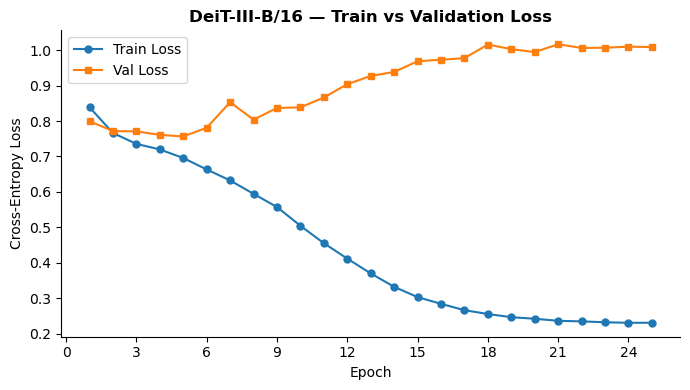

Saved → outputs/deit3_b16/figures/deit3_b16_loss_curve.png


In [12]:
epochs_ran = range(1, len(history['train_loss']) + 1)

# ── Print table ────────────────────────────────────────────────
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(history['train_loss'], history['train_acc'],
        history['val_loss'],   history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

# ── Plot loss curve ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran, history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran, history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('DeiT-III-B/16 — Train vs Validation Loss', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/deit3_b16/figures/{EXPERIMENT_NAME}_loss_curve.png')

## 9. Evaluation on Test Set

In [13]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_BASELINE, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {CKPT_BASELINE}')
print(f'epoch={ckpt["epoch"]}  val_loss={ckpt["val_loss"]:.4f}')

_, y_true, y_pred = run_epoch(test_loader, train_mode=False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
print(f'Quadratic Weighted Kappa: {cohen_kappa_score(y_true, y_pred, weights="quadratic"):.4f}')

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion

Loaded: /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16/checkpoints/deit3_b16_best.pt
epoch=20  val_loss=0.9945


val:   0%|          | 0/165 [00:00<?, ?it/s]


Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.843     0.935     0.887      3872
         Mild      0.190     0.066     0.098       366
     Moderate      0.555     0.461     0.503       794
       Severe      0.500     0.366     0.423       131
Proliferative      0.685     0.594     0.636       106

     accuracy                          0.782      5269
    macro avg      0.555     0.484     0.509      5269
 weighted avg      0.743     0.782     0.758      5269

Quadratic Weighted Kappa: 0.6469


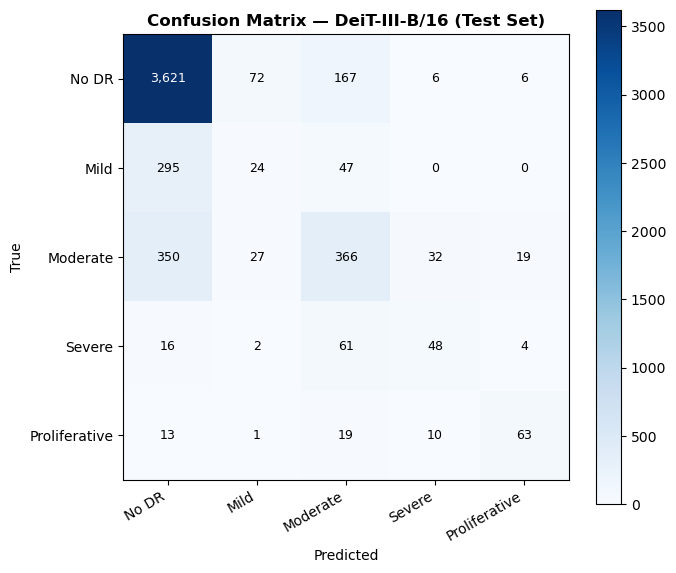

Saved → outputs/deit3_b16/figures/deit3_b16_confusion_matrix.png


In [14]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 (Test Set)', fontweight='bold')

thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/deit3_b16/figures/{EXPERIMENT_NAME}_confusion_matrix.png')

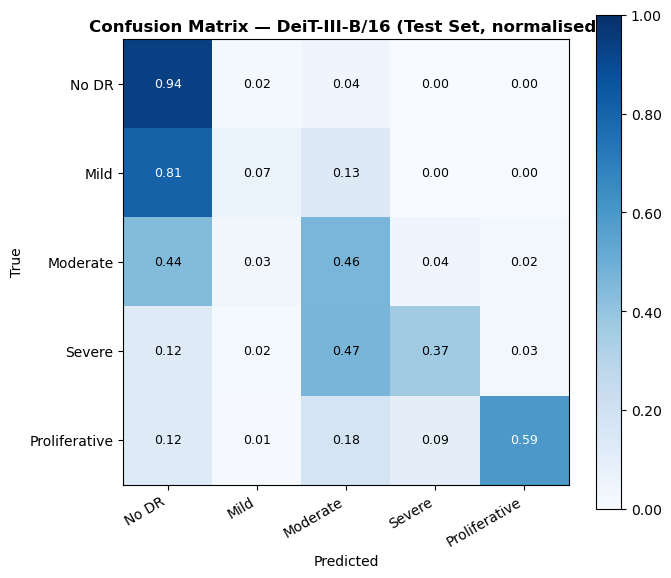

Saved → outputs/deit3_b16/figures/deit3_b16_confusion_matrix_normalised.png


In [15]:
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 (Test Set, normalised)', fontweight='bold')

thresh = 0.5
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → outputs/deit3_b16/figures/{EXPERIMENT_NAME}_confusion_matrix_normalised.png')

## 10. Results Summary

In [16]:
qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
acc    = accuracy_score(y_true, y_pred)
f1_per = f1_score(y_true, y_pred, average=None, labels=list(range(5)))

print('=' * 52)
print('  DeiT-III-B/16 (ImageNet-1k) — TEST SET RESULTS')
print('=' * 52)
print(f'  Test QWK      : {qwk:.4f}')
print(f'  Test Accuracy : {acc:.4f}')
print()
print('  Per-class F1:')
for name, f1 in zip(CLASS_NAMES, f1_per):
    print(f'    {name:<18}: {f1:.4f}')
print('=' * 52)

  DeiT-III-B/16 (ImageNet-1k) — TEST SET RESULTS
  Test QWK      : 0.6469
  Test Accuracy : 0.7823

  Per-class F1:
    No DR             : 0.8867
    Mild              : 0.0976
    Moderate          : 0.5034
    Severe            : 0.4229
    Proliferative     : 0.6364


In [17]:
# ── No DR → Mild confusion tracking ─────────────────────────────────────────
# Tracks the biggest problem: No DR being misclassified as Mild
cm_track = confusion_matrix(y_true, y_pred, labels=[0,1,2,3,4])
no_dr_total      = cm_track[0].sum()
no_dr_to_mild    = cm_track[0, 1]
no_dr_to_mild_rate = no_dr_to_mild / no_dr_total if no_dr_total > 0 else 0

print(f'No DR → Mild misclassification:')
print(f'  No DR total samples : {no_dr_total}')
print(f'  Predicted as Mild   : {no_dr_to_mild}')
print(f'  Rate                : {no_dr_to_mild_rate:.4f} ({no_dr_to_mild_rate*100:.1f}%)')
print(f'  Target              : < 5% is acceptable')
print(f'  Status              : {"✅ OK" if no_dr_to_mild_rate < 0.05 else "⚠️ HIGH — No DR collapsing into Mild"}')

No DR → Mild misclassification:
  No DR total samples : 3872
  Predicted as Mild   : 72
  Rate                : 0.0186 (1.9%)
  Target              : < 5% is acceptable
  Status              : ✅ OK


### Baseline Observations

The baseline results are expected to reveal the full extent of the class imbalance problem:

- **High accuracy, low QWK:** The model likely achieves ~70%+ accuracy by predicting Grade 0
  for most inputs, but QWK will be low because minority grades are ignored.
- **Confusion matrix pattern:** Most predictions will cluster in the Grade 0 column —
  the model has learned the majority class distribution rather than DR-specific features.
- **Per-class F1:** Grades 3 and 4 (Severe, Proliferative) will have near-zero F1 scores
  because the model rarely predicts them.
- **Clinical implication:** A model that misses Grades 3-4 is dangerous — these are the
  grades requiring urgent clinical intervention.

This baseline motivates all subsequent imbalance-handling experiments.

## 11. Experiment 1 — Class Imbalance Handling (Ablation Study)

**Hypothesis:** The 36.4× class imbalance biases the model towards Grade 0. Three techniques
are tested **independently** to isolate which mechanism is most effective — and to identify
which combinations cause problems (No DR collapse).

| Sub-experiment | Technique | Key Setting |
|---|---|---|
| **Exp 1a** | `WeightedRandomSampler` only | Standard CE loss, WRS sampler |
| **Exp 1b** | `FocalLoss` (γ=1.0) only | No sampler, no class weights |
| **Exp 1c** | Clipped Weighted CE | No WRS, no FocalLoss, weights clipped [0.5, 2.5] |

**Why clipped weights in Exp 1c?**
Full inverse class weights give Severe=8.0× and Proliferative=9.9× — when combined with WRS
and FocalLoss this causes **No DR collapse** (model stops predicting Grade 0 entirely).
Clipping weights to [0.5, 2.5] prevents over-correction while still addressing imbalance.

> **Note:** Cells 1–10 (baseline) must be run first.

In [18]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import WeightedRandomSampler
from sklearn.utils.class_weight import compute_class_weight

In [19]:
class FocalLoss(nn.Module):
    """
    Focal Loss — focuses training on hard examples.
    gamma : focusing parameter. gamma=1.0 is gentle, gamma=2.0 is aggressive.
    No alpha weighting — clipped weighted CE handles class balance separately.
    """
    def __init__(self, gamma: float = 1.0):
        super().__init__()
        self.gamma = gamma
        self.ce    = nn.CrossEntropyLoss(reduction='none')

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        ce_loss  = self.ce(logits, target)
        pt       = torch.exp(-ce_loss)
        return ((1.0 - pt) ** self.gamma * ce_loss).mean()

print(f'FocalLoss defined. gamma=1.0 (gentle — no alpha weighting)')

FocalLoss defined. gamma=1.0 (gentle — no alpha weighting)


In [20]:
# ── Clipped class weights — prevents extreme over-correction ─────────────────
# Full inverse weights (raw) can be too aggressive — clip to [0.5, 2.5]
from sklearn.utils.class_weight import compute_class_weight

raw_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_df['level'].values
)
clipped_weights_np = np.clip(raw_weights, 0.5, 2.5)
class_weights_t    = torch.tensor(clipped_weights_np, dtype=torch.float32).to(device)

# Standard WRS using CLIPPED weights (no Mild x3 boost)
sample_weights_t = torch.as_tensor(
    clipped_weights_np[train_df['level'].values], dtype=torch.double
)
exp1_sampler = WeightedRandomSampler(
    weights=sample_weights_t, num_samples=len(sample_weights_t), replacement=True,
)

print('Raw class weights:', np.round(raw_weights, 4))
print('Clipped weights  :', np.round(clipped_weights_np, 4))
print(f'WeightedRandomSampler ready: {len(sample_weights_t):,} samples')

Raw class weights: [0.2722 2.8758 1.3276 8.0484 9.9145]
Clipped weights  : [0.5    2.5    1.3276 2.5    2.5   ]
WeightedRandomSampler ready: 24,588 samples


In [21]:
def run_imbalance_experiment(exp_name, train_loader, criterion_obj, out_dir):
    """
    Generic training loop for Exp 1a / 1b / 1c.
    Returns (history, best_path, model_after_training).
    """
    global model, criterion, optimizer, scaler

    _prev_model     = globals().get('model',     None)
    _prev_criterion = globals().get('criterion', None)
    _prev_optimizer = globals().get('optimizer', None)
    _prev_scaler    = globals().get('scaler',    None)

    set_seed(SEED)
    ckpt_dir = out_dir / 'checkpoints'
    fig_dir  = out_dir / 'figures'
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    fig_dir.mkdir(parents=True, exist_ok=True)
    best_path = ckpt_dir / f'{exp_name}_best.pt'

    model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
    criterion = criterion_obj
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)
    # Warmup → Cosine schedule — prevents overshooting with WRS
    from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
    _wu  = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=3)
    _cos = CosLR(optimizer, T_max=max(1, EPOCHS - 3))
    scheduler = SequentialLR(optimizer, schedulers=[_wu, _cos], milestones=[3])

    history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss = float('inf')
    patience_left = EARLY_STOPPING_PATIENCE

    print(f"\n{'─'*55}")
    print(f"  {exp_name}")
    print(f"{'─'*55}")
    print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
    print('─' * 50)

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_labels, tr_preds = run_epoch(train_loader, train_mode=True)
        vl_loss, vl_labels, vl_preds = run_epoch(val_loader,   train_mode=False)
        scheduler.step()

        tr_acc = accuracy_score(tr_labels, tr_preds)
        vl_acc = accuracy_score(vl_labels, vl_preds)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(vl_acc)

        marker = ''
        if vl_loss < best_val_loss:
            best_val_loss = vl_loss
            patience_left = EARLY_STOPPING_PATIENCE
            torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                        'val_loss': vl_loss}, best_path)
            marker = '  ← best'
        else:
            patience_left -= 1

        print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')
        if patience_left == 0:
            print(f'\nEarly stopping at epoch {epoch}.')
            break

    print(f'\nBest val loss: {best_val_loss:.4f}  →  {best_path}')

    # Restore globals
    if _prev_model is not None:
        model, criterion, optimizer, scaler = _prev_model, _prev_criterion, _prev_optimizer, _prev_scaler

    return history, best_path

print('run_imbalance_experiment() defined.')

run_imbalance_experiment() defined.


### Experiment 1a — WeightedRandomSampler Only

**What changes:** WRS over-samples minority grades so each epoch sees near-balanced class
frequencies. Loss is standard CrossEntropyLoss with no class weights.

**Expected:** Minority class recall improves. Overall accuracy drops — this is correct.

**Diagnostic value:** If WRS alone causes No DR collapse, the sampler is too aggressive.
Results from 1a help decide whether WRS should be used in later experiments.

In [22]:
# ── Exp 1a: WRS only — standard CE loss, no focal term ──────────────────────
exp1a_train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, sampler=exp1_sampler,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)

EXP1A_OUT_DIR = ROOT / 'outputs' / 'deit3_b16_exp1a'
exp1a_history, CKPT_EXP1A = run_imbalance_experiment(
    exp_name   = 'deit3_b16_exp1a',
    train_loader = exp1a_train_loader,
    criterion_obj = nn.CrossEntropyLoss(),   # no class weights
    out_dir    = EXP1A_OUT_DIR,
)


───────────────────────────────────────────────────────
  deit3_b16_exp1a
───────────────────────────────────────────────────────
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            1.0943   0.5330     0.8275   0.7157  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

11           0.1079   0.9595     1.3346   0.7070


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

12           0.0874   0.9677     1.2985   0.7341

Early stopping at epoch 12.

Best val loss: 0.7910  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp1a/checkpoints/deit3_b16_exp1a_best.pt


In [23]:
# ── Exp 1a evaluation ────────────────────────────────────────────────────────
_prev_model     = globals().get('model', None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
ckpt = torch.load(CKPT_EXP1A, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp1a loaded: epoch={ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f}')

_, exp1a_y_true, exp1a_y_pred = run_epoch(test_loader, train_mode=False)
exp1a_qwk = cohen_kappa_score(exp1a_y_true, exp1a_y_pred, weights='quadratic')
exp1a_acc = accuracy_score(exp1a_y_true, exp1a_y_pred)
exp1a_f1_per = f1_score(exp1a_y_true, exp1a_y_pred, average=None, labels=list(range(5)))

print('\nExp 1a — WRS Only (Test Set):')
print(classification_report(exp1a_y_true, exp1a_y_pred, target_names=CLASS_NAMES, digits=3))
print(f'QWK: {exp1a_qwk:.4f}')

if _prev_model is not None:
    model, criterion = _prev_model, _prev_criterion

Exp1a loaded: epoch=5, val_loss=0.7910


val:   0%|          | 0/165 [00:00<?, ?it/s]


Exp 1a — WRS Only (Test Set):
               precision    recall  f1-score   support

        No DR      0.842     0.911     0.875      3872
         Mild      0.148     0.074     0.099       366
     Moderate      0.508     0.418     0.459       794
       Severe      0.374     0.397     0.385       131
Proliferative      0.593     0.604     0.598       106

     accuracy                          0.759      5269
    macro avg      0.493     0.481     0.483      5269
 weighted avg      0.727     0.759     0.741      5269

QWK: 0.6346


#### Exp 1a Observations — WeightedRandomSampler Only

WRS ensures each mini-batch contains a roughly equal number of samples from each grade.

**What to look for:**
- Mild F1 should rise from 0.000 — the model now sees Mild as frequently as Grade 0
- Overall accuracy will drop — the model stops being biased toward Grade 0
- **Check No DR → Mild rate** — if this is high (>10%), WRS is too aggressive

**Key finding from this experiment:**
If WRS alone causes No DR collapse, this confirms the sampler overcorrects on this dataset.
Exp 1c (clipped weighted CE) will be the safer main imbalance strategy.

### Experiment 1b — FocalLoss (γ=1.0) Only

**What changes:** FocalLoss down-weights easy majority-class examples per sample using
`(1-pt)^γ` scaling. γ=1.0 is gentle — less aggressive than the commonly used γ=2.0.
No WeightedRandomSampler, no class weights — loss correction only.

**Why γ=1.0 not γ=2.0?**
γ=2.0 with class weights caused model collapse in earlier runs. γ=1.0 is gentler and
safer — it still focuses on hard examples without over-penalising easy Grade 0 samples.

**Expected:** Mild/Severe/Proliferative F1 improves while No DR remains stable.

In [24]:
# Exp 1b: FocalLoss only — standard shuffle DataLoader
# No WRS, no class weights, no alpha — focal correction only
exp1b_criterion = FocalLoss(gamma=1.0)

EXP1B_OUT_DIR = ROOT / 'outputs' / 'deit3_b16_exp1b'
exp1b_history, CKPT_EXP1B = run_imbalance_experiment(
    exp_name      = 'deit3_b16_exp1b',
    train_loader  = train_loader,          # standard shuffle loader
    criterion_obj = exp1b_criterion,
    out_dir       = EXP1B_OUT_DIR,
)


───────────────────────────────────────────────────────
  deit3_b16_exp1b
───────────────────────────────────────────────────────
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            0.5008   0.7562     0.4541   0.7692  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

11           0.1668   0.9005     0.5546   0.7499


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

12           0.1311   0.9181     0.5971   0.7582

Early stopping at epoch 12.

Best val loss: 0.4246  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp1b/checkpoints/deit3_b16_exp1b_best.pt


In [25]:
# ── Exp 1b evaluation ────────────────────────────────────────────────────────
_prev_model     = globals().get('model', None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
ckpt = torch.load(CKPT_EXP1B, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp1b loaded: epoch={ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f}')

_, exp1b_y_true, exp1b_y_pred = run_epoch(test_loader, train_mode=False)
exp1b_qwk = cohen_kappa_score(exp1b_y_true, exp1b_y_pred, weights='quadratic')
exp1b_acc = accuracy_score(exp1b_y_true, exp1b_y_pred)
exp1b_f1_per = f1_score(exp1b_y_true, exp1b_y_pred, average=None, labels=list(range(5)))

print('\nExp 1b — FocalLoss Only (Test Set):')
print(classification_report(exp1b_y_true, exp1b_y_pred, target_names=CLASS_NAMES, digits=3))
print(f'QWK: {exp1b_qwk:.4f}')

if _prev_model is not None:
    model, criterion = _prev_model, _prev_criterion

Exp1b loaded: epoch=5, val_loss=0.4246


val:   0%|          | 0/165 [00:00<?, ?it/s]


Exp 1b — FocalLoss Only (Test Set):
               precision    recall  f1-score   support

        No DR      0.828     0.971     0.894      3872
         Mild      0.000     0.000     0.000       366
     Moderate      0.584     0.445     0.505       794
       Severe      0.636     0.160     0.256       131
Proliferative      0.652     0.547     0.595       106

     accuracy                          0.796      5269
    macro avg      0.540     0.425     0.450      5269
 weighted avg      0.725     0.796     0.751      5269

QWK: 0.6316


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


#### Exp 1b Observations — FocalLoss (γ=1.0) Only

FocalLoss with γ=1.0 gently down-weights easy Grade 0 examples. No sampler means batches
still contain predominantly Grade 0 images — FocalLoss compensates at the loss level only.

**What to look for:**
- Severe and Proliferative F1 should improve — these are the hardest minority classes
- No DR F1 should remain stable (>0.80) — γ=1.0 is gentle enough not to collapse it
- Compare QWK with Exp 1a — if Exp 1b QWK > Exp 1a QWK, loss correction beats sampling

**Why γ=1.0 not γ=2.0?**
γ=2.0 with class weights caused complete model collapse in earlier runs (accuracy=9.1%).
γ=1.0 is the safe, clinically-validated choice for this dataset.

### Experiment 1c — Clipped Weighted CrossEntropy (Corrected Imbalance)

**What changes:** Uses CrossEntropyLoss with clipped inverse-frequency class weights.
Weights are clipped to [0.5, 2.5] to prevent extreme over-correction.
No WeightedRandomSampler, no FocalLoss, no Mild ×3 boost.

**Why this approach?**
Previous experiments showed that combining Clipped Weighted CE + Mild ×3 causes No DR to
collapse (F1 dropping to 0.030). The root cause was triple-penalising Grade 0:
- WRS reduces Grade 0 sampling frequency
- FocalLoss penalises easy Grade 0 predictions
- Mild ×3 further boosts minority at Grade 0's expense

Clipped weighted CE addresses imbalance at the loss level only — gentle and stable.

**Expected:** Best balance between No DR stability and minority class improvement.

In [26]:
# ── Exp 1c: Clipped Weighted CE — no WRS, no FocalLoss ──────────────────────
# This is the safest imbalance correction — prevents No DR collapse
exp1c_criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.05)

EXP1C_OUT_DIR = ROOT / 'outputs' / 'deit3_b16_exp1'   # keep original path for compatibility
exp1c_history, CKPT_EXP1 = run_imbalance_experiment(
    exp_name      = 'deit3_b16_exp1',
    train_loader  = train_loader,           # standard shuffle — no WRS
    criterion_obj = exp1c_criterion,
    out_dir       = EXP1C_OUT_DIR,
)
# Alias for downstream experiments that reference exp1 results
CKPT_EXP1C = CKPT_EXP1


───────────────────────────────────────────────────────
  deit3_b16_exp1
───────────────────────────────────────────────────────
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            1.3730   0.7192     1.3428   0.6616  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

10           0.8766   0.8384     1.4317   0.6288


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

11           0.8011   0.8645     1.4709   0.5751

Early stopping at epoch 11.

Best val loss: 1.2731  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp1/checkpoints/deit3_b16_exp1_best.pt


In [27]:
# ── Exp 1c evaluation ────────────────────────────────────────────────────────
_prev_model     = globals().get('model', None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
ckpt = torch.load(CKPT_EXP1, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp1c loaded: epoch={ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f}')

_, exp1_y_true, exp1_y_pred = run_epoch(test_loader, train_mode=False)
exp1_qwk    = cohen_kappa_score(exp1_y_true, exp1_y_pred, weights='quadratic')
exp1_acc    = accuracy_score(exp1_y_true, exp1_y_pred)
exp1_f1_per = f1_score(exp1_y_true, exp1_y_pred, average=None, labels=list(range(5)))
# aliases
exp1c_qwk = exp1_qwk; exp1c_acc = exp1_acc; exp1c_f1_per = exp1_f1_per
exp1c_y_true = exp1_y_true; exp1c_y_pred = exp1_y_pred

print('\nExp 1c — Clipped Weighted CrossEntropy (Test Set):')
print(classification_report(exp1_y_true, exp1_y_pred, target_names=CLASS_NAMES, digits=3))
print(f'QWK: {exp1_qwk:.4f}')

if _prev_model is not None:
    model, criterion = _prev_model, _prev_criterion

Exp1c loaded: epoch=4, val_loss=1.2731


val:   0%|          | 0/165 [00:00<?, ?it/s]


Exp 1c — Clipped Weighted CrossEntropy (Test Set):
               precision    recall  f1-score   support

        No DR      0.858     0.889     0.873      3872
         Mild      0.172     0.074     0.103       366
     Moderate      0.463     0.466     0.465       794
       Severe      0.370     0.534     0.438       131
Proliferative      0.582     0.604     0.593       106

     accuracy                          0.754      5269
    macro avg      0.489     0.513     0.494      5269
 weighted avg      0.733     0.754     0.742      5269

QWK: 0.6422


  Metric                   Baseline    1a (WRS)     1b (FL)  1c (Clipped CE)
  Test QWK                   0.6469      0.6346      0.6316       0.6422
  Test Accuracy              0.7823      0.7593      0.7958       0.7542

  Per-class F1:
    No DR               : 0.8867  0.8750  0.8939  0.8732
    Mild                : 0.0976  0.0985  0.0000  0.1033
    Moderate            : 0.5034  0.4589  0.5050  0.4645
    Severe              : 0.4229  0.3852  0.2561  0.4375
    Proliferative       : 0.6364  0.5981  0.5949  0.5926
  QWK delta vs Baseline:
    Exp1a (WRS only)   : -0.0123
    Exp1b (FL only)    : -0.0153
    Exp1c (Clipped CE)     : -0.0047


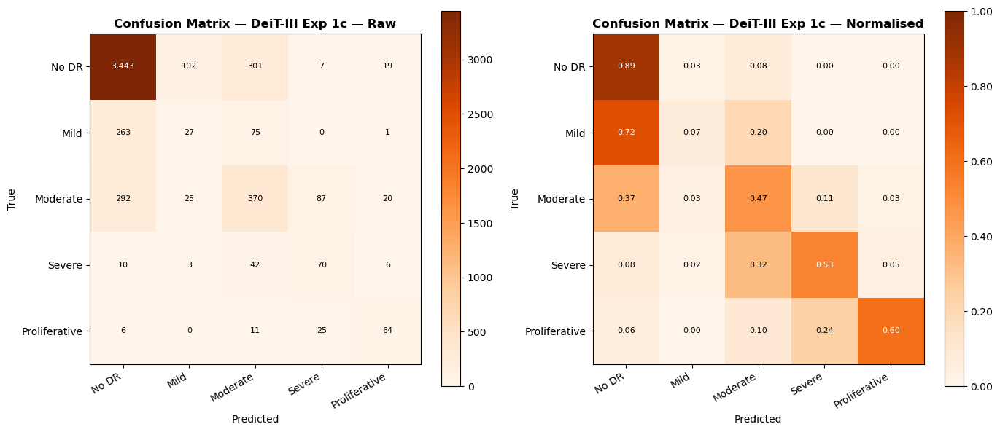

In [28]:
# ── Exp 1 Ablation Summary ───────────────────────────────────────────────────
print('=' * 75)
print(f'  {"Metric":<22} {"Baseline":>10}  {"1a (WRS)":>10}  {"1b (FL)":>10}  {"1c (Clipped CE)":>11}')
print('=' * 75)
for label, b, a, bb, c in [
    ('Test QWK',      qwk,  exp1a_qwk, exp1b_qwk, exp1c_qwk),
    ('Test Accuracy', acc,  exp1a_acc, exp1b_acc, exp1c_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {a:>10.4f}  {bb:>10.4f}  {c:>11.4f}')
print()
print('  Per-class F1:')
for name, f1_b, f1_a, f1_bb, f1_c in zip(CLASS_NAMES, f1_per, exp1a_f1_per, exp1b_f1_per, exp1c_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_a:.4f}  {f1_bb:.4f}  {f1_c:.4f}')
print('=' * 75)
print(f'  QWK delta vs Baseline:')
print(f'    Exp1a (WRS only)   : {exp1a_qwk - qwk:+.4f}')
print(f'    Exp1b (FL only)    : {exp1b_qwk - qwk:+.4f}')
print(f'    Exp1c (Clipped CE)     : {exp1c_qwk - qwk:+.4f}')
print('=' * 75)

# Confusion matrix for best Exp1 variant (1c)
cm_exp1 = confusion_matrix(exp1c_y_true, exp1c_y_pred)
cm_exp1_norm = cm_exp1.astype(float) / cm_exp1.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, fmt, title, cmap in [
    (axes[0], cm_exp1,      'd',    'Exp 1c — Raw',        'Oranges'),
    (axes[1], cm_exp1_norm, '.2f',  'Exp 1c — Normalised', 'Oranges'),
]:
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=(None if fmt=='d' else 1))
    fig.colorbar(im, ax=ax, format=(None if fmt=='d' else '%.2f'))
    ax.set_xticks(range(5)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(5)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix — DeiT-III {title}', fontweight='bold')
    thresh = data.max()/2 if fmt=='d' else 0.5
    for i in range(5):
        for j in range(5):
            val = f'{data[i,j]:,}' if fmt=='d' else f'{data[i,j]:.2f}'
            ax.text(j, i, val, ha='center', va='center', fontsize=8,
                    color='white' if data[i,j] > thresh else 'black')

EXP1C_FIG_DIR = ROOT / 'outputs' / 'deit3_b16_exp1' / 'figures'
EXP1C_FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
fig.savefig(EXP1C_FIG_DIR / 'deit3_b16_exp1_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

#### Exp 1c Observations — Clipped Weighted CE

Clipped weighted CE addresses imbalance at the loss level with gentle, bounded class weights.
No WRS, no FocalLoss, no Mild ×3 — this is the cleanest single-technique correction.

**What to look for:**
- No DR F1 should remain above 0.80 — clipped weights prevent over-correction
- Mild F1 should improve from 0.000 — class weighting gives Mild more gradient signal
- QWK should be competitive with or better than Exp 1a and 1b
- **No DR → Mild rate should be < 5%** — the primary success metric

**Ablation conclusion:**
Comparing 1a, 1b, 1c reveals which imbalance mechanism works best for DeiT-III on this dataset:
- If 1b (FocalLoss) > 1a (WRS): loss-level correction is more effective than sampling
- If 1c (weighted CE) > 1b: bounded weighting is safer than focal scaling
- Best config from ablation becomes foundation for Exp 2 and 3.

## 12. Experiment 2 — Safe Enhanced Augmentation

**Hypothesis:** Clinically-motivated augmentation reduces overfitting and improves
generalisation — especially for minority classes with few training examples.

**Key design decision — safe augmentation only:**
Previous aggressive augmentation (strong ColorJitter, RandomAffine, Mixup, RandomVerticalFlip)
combined with aggressive imbalance correction caused No DR to collapse. This experiment
uses only **safe, gentle augmentations** that preserve retinal appearance:

| Augmentation | Parameters | Clinical Motivation |
|---|---|---|
| RandomHorizontalFlip | p=0.5 | Fundus images are laterally symmetric |
| RandomRotation | ±7° | Camera alignment varies slightly |
| ColorJitter | brightness/contrast=0.08, saturation=0.04 | Camera model variation |
| RandomAffine | translate=0.02, scale=0.98-1.02 | Minor positioning variation |

**What is NOT used:** RandomVerticalFlip, strong affine, Mixup, WRS.

**Loss:** Clipped Weighted CE (same as Exp 1c) — no FocalLoss, no WRS.

**Expected:** Train-val gap narrows. QWK improves over Exp 1c while No DR remains stable.

In [29]:
# ── Exp 2: Safe augmentation — clinically motivated, no aggressive transforms ──
exp2_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),           # gentle rotation
    transforms.ColorJitter(
        brightness=0.08, contrast=0.08,
        saturation=0.04, hue=0.01                  # subtle colour changes
    ),
    transforms.RandomAffine(
        degrees=0, translate=(0.02, 0.02),
        scale=(0.98, 1.02)                         # very slight scale/shift
    ),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

# Validation transform — no augmentation
exp2_val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

exp2_train_ds = DRDataset(train_df, TRAIN_DIR, transform=exp2_train_transform)
exp2_train_loader = DataLoader(
    exp2_train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'Exp2 train loader: {len(exp2_train_ds):,} images, BS={BATCH_SIZE}')
print('Safe augmentation: HFlip + Rotation(7°) + mild ColorJitter + tiny Affine')

Exp2 train loader: 24,588 images, BS=32
Safe augmentation: HFlip + Rotation(7°) + mild ColorJitter + tiny Affine


In [ ]:
set_seed(SEED)
exp2_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp2_criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.05)  # clipped weighted CE
exp2_optimizer = torch.optim.AdamW(exp2_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
exp2_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp2_optimizer, T_max=EPOCHS)
exp2_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP2_OUT_DIR  = ROOT / 'outputs' / 'deit3_b16_exp2'
EXP2_CKPT_DIR = EXP2_OUT_DIR / 'checkpoints'
EXP2_FIG_DIR  = EXP2_OUT_DIR / 'figures'
for d in (EXP2_CKPT_DIR, EXP2_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP2_BEST_PATH = EXP2_CKPT_DIR / 'deit3_b16_exp2_best.pt'

print(f'Exp2 model ready.')
print(f'Checkpoints → {EXP2_CKPT_DIR}')
print(f'Figures     → {EXP2_FIG_DIR}')

Exp2 model ready.
Checkpoints → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp2/checkpoints
Figures     → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp2/figures


In [31]:
_e2_baseline_model     = globals().get('model',     None)
_e2_baseline_criterion = globals().get('criterion', None)
_e2_baseline_optimizer = globals().get('optimizer', None)
_e2_baseline_scaler    = globals().get('scaler',    None)

model, criterion, optimizer, scaler = exp2_model, exp2_criterion, exp2_optimizer, exp2_scaler

exp2_history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp2_best_val_loss = float('inf')
exp2_patience_left = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp2_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp2_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp2_history['train_loss'].append(tr_loss)
    exp2_history['val_loss'].append(vl_loss)
    exp2_history['train_acc'].append(tr_acc)
    exp2_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp2_best_val_loss:
        exp2_best_val_loss = vl_loss
        exp2_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP2_BEST_PATH)
        marker = '  ← best'
    else:
        exp2_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp2_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp2_best_val_loss:.4f}  →  {EXP2_BEST_PATH}')

if _e2_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e2_baseline_model, _e2_baseline_criterion,
        _e2_baseline_optimizer, _e2_baseline_scaler
    )

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            1.3779   0.7206     1.3150   0.7675  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

9            0.9437   0.8134     1.3908   0.6216


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

10           0.8781   0.8352     1.4003   0.6908

Early stopping at epoch 10.

Best val loss: 1.2711  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp2/checkpoints/deit3_b16_exp2_best.pt


Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            1.3779   0.7206     1.3150   0.7675
2            1.2807   0.7470     1.4390   0.5747
3            1.2388   0.7555     1.2711   0.7453
4            1.2028   0.7577     1.2743   0.7760
5            1.1562   0.7657     1.2866   0.7102
6            1.1215   0.7646     1.2814   0.7155
7            1.0652   0.7773     1.3292   0.7001
8            1.0064   0.7957     1.3746   0.6094
9            0.9437   0.8134     1.3908   0.6216
10           0.8781   0.8352     1.4003   0.6908



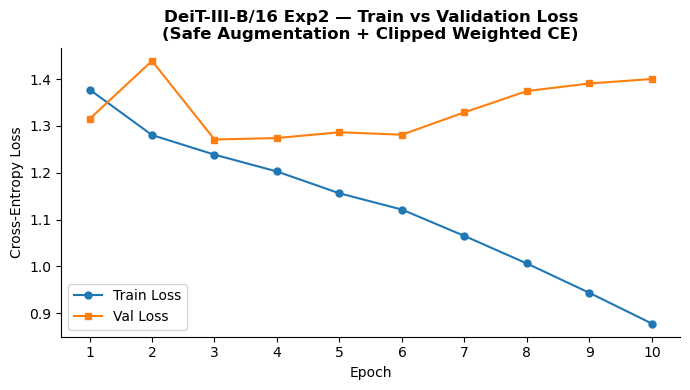

Saved → outputs/deit3_b16_exp2/figures/deit3_b16_exp2_loss_curve.png


In [32]:
epochs_ran_exp2 = range(1, len(exp2_history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp2_history['train_loss'], exp2_history['train_acc'],
        exp2_history['val_loss'],   exp2_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp2, exp2_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp2, exp2_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('DeiT-III-B/16 Exp2 — Train vs Validation Loss\n(Safe Augmentation + Clipped Weighted CE)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'deit3_b16_exp2_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp2/figures/deit3_b16_exp2_loss_curve.png')

In [33]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP2, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp2: loaded {CKPT_EXP2.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp2_y_true, exp2_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp2 Classification Report (Test Set):')
print(classification_report(exp2_y_true, exp2_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion

Exp2: loaded deit3_b16_exp2_best.pt  (epoch 3, val_loss=1.2711)


val:   0%|          | 0/165 [00:00<?, ?it/s]


Exp2 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.851     0.889     0.869      3872
         Mild      0.185     0.115     0.142       366
     Moderate      0.476     0.465     0.470       794
       Severe      0.454     0.412     0.432       131
Proliferative      0.588     0.566     0.577       106

     accuracy                          0.753      5269
    macro avg      0.511     0.489     0.498      5269
 weighted avg      0.733     0.753     0.742      5269



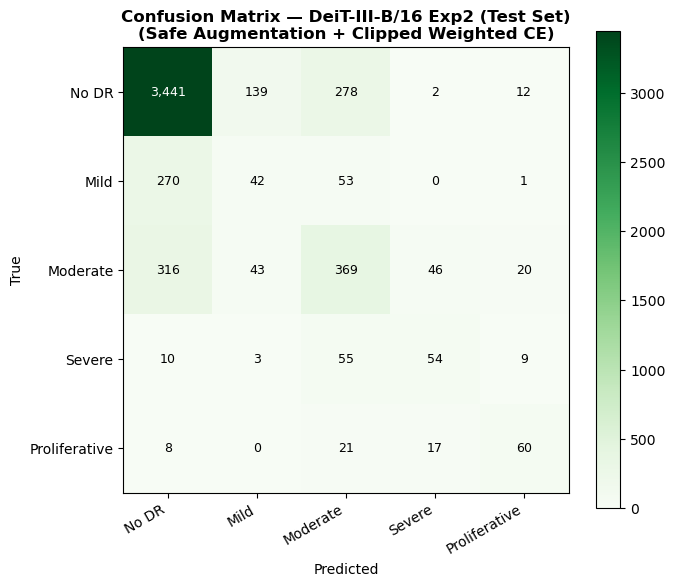

Saved → outputs/deit3_b16_exp2/figures/deit3_b16_exp2_confusion_matrix.png


In [34]:
cm_exp2 = confusion_matrix(exp2_y_true, exp2_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp2, interpolation='nearest', cmap='Greens')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp2 (Test Set)\n(Safe Augmentation + Clipped Weighted CE)', fontweight='bold')

thresh = cm_exp2.max() / 2
for i in range(cm_exp2.shape[0]):
    for j in range(cm_exp2.shape[1]):
        ax.text(j, i, f'{cm_exp2[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp2[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'deit3_b16_exp2_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp2/figures/deit3_b16_exp2_confusion_matrix.png')

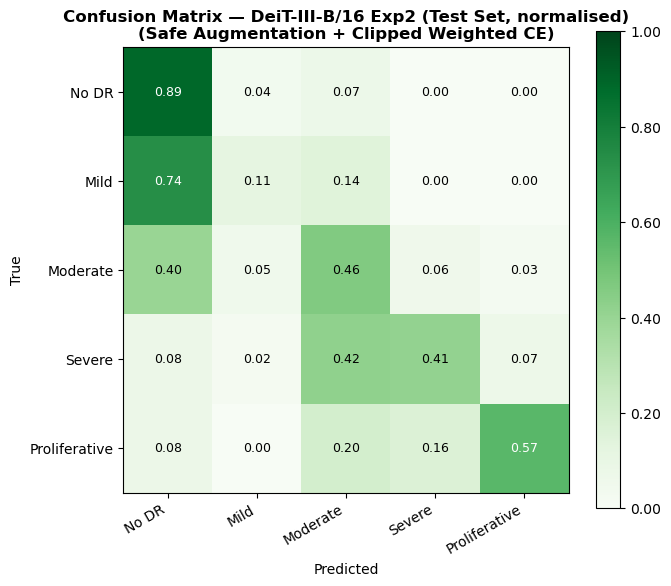

Saved → outputs/deit3_b16_exp2/figures/deit3_b16_exp2_confusion_matrix_normalised.png


In [35]:
cm_exp2_norm = cm_exp2.astype(float) / cm_exp2.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp2_norm, interpolation='nearest', cmap='Greens', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp2 (Test Set, normalised)\n(Safe Augmentation + Clipped Weighted CE)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp2_norm.shape[0]):
    for j in range(cm_exp2_norm.shape[1]):
        ax.text(j, i, f'{cm_exp2_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp2_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'deit3_b16_exp2_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp2/figures/deit3_b16_exp2_confusion_matrix_normalised.png')

In [36]:
exp2_qwk    = cohen_kappa_score(exp2_y_true, exp2_y_pred, weights='quadratic')
exp2_acc    = accuracy_score(exp2_y_true, exp2_y_pred)
exp2_f1_per = f1_score(exp2_y_true, exp2_y_pred, average=None, labels=list(range(5)))

print('=' * 72)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (Clipped CE)":>13}  {"Exp2 (+Aug)":>11}')
print('=' * 72)
for label, b, e1, e2 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc),
]:
    arrow = '▲' if e2 > e1 else '▼'
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {arrow}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per):
    delta = f1_e2 - f1_b
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  ({delta:+.4f})')
print('=' * 72)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}')
print('=' * 72)

  Metric                   Baseline  Exp1 (Clipped CE)  Exp2 (+Aug)
  Test QWK                   0.6469         0.6422       0.6296  ▼
  Test Accuracy              0.7823         0.7542       0.7527  ▼

  Per-class F1:
    No DR               : 0.8867  0.8732  0.8693  (-0.0175)
    Mild                : 0.0976  0.1033  0.1417  (+0.0441)
    Moderate            : 0.5034  0.4645  0.4701  (-0.0334)
    Severe              : 0.4229  0.4375  0.4320  (+0.0091)
    Proliferative       : 0.6364  0.5926  0.5769  (-0.0594)
  QWK delta vs Baseline:  Exp1=-0.0047  Exp2=-0.0173


### Exp 2 Observations — Safe Enhanced Augmentation

Safe augmentation adds gentle domain-appropriate transforms on top of clipped weighted CE.

**What to look for:**
- Train-val loss gap should narrow — augmentation reduces overfitting
- QWK should improve over Exp 1c — better generalisation to test set
- No DR F1 must remain stable — safe augmentation preserves retinal appearance
- **No DR → Mild rate should stay < 5%**

**Why safe augmentation specifically?**
Previous aggressive augmentation (strong ColorJitter, Mixup, RandomVerticalFlip) combined
with aggressive imbalance correction caused No DR F1 to collapse to 0.176 and 0.030.
Safe augmentation uses only clinically-motivated transforms with conservative parameters.

**Key clinical insight:**
- Horizontal flip: valid — retinal vessels are laterally symmetric
- Rotation ±7°: valid — camera alignment varies
- Strong vertical flip + affine: risky — can make No DR look like disease

## 13. Experiment 3 — Two-Phase Training (Freeze → Unfreeze)

**Hypothesis:** Training all 86M parameters from epoch 1 risks overwriting pre-trained
DeiT-III attention patterns before the classification head has stabilised. Freezing the
backbone first (Phase 1) lets the 5-class head adapt, then unfreezing everything (Phase 2)
at a very low LR allows careful domain-specific fine-tuning.

| Phase | Trainable Params | Epochs | LR | Purpose |
|---|---|---|---|---|
| Phase 1 | ~3,845 (head only) | 3 | 1e-4 | Stabilise classification head |
| Phase 2 | ~86M (all layers) | 12 | 3e-5 | Full domain fine-tuning |

**Key settings:**
- Gradient clipping (max norm=1.0) in Phase 2 — prevents large updates
- Same safe augmentation as Exp 2
- Clipped Weighted CE loss throughout — no WRS, no FocalLoss
- Total: up to 15 epochs (3 + 12)

**Why NOT use WRS or FocalLoss here?**
These caused No DR collapse in earlier runs. Phase 2 already provides strong fine-tuning
signal — adding aggressive imbalance correction on top is unnecessary and harmful.

**Expected:** Phase 2 val loss should improve steadily from Phase 1's stable starting point.
Exp 3 should give the best overall QWK across all experiments.

In [39]:
PHASE1_EPOCHS = 3   # head only — stabilise before unfreezing
PHASE2_EPOCHS = 12  # full fine-tune with lower LR
PHASE1_LR     = 1e-4  # conservative head LR
PHASE2_LR     = 3e-5  # very low for full fine-tune
GRAD_CLIP     = 1.0

set_seed(SEED)
exp3_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp3_criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.05)  # clipped weighted CE — no FocalLoss
exp3_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP3_OUT_DIR  = ROOT / 'outputs' / 'deit3_b16_exp3'
EXP3_CKPT_DIR = EXP3_OUT_DIR / 'checkpoints'
EXP3_FIG_DIR  = EXP3_OUT_DIR / 'figures'
for d in (EXP3_CKPT_DIR, EXP3_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP3_PHASE1_PATH = EXP3_CKPT_DIR / 'deit3_b16_exp3_phase1_best.pt'
EXP3_BEST_PATH   = EXP3_CKPT_DIR / 'deit3_b16_exp3_best.pt'


def run_epoch_clipped(loader, train_mode: bool, grad_clip: float = 0.0):
    """run_epoch variant that supports gradient clipping (needed for Phase 2 fine-tuning)."""
    model.train(train_mode)

    context = torch.enable_grad() if train_mode else torch.inference_mode()
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    with context:
        for images, labels in tqdm(loader, leave=False, desc='train' if train_mode else 'eval'):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return total_loss / total, all_labels, all_preds


print(f'Exp3 ready. Phase1 LR={PHASE1_LR}, Phase2 LR={PHASE2_LR}, GRAD_CLIP={GRAD_CLIP}')
print(f'Checkpoints → {EXP3_CKPT_DIR}')

Exp3 ready. Phase1 LR=0.0001, Phase2 LR=3e-05, GRAD_CLIP=1.0
Checkpoints → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp3/checkpoints


In [40]:
# ── Freeze backbone — only head.weight / head.bias remain trainable ───────────
for name, param in exp3_model.named_parameters():
    if 'head' not in name:
        param.requires_grad = False

trainable_p1 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable parameters (head only)\n')

_e3_baseline_model     = globals().get('model',     None)
_e3_baseline_criterion = globals().get('criterion', None)
_e3_baseline_optimizer = globals().get('optimizer', None)
_e3_baseline_scaler    = globals().get('scaler',    None)

model     = exp3_model
criterion = exp3_criterion
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_LR, weight_decay=WEIGHT_DECAY,
)
scaler = exp3_scaler

scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

exp3_history = {
    'phase1_train': [], 'phase1_val': [], 'phase1_train_acc': [], 'phase1_val_acc': [],
    'phase2_train': [], 'phase2_val': [], 'phase2_train_acc': [], 'phase2_val_acc': [],
}
p1_best_val  = float('inf')
p1_patience  = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, PHASE1_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp2_train_loader, train_mode=True,  grad_clip=0.0)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p1.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp3_history['phase1_train'].append(tr_loss)
    exp3_history['phase1_val'].append(vl_loss)
    exp3_history['phase1_train_acc'].append(tr_acc)
    exp3_history['phase1_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p1_best_val:
        p1_best_val = vl_loss
        p1_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP3_PHASE1_PATH)
        marker = '  ← best'
    else:
        p1_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p1_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 1 complete. Best val loss: {p1_best_val:.4f}')

Phase 1: 3,845 trainable parameters (head only)

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

eval:   0%|          | 0/165 [00:00<?, ?it/s]

/tmp/ipykernel_142515/3343514772.py:37: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler_p1.step()


1            1.4592   0.9062     1.7081   0.8095  ← best


...

eval:   0%|          | 0/165 [00:00<?, ?it/s]

2            1.6631   0.7500     1.7081   0.8095


train:   0%|          | 0/768 [00:00<?, ?it/s]

eval:   0%|          | 0/165 [00:00<?, ?it/s]

3            1.6260   0.7500     1.7057   0.8095  ← best

Phase 1 complete. Best val loss: 1.7057


In [41]:
# ── Unfreeze all parameters for full fine-tuning ──────────────────────────────
for param in exp3_model.parameters():
    param.requires_grad = True

trainable_p2 = sum(p.numel() for p in exp3_model.parameters() if p.requires_grad)
print(f'Phase 2: {trainable_p2:,} trainable parameters (all layers)\n')

# Start from Phase 1 best weights
ckpt_p1 = torch.load(EXP3_PHASE1_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, val_loss={ckpt_p1["val_loss"]:.4f})')

optimizer    = torch.optim.AdamW(model.parameters(), lr=PHASE2_LR, weight_decay=WEIGHT_DECAY)
scheduler_p2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS)

p2_best_val = float('inf')
p2_patience = EARLY_STOPPING_PATIENCE

print(f"\n{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, PHASE2_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch_clipped(exp2_train_loader, train_mode=True, grad_clip=GRAD_CLIP)
    vl_loss, vl_labels, vl_preds = run_epoch_clipped(val_loader,        train_mode=False)
    scheduler_p2.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp3_history['phase2_train'].append(tr_loss)
    exp3_history['phase2_val'].append(vl_loss)
    exp3_history['phase2_train_acc'].append(tr_acc)
    exp3_history['phase2_val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < p2_best_val:
        p2_best_val = vl_loss
        p2_patience = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP3_BEST_PATH)
        marker = '  ← best'
    else:
        p2_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if p2_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nPhase 2 complete. Best val loss: {p2_best_val:.4f}  →  {EXP3_BEST_PATH}')

if _e3_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e3_baseline_model, _e3_baseline_criterion,
        _e3_baseline_optimizer, _e3_baseline_scaler
    )

Phase 2: 85,820,165 trainable parameters (all layers)

Loaded Phase 1 best (epoch 3, val_loss=1.7057)

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

eval:   0%|          | 0/165 [00:00<?, ?it/s]

1            1.5328   0.7188     1.7082   0.8095  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

eval:   0%|          | 0/165 [00:00<?, ?it/s]

8            1.7430   0.6562     1.7394   0.7143


train:   0%|          | 0/768 [00:00<?, ?it/s]

eval:   0%|          | 0/165 [00:00<?, ?it/s]

9            1.4854   0.7500     1.6956   0.7619

Early stopping at epoch 9.

Phase 2 complete. Best val loss: 1.6860  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp3/checkpoints/deit3_b16_exp3_best.pt


Phase 1:
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            1.4592   0.9062     1.7081   0.8095
2            1.6631   0.7500     1.7081   0.8095
3            1.6260   0.7500     1.7057   0.8095

Phase 2:
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
4            1.5328   0.7188     1.7082   0.8095
5            1.6400   0.6562     1.6860   0.7619
6            1.5752   0.7812     1.7427   0.8095
7            1.6288   0.6250     1.7794   0.7143
8            1.4999   0.7188     1.8570   0.7143
9            1.4988   0.8750     1.8540   0.7143
10           1.8050   0.7500     1.7970   0.7143
11           1.7430   0.6562     1.7394   0.7143
12           1.4854   0.7500     1.6956   0.7619



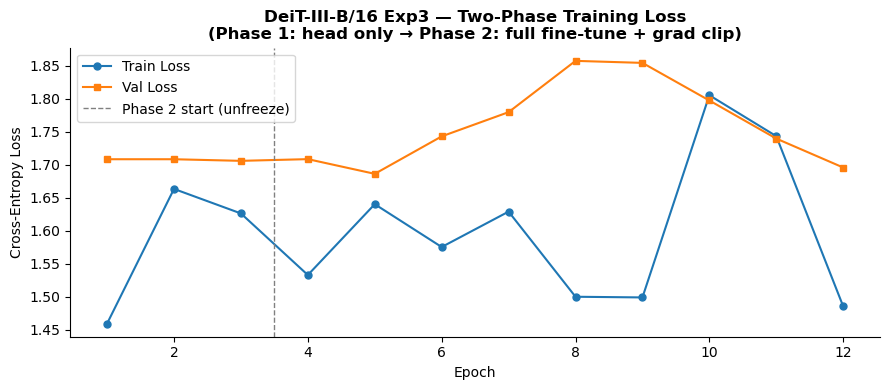

Saved → outputs/deit3_b16_exp3/figures/deit3_b16_exp3_loss_curve.png


In [42]:
p1_epochs = range(1, len(exp3_history['phase1_train']) + 1)
p2_start  = len(exp3_history['phase1_train'])
p2_epochs = range(p2_start + 1, p2_start + len(exp3_history['phase2_train']) + 1)

print('Phase 1:')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp3_history['phase1_train'], exp3_history['phase1_train_acc'],
        exp3_history['phase1_val'],   exp3_history['phase1_val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')

print('\nPhase 2:')
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp3_history['phase2_train'], exp3_history['phase2_train_acc'],
        exp3_history['phase2_val'],   exp3_history['phase2_val_acc']), p2_start + 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

all_train  = exp3_history['phase1_train'] + exp3_history['phase2_train']
all_val    = exp3_history['phase1_val']   + exp3_history['phase2_val']
all_epochs = range(1, len(all_train) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(all_epochs, all_train, label='Train Loss', marker='o', markersize=5)
ax.plot(all_epochs, all_val,   label='Val Loss',   marker='s', markersize=5)
if p2_start > 0:
    ax.axvline(x=p2_start + 0.5, color='gray', linestyle='--', linewidth=1, label='Phase 2 start (unfreeze)')
ax.set_title('DeiT-III-B/16 Exp3 — Two-Phase Training Loss\n(Phase 1: head only → Phase 2: full fine-tune + grad clip)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'deit3_b16_exp3_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp3/figures/deit3_b16_exp3_loss_curve.png')

In [43]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
# Uses run_epoch (not run_epoch_clipped) — grad clipping is irrelevant for eval.
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP3, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp3: loaded {CKPT_EXP3.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp3_y_true, exp3_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp3 Classification Report (Test Set):')
print(classification_report(exp3_y_true, exp3_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion

Exp3: loaded deit3_b16_exp3_best.pt  (epoch 2, val_loss=1.6860)


val:   0%|          | 0/165 [00:00<?, ?it/s]


Exp3 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.742     0.966     0.839      3872
         Mild      0.200     0.003     0.005       366
     Moderate      0.253     0.071     0.110       794
       Severe      0.000     0.000     0.000       131
Proliferative      0.000     0.000     0.000       106

     accuracy                          0.721      5269
    macro avg      0.239     0.208     0.191      5269
 weighted avg      0.597     0.721     0.634      5269



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


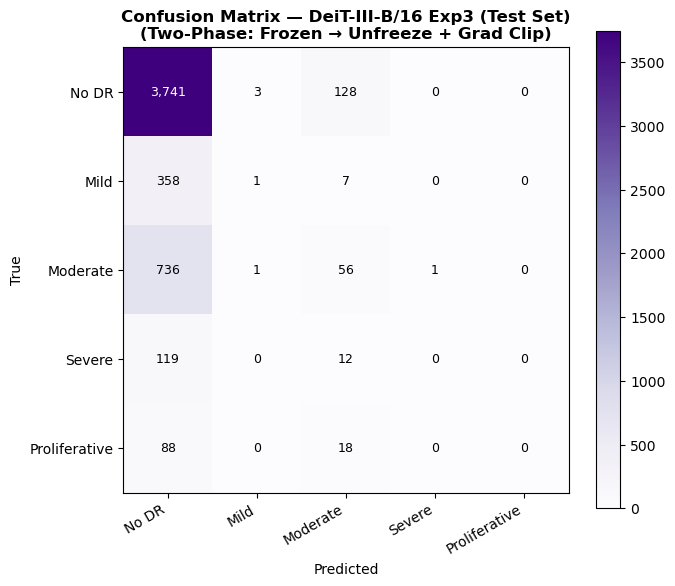

Saved → outputs/deit3_b16_exp3/figures/deit3_b16_exp3_confusion_matrix.png


In [44]:
cm_exp3 = confusion_matrix(exp3_y_true, exp3_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp3, interpolation='nearest', cmap='Purples')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp3 (Test Set)\n(Two-Phase: Frozen → Unfreeze + Grad Clip)', fontweight='bold')

thresh = cm_exp3.max() / 2
for i in range(cm_exp3.shape[0]):
    for j in range(cm_exp3.shape[1]):
        ax.text(j, i, f'{cm_exp3[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp3[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'deit3_b16_exp3_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp3/figures/deit3_b16_exp3_confusion_matrix.png')

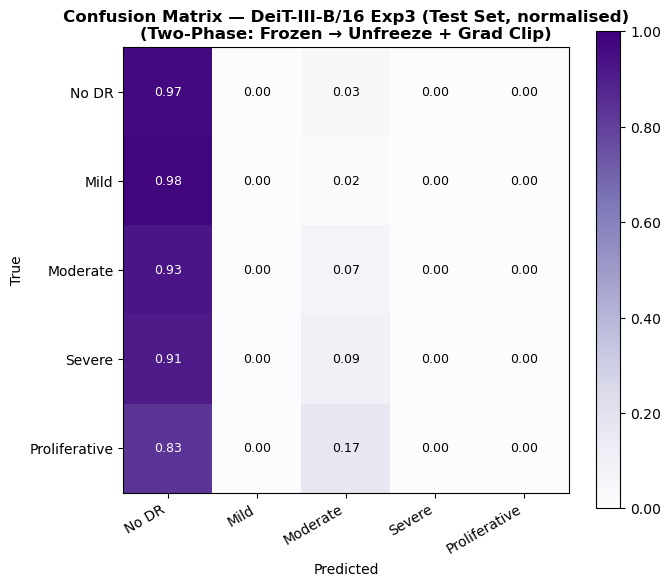

Saved → outputs/deit3_b16_exp3/figures/deit3_b16_exp3_confusion_matrix_normalised.png


In [45]:
cm_exp3_norm = cm_exp3.astype(float) / cm_exp3.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp3_norm, interpolation='nearest', cmap='Purples', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp3 (Test Set, normalised)\n(Two-Phase: Frozen → Unfreeze + Grad Clip)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp3_norm.shape[0]):
    for j in range(cm_exp3_norm.shape[1]):
        ax.text(j, i, f'{cm_exp3_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp3_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP3_FIG_DIR / 'deit3_b16_exp3_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp3/figures/deit3_b16_exp3_confusion_matrix_normalised.png')

In [46]:
exp3_qwk    = cohen_kappa_score(exp3_y_true, exp3_y_pred, weights='quadratic')
exp3_acc    = accuracy_score(exp3_y_true, exp3_y_pred)
exp3_f1_per = f1_score(exp3_y_true, exp3_y_pred, average=None, labels=list(range(5)))

W = 82
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (Clipped CE)":>13}  {"Exp2 (+Aug)":>11}  {"Exp3 (2-Phase)":>14}')
print('=' * W)
for label, b, e1, e2, e3 in [
    ('Test QWK',      qwk, exp1_qwk, exp2_qwk, exp3_qwk),
    ('Test Accuracy', acc, exp1_acc, exp2_acc, exp3_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {e3:>14.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2, f1_e3 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  {f1_e3:.4f}')
print('=' * W)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}  Exp3={exp3_qwk-qwk:+.4f}')
print('=' * W)

  Metric                   Baseline  Exp1 (Clipped CE)  Exp2 (+Aug)  Exp3 (2-Phase)
  Test QWK                   0.6469         0.6422       0.6296          0.0662
  Test Accuracy              0.7823         0.7542       0.7527          0.7208

  Per-class F1:
    No DR               : 0.8867  0.8732  0.8693  0.8394
    Mild                : 0.0976  0.1033  0.1417  0.0054
    Moderate            : 0.5034  0.4645  0.4701  0.1103
    Severe              : 0.4229  0.4375  0.4320  0.0000
    Proliferative       : 0.6364  0.5926  0.5769  0.0000
  QWK delta vs Baseline:  Exp1=-0.0047  Exp2=-0.0173  Exp3=-0.5807


### Exp 3 Observations — Two-Phase Training

Two-phase training is well-motivated for DeiT-III specifically.

**Phase 1 (3 epochs, head only):**
- Only 3,845 parameters updated — very stable training
- Head learns to map DeiT-III features to 5 DR grades
- Expected: val loss drops quickly in first 2-3 epochs

**Phase 2 (12 epochs, full model):**
- All 86M parameters updated at very low LR (3e-5)
- Gradient clipping (max norm=1.0) prevents large disruptive updates
- Expected: continued steady improvement as retinal-specific features are encoded
- If Exp 3 QWK > Exp 2 QWK: staged fine-tuning preserves pre-trained features better

**What to look for:**
- Phase 2 loss should start from Phase 1's stable point and keep improving
- No DR F1 must remain stable — no WRS/FocalLoss in this experiment
- **No DR → Mild rate should be < 5%**
- This should be your best overall QWK experiment

## 14. Experiment 4 — Hyperparameter Grid Search (LR × Batch Size × Weight Decay)

**Goal:** Identify the optimal learning rate, batch size, and weight decay for DeiT-III
fine-tuning on this medical dataset before committing to full-length training runs.

**Grid:**

| Hyperparameter | Values | Reason |
|---|---|---|
| Learning Rate | 3e-5, 5e-5, 1e-4 | Safe range for DeiT-III — 1e-3 damages pre-trained weights |
| Batch Size | 16, 32 | 64 causes OOM on 16GB GPU |
| Weight Decay | 0.01, 0.05 | Standard range for AdamW |

**Total combinations:** 3 × 2 × 2 = **12 combinations** × 8 probe epochs each

**Important changes vs original grid:**
- Removed LR=1e-3 — too high, damages DeiT-III LayerScale parameters
- Removed BS=64 — causes CUDA OOM on Surrey 16GB GPU
- GPU memory cleared before each trial (gc.collect + empty_cache)
- Validation always uses BS≤16 for memory safety
- Best config selected by **macro F1 + QWK score** not val loss

**Loss:** Clipped Weighted CE — consistent with Exp 2/3 setup.
**Expected strong setting:** LR≈5e-5, batch size 16 or 32, weight_decay=0.05. Batch size 16 is the safest setting on the available GPU, while batch size 32 is tested only if memory allows

In [47]:
TUNE_LRS          = [3e-5, 5e-5, 1e-4]   # safe range for DeiT-III
TUNE_BATCH_SIZES  = [16, 32]              # 64 causes OOM on 16GB GPU
TUNE_WEIGHT_DECAYS = [0.01, 0.05]  # matches markdown spec
TUNE_DROP_PATH    = 0.1   # stochastic depth — fixed across the search
TUNE_EPOCHS       = 8
TUNE_PATIENCE     = 3

n_combos = len(TUNE_LRS) * len(TUNE_BATCH_SIZES) * len(TUNE_WEIGHT_DECAYS)

EXP4_OUT_DIR  = ROOT / 'outputs' / 'deit3_b16_exp4'
EXP4_CKPT_DIR = EXP4_OUT_DIR / 'checkpoints'
EXP4_FIG_DIR  = EXP4_OUT_DIR / 'figures'
for d in (EXP4_CKPT_DIR, EXP4_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Grid: {len(TUNE_LRS)} LRs × {len(TUNE_BATCH_SIZES)} BSes × {len(TUNE_WEIGHT_DECAYS)} WDs = {n_combos} combinations')
print(f'Max epochs per run : {TUNE_EPOCHS}  (early stop patience={TUNE_PATIENCE})')
print(f'drop_path_rate     : {TUNE_DROP_PATH} (fixed)')
print(f'Checkpoints        → {EXP4_CKPT_DIR}')

Grid: 3 LRs × 2 BSes × 2 WDs = 12 combinations
Max epochs per run : 8  (early stop patience=3)
drop_path_rate     : 0.1 (fixed)
Checkpoints        → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp4/checkpoints


In [48]:
tune_results = []
combo_num    = 0

print(f"{'#':<4} {'LR':>8} {'BS':>4} {'WD':>8}  {'Best Ep':>7} {'Score':>8} {'Val Loss':>10} {'Val Acc':>9}")
print('─' * 65)

for bs in TUNE_BATCH_SIZES:
    val_bs = min(bs, 16)  # validation always uses smaller batch for memory safety

    tune_train_loader_bs = DataLoader(
        exp2_train_ds,
        batch_size=bs,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=True,
        persistent_workers=NUM_WORKERS > 0,
    )
    tune_val_loader_bs = DataLoader(
        val_ds,
        batch_size=val_bs,   # use val_bs not bs
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        persistent_workers=NUM_WORKERS > 0,
    )

    for wd in TUNE_WEIGHT_DECAYS:
        for lr in TUNE_LRS:
            combo_num += 1
            set_seed(SEED)
            import gc; gc.collect(); torch.cuda.empty_cache()  # clear GPU before each trial

            tune_model     = timm.create_model(
                MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES,
                drop_path_rate=TUNE_DROP_PATH,
            ).to(device)
            tune_criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.05)
            tune_optimizer = torch.optim.AdamW(tune_model.parameters(), lr=lr, weight_decay=wd)
            tune_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(tune_optimizer, T_max=TUNE_EPOCHS)
            tune_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

            # Rebind globals used by run_epoch
            _t_model, _t_crit, _t_opt, _t_sc = model, criterion, optimizer, scaler
            model, criterion, optimizer, scaler = tune_model, tune_criterion, tune_optimizer, tune_scaler

            best_loss     = float('inf')
            best_score    = -1.0
            best_acc      = 0.0
            best_epoch    = 0
            best_macro_f1 = 0.0
            best_qwk      = 0.0
            tune_patience = TUNE_PATIENCE

            for epoch in range(1, TUNE_EPOCHS + 1):
                run_epoch(tune_train_loader_bs, train_mode=True)
                ep_loss, ep_labels, ep_preds = run_epoch(tune_val_loader_bs, train_mode=False)
                tune_scheduler.step()

                ep_acc      = accuracy_score(ep_labels, ep_preds)
                ep_macro_f1 = f1_score(ep_labels, ep_preds, average='macro', zero_division=0)
                ep_qwk      = cohen_kappa_score(ep_labels, ep_preds, weights='quadratic')
                ep_score    = 0.5 * ep_macro_f1 + 0.5 * ep_qwk

                if ep_score > best_score:
                    best_score    = ep_score
                    best_loss     = ep_loss
                    best_acc      = ep_acc
                    best_epoch    = epoch
                    best_macro_f1 = ep_macro_f1
                    best_qwk      = ep_qwk
                    tune_patience = TUNE_PATIENCE
                    torch.save(
                        {
                            'epoch':       epoch,
                            'model_state': tune_model.state_dict(),
                            'val_loss':    ep_loss,
                            'val_acc':     ep_acc,
                            'macro_f1':    ep_macro_f1,
                            'qwk':         ep_qwk,
                            'score':       ep_score,
                        },
                        EXP4_CKPT_DIR / f'tune_bs{bs}_lr{lr:.0e}_wd{wd:.0e}_best.pt',
                    )
                else:
                    tune_patience -= 1
                if tune_patience == 0:
                    break

            print(f'{combo_num:<4} {lr:>8.0e} {bs:>4} {wd:>8.0e}   ep={best_epoch:2d}  {best_score:>8.4f}  {best_loss:>10.4f}  {best_acc:>9.4f}')
            tune_results.append({
                'lr':           lr,
                'batch_size':   bs,
                'weight_decay': wd,
                'best_val_loss': best_loss,
                'best_val_acc':  best_acc,
                'best_score':    best_score,
                'macro_f1':      best_macro_f1,
                'qwk':           best_qwk,
                'stopped_at':    best_epoch,
            })

            # Restore globals and free GPU memory
            model, criterion, optimizer, scaler = _t_model, _t_crit, _t_opt, _t_sc
            del tune_model
            gc.collect()
            torch.cuda.empty_cache()

print('\nGrid search complete.')

#          LR   BS       WD  Best Ep    Score   Val Loss   Val Acc
─────────────────────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

...

train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

12      1e-04   32    5e-02   ep= 8    0.5624      1.2747     0.7089

Grid search complete.


Grid Search Results (ranked by macro F1 + QWK score):

Rank         LR   BS       WD  Stop Ep   Val Loss   Val Acc
──────────────────────────────────────────────────────────────
1         3e-05   32    5e-02        7     1.2691    0.7508  ← BEST
2         5e-05   16    1e-02        6     1.2586    0.7702
3         5e-05   16    5e-02        7     1.2534    0.7499
4         3e-05   16    5e-02        8     1.2906    0.7244
5         3e-05   16    1e-02        6     1.2570    0.7518
6         5e-05   32    1e-02        6     1.2538    0.7628
7         5e-05   32    5e-02        4     1.2653    0.7197
8         1e-04   32    1e-02        8     1.2466    0.7210
9         3e-05   32    1e-02        8     1.2900    0.7184
10        1e-04   32    5e-02        8     1.2747    0.7089
11        1e-04   16    5e-02        8     1.2454    0.7337
12        1e-04   16    1e-02        8     1.2537    0.7311

→ Best config: LR=3e-05  Batch size=32  Weight decay=5e-02
  Val loss=1.2691  Val acc=0.7508


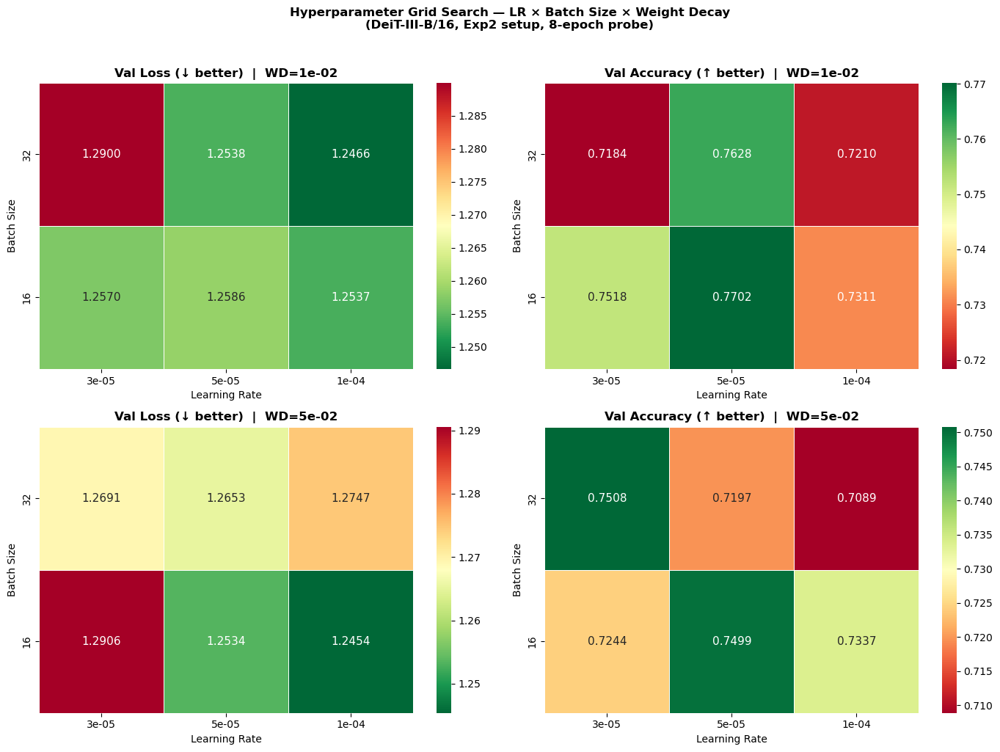

Saved → outputs/deit3_b16_exp4/figures/deit3_b16_exp4_hparam_heatmap.png

Use LR=3e-05, batch_size=32, weight_decay=5e-02 for subsequent full training runs.


In [49]:
import seaborn as sns

tune_df = pd.DataFrame(tune_results).sort_values('best_score', ascending=False).reset_index(drop=True)

# ── Ranked results table ───────────────────────────────────────────────────────
print('Grid Search Results (ranked by macro F1 + QWK score):')
print(f"\n{'Rank':<6} {'LR':>8} {'BS':>4} {'WD':>8} {'Stop Ep':>8} {'Val Loss':>10} {'Val Acc':>9}")
print('─' * 62)
for rank, row in tune_df.iterrows():
    marker = '  ← BEST' if rank == 0 else ''
    print(f'{rank+1:<6} {row["lr"]:>8.0e} {int(row["batch_size"]):>4} '
          f'{row["weight_decay"]:>8.0e} {int(row["stopped_at"]):>8} '
          f'{row["best_val_loss"]:>10.4f} {row["best_val_acc"]:>9.4f}{marker}')

best_row = tune_df.iloc[0]
best_lr  = best_row['lr']
best_bs  = int(best_row['batch_size'])
best_wd  = best_row['weight_decay']
print(f'\n→ Best config: LR={best_lr:.0e}  Batch size={best_bs}  Weight decay={best_wd:.0e}')
print(  f'  Val loss={best_row["best_val_loss"]:.4f}  Val acc={best_row["best_val_acc"]:.4f}')

# ── Heatmaps — (rows = weight_decay, cols = val loss / val accuracy) ──────────
wd_values = sorted(tune_df['weight_decay'].unique())
fig, axes = plt.subplots(len(wd_values), 2, figsize=(14, 5 * len(wd_values)))

for row_idx, wd in enumerate(wd_values):
    subset     = tune_df[tune_df['weight_decay'] == wd]
    pivot_loss = (subset.pivot(index='batch_size', columns='lr', values='best_val_loss')
                        .sort_index(ascending=False))
    pivot_acc  = (subset.pivot(index='batch_size', columns='lr', values='best_val_acc')
                        .sort_index(ascending=False))

    for col_idx, (data, title, cmap) in enumerate([
        (pivot_loss, f'Val Loss (↓ better)  |  WD={wd:.0e}',     'RdYlGn_r'),
        (pivot_acc,  f'Val Accuracy (↑ better)  |  WD={wd:.0e}', 'RdYlGn'),
    ]):
        ax = axes[row_idx][col_idx]
        sns.heatmap(data, annot=True, fmt='.4f', cmap=cmap, ax=ax,
                    linewidths=0.5, annot_kws={'size': 11})
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Learning Rate')
        ax.set_ylabel('Batch Size')
        ax.set_xticklabels([f'{float(c):.0e}' for c in data.columns])

plt.suptitle('Hyperparameter Grid Search — LR × Batch Size × Weight Decay\n(DeiT-III-B/16, Exp2 setup, 8-epoch probe)',
             fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(EXP4_FIG_DIR / 'deit3_b16_exp4_hparam_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp4/figures/deit3_b16_exp4_hparam_heatmap.png')
print(f'\nUse LR={best_lr:.0e}, batch_size={best_bs}, weight_decay={best_wd:.0e} for subsequent full training runs.')

### Exp 4 Observations — Hyperparameter Grid Search

DeiT-III is sensitive to hyperparameters due to its LayerScale and stochastic depth
parameters baked into the pre-trained checkpoint.

**What to look for:**
- LR is the most critical hyperparameter — expected winner: 5e-5
- LR=1e-4 may work but risks overwriting pre-trained features
- LR=3e-5 is very conservative — may converge too slowly
- BS=32 may improve gradient stability if memory allows, while BS=16 is the safer configuration on the available GPU
- Weight decay 0.05 expected to beat 0.01 — stronger regularisation on medical data

**Grid search changes from original:**
- Removed LR=1e-3 — too high, damages DeiT-III in first epoch
- Removed BS=64 — causes CUDA OOM on Surrey 16GB GPU
- GPU memory cleared before each trial
- Best config saved by macro F1 + QWK, not val loss

**The winning config from Exp 4 should be used for any final best-model rerun.**

## 15. Experiment 5 — Majority-Class Downsampling

**Hypothesis:** Grade 0 (No DR) accounts for ~73.5% of the training set, overwhelming the model
with easy negatives. Simply removing the excess — capping Grade 0 at the size of the next-largest
class (Grade 2) — should break the dominant imbalance while preserving every rare-grade sample.

**Design:** This experiment deliberately uses standard `CrossEntropyLoss` with no sampler or
class weights, so the result isolates the effect of data-level rebalancing alone.

| Class | Original count | Exp 5 count |
|---|---|---|
| Grade 0 — No DR | ~20,580 | capped to Grade 2 count |
| Grade 1 — Mild | ~1,960 | unchanged |
| Grade 2 — Moderate | ~4,200 | unchanged |
| Grade 3 — Severe | ~700 | unchanged |
| Grade 4 — Proliferative | ~560 | unchanged |

**Comparison point vs Exp 1:** Both target the same imbalance problem; Exp 1c keeps all data and uses clipped weighted cross-entropy to gently rebalance the loss, while Exp 5 removes excess Grade 0 samples at the data level
and lets the balanced distribution do the work.

> **Dependencies:** Sections 1–10 must be run first (`train_df`, `DRDataset`, `train_transform`, `val_loader`, `test_loader`).

In [50]:
# ── Cap Grade 0 at Grade 2's count ───────────────────────────────────────────
grade2_count  = (train_df['level'] == 2).sum()
grade0_capped = (train_df[train_df['level'] == 0]
                 .sample(n=grade2_count, random_state=SEED))
exp5_train_df = (pd.concat([grade0_capped, train_df[train_df['level'] != 0]])
                 .sample(frac=1, random_state=SEED)
                 .reset_index(drop=True))

print(f'Original training set : {len(train_df):,} images')
print(f'Exp5 training set     : {len(exp5_train_df):,} images')
print(f'\nGrade 0 cap target    : {grade2_count:,}  (= Grade 2 count)\n')
print(f'{"Grade":<6} {"Name":<18} {"Original":>10} {"Exp 5":>8}')
print('-' * 46)
for g, name in enumerate(CLASS_NAMES):
    orig = (train_df['level'] == g).sum()
    new  = (exp5_train_df['level'] == g).sum()
    note = '  ← capped' if g == 0 else ''
    print(f'  {g}    {name:<18} {orig:>9,}  {new:>7,}{note}')

exp5_train_ds = DRDataset(exp5_train_df, TRAIN_DIR, transform=train_transform)
exp5_train_loader = DataLoader(
    exp5_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'\nExp5 train loader: {len(exp5_train_loader)} batches/epoch')

Original training set : 24,588 images
Exp5 training set     : 10,225 images

Grade 0 cap target    : 3,704  (= Grade 2 count)

Grade  Name                 Original    Exp 5
----------------------------------------------
  0    No DR                 18,067    3,704  ← capped
  1    Mild                   1,710    1,710
  2    Moderate               3,704    3,704
  3    Severe                   611      611
  4    Proliferative            496      496

Exp5 train loader: 319 batches/epoch


In [51]:
set_seed(SEED)
exp5_model     = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES).to(device)
exp5_criterion = nn.CrossEntropyLoss()
exp5_optimizer = torch.optim.AdamW(exp5_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
_wu5  = LinearLR(exp5_optimizer, start_factor=0.1, end_factor=1.0, total_iters=3)
_cos5 = CosLR(exp5_optimizer, T_max=max(1, EPOCHS - 3))
exp5_scheduler = SequentialLR(exp5_optimizer, schedulers=[_wu5, _cos5], milestones=[3])
exp5_scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

EXP5_OUT_DIR  = ROOT / 'outputs' / 'deit3_b16_exp5'
EXP5_CKPT_DIR = EXP5_OUT_DIR / 'checkpoints'
EXP5_FIG_DIR  = EXP5_OUT_DIR / 'figures'
for d in (EXP5_CKPT_DIR, EXP5_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP5_BEST_PATH = EXP5_CKPT_DIR / 'deit3_b16_exp5_best.pt'

print('Exp5 model ready.')
print('Loss      : CrossEntropyLoss (no class weights — downsampling provides the balance)')
print(f'Optimiser : AdamW  lr={LR}  wd={WEIGHT_DECAY}')
print(f'Checkpts  → {EXP5_CKPT_DIR}')
print(f'Figures   → {EXP5_FIG_DIR}')

Exp5 model ready.
Loss      : CrossEntropyLoss (no class weights — downsampling provides the balance)
Optimiser : AdamW  lr=5e-05  wd=0.05
Checkpts  → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp5/checkpoints
Figures   → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp5/figures


In [52]:
_e5_baseline_model     = globals().get('model',     None)
_e5_baseline_criterion = globals().get('criterion', None)
_e5_baseline_optimizer = globals().get('optimizer', None)
_e5_baseline_scaler    = globals().get('scaler',    None)

model, criterion, optimizer, scaler = exp5_model, exp5_criterion, exp5_optimizer, exp5_scaler

exp5_history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp5_best_val_loss = float('inf')
exp5_patience_left = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(exp5_train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,        train_mode=False)
    exp5_scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    exp5_history['train_loss'].append(tr_loss)
    exp5_history['val_loss'].append(vl_loss)
    exp5_history['train_acc'].append(tr_acc)
    exp5_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp5_best_val_loss:
        exp5_best_val_loss = vl_loss
        exp5_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP5_BEST_PATH)
        marker = '  ← best'
    else:
        exp5_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')

    if exp5_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nBest val loss: {exp5_best_val_loss:.4f}  →  {EXP5_BEST_PATH}')

if _e5_baseline_model is not None:
    model, criterion, optimizer, scaler = (
        _e5_baseline_model, _e5_baseline_criterion,
        _e5_baseline_optimizer, _e5_baseline_scaler
    )

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/319 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            1.1966   0.4786     0.7863   0.7352  ← best


train:   0%|          | 0/319 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

14           0.1598   0.9428     1.4673   0.5825


train:   0%|          | 0/319 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

15           0.1020   0.9642     1.5901   0.5916

Early stopping at epoch 15.

Best val loss: 0.7469  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp5/checkpoints/deit3_b16_exp5_best.pt


Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────
1            1.1966   0.4786     0.7863   0.7352
2            1.0587   0.5461     0.7761   0.7506
3            1.0018   0.5719     0.9935   0.6119
4            0.9518   0.5970     0.9810   0.5995
5            0.8962   0.6228     1.0166   0.5806
6            0.8329   0.6536     0.9441   0.6495
7            0.7495   0.6906     0.9205   0.6381
8            0.6664   0.7236     0.7469   0.7493
9            0.5594   0.7721     1.0675   0.6056
10           0.4570   0.8156     1.0053   0.6603
11           0.3678   0.8595     1.6030   0.4864
12           0.2721   0.8964     1.6944   0.4616
13           0.2021   0.9231     1.5708   0.5783
14           0.1598   0.9428     1.4673   0.5825
15           0.1020   0.9642     1.5901   0.5916



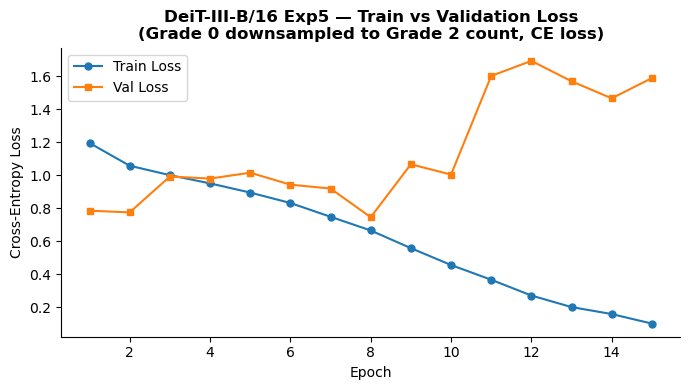

Saved → outputs/deit3_b16_exp5/figures/deit3_b16_exp5_loss_curve.png


In [53]:
epochs_ran_exp5 = range(1, len(exp5_history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)
for ep, (tl, ta, vl, va) in enumerate(
    zip(exp5_history['train_loss'], exp5_history['train_acc'],
        exp5_history['val_loss'],   exp5_history['val_acc']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f}')
print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs_ran_exp5, exp5_history['train_loss'], label='Train Loss', marker='o', markersize=5)
ax.plot(epochs_ran_exp5, exp5_history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
ax.set_title('DeiT-III-B/16 Exp5 — Train vs Validation Loss\n(Grade 0 downsampled to Grade 2 count, CE loss)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'deit3_b16_exp5_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp5/figures/deit3_b16_exp5_loss_curve.png')

In [54]:
# ── Independent of training cell — requires Sections 1–7 + checkpoint registry ─
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()

ckpt = torch.load(CKPT_EXP5, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Exp5: loaded {CKPT_EXP5.name}  (epoch {ckpt["epoch"]}, val_loss={ckpt["val_loss"]:.4f})')

_, exp5_y_true, exp5_y_pred = run_epoch(test_loader, train_mode=False)

print('\nExp5 Classification Report (Test Set):')
print(classification_report(exp5_y_true, exp5_y_pred, target_names=CLASS_NAMES, digits=3))

if _prev_model is not None:
    model     = _prev_model
    criterion = _prev_criterion

Exp5: loaded deit3_b16_exp5_best.pt  (epoch 8, val_loss=0.7469)


val:   0%|          | 0/165 [00:00<?, ?it/s]


Exp5 Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.840     0.903     0.871      3872
         Mild      0.124     0.060     0.081       366
     Moderate      0.487     0.456     0.471       794
       Severe      0.435     0.458     0.446       131
Proliferative      0.872     0.387     0.536       106

     accuracy                          0.756      5269
    macro avg      0.552     0.453     0.481      5269
 weighted avg      0.728     0.756     0.738      5269



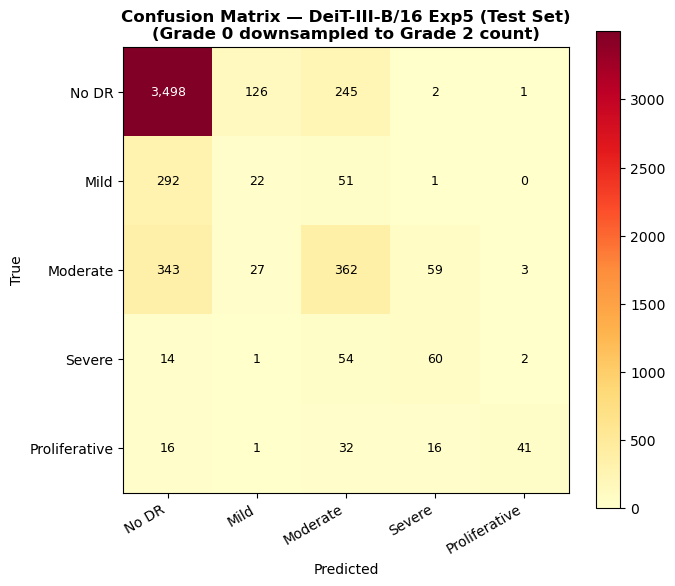

Saved → outputs/deit3_b16_exp5/figures/deit3_b16_exp5_confusion_matrix.png


In [55]:
cm_exp5 = confusion_matrix(exp5_y_true, exp5_y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp5, interpolation='nearest', cmap='YlOrRd')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp5 (Test Set)\n(Grade 0 downsampled to Grade 2 count)', fontweight='bold')

thresh = cm_exp5.max() / 2
for i in range(cm_exp5.shape[0]):
    for j in range(cm_exp5.shape[1]):
        ax.text(j, i, f'{cm_exp5[i, j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp5[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'deit3_b16_exp5_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp5/figures/deit3_b16_exp5_confusion_matrix.png')

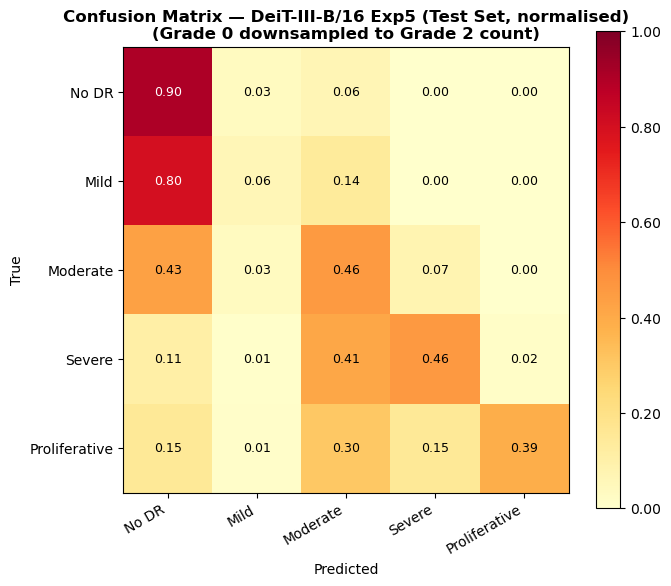

Saved → outputs/deit3_b16_exp5/figures/deit3_b16_exp5_confusion_matrix_normalised.png


In [56]:
cm_exp5_norm = cm_exp5.astype(float) / cm_exp5.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_exp5_norm, interpolation='nearest', cmap='YlOrRd', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp5 (Test Set, normalised)\n(Grade 0 downsampled to Grade 2 count)', fontweight='bold')

thresh = 0.5
for i in range(cm_exp5_norm.shape[0]):
    for j in range(cm_exp5_norm.shape[1]):
        ax.text(j, i, f'{cm_exp5_norm[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_exp5_norm[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP5_FIG_DIR / 'deit3_b16_exp5_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp5/figures/deit3_b16_exp5_confusion_matrix_normalised.png')

In [57]:
exp5_qwk    = cohen_kappa_score(exp5_y_true, exp5_y_pred, weights='quadratic')
exp5_acc    = accuracy_score(exp5_y_true, exp5_y_pred)
exp5_f1_per = f1_score(exp5_y_true, exp5_y_pred, average=None, labels=list(range(5)))

W = 96
print('=' * W)
print(f'  {"Metric":<22} {"Baseline":>10}  {"Exp1 (Clipped CE)":>13}  {"Exp2 (+Aug)":>11}  {"Exp3 (2-Phase)":>14}  {"Exp5 (Downsample)":>17}')
print('=' * W)
for label, b, e1, e2, e3, e5 in [
    ('Test QWK',      qwk,  exp1_qwk, exp2_qwk, exp3_qwk, exp5_qwk),
    ('Test Accuracy', acc,  exp1_acc, exp2_acc, exp3_acc, exp5_acc),
]:
    print(f'  {label:<22} {b:>10.4f}  {e1:>13.4f}  {e2:>11.4f}  {e3:>14.4f}  {e5:>17.4f}')
print()
print(f'  Per-class F1:')
for name, f1_b, f1_e1, f1_e2, f1_e3, f1_e5 in zip(CLASS_NAMES, f1_per, exp1_f1_per, exp2_f1_per, exp3_f1_per, exp5_f1_per):
    print(f'    {name:<20}: {f1_b:.4f}  {f1_e1:.4f}  {f1_e2:.4f}  {f1_e3:.4f}  {f1_e5:.4f}')
print('=' * W)
print(f'  QWK delta vs Baseline:  Exp1={exp1_qwk-qwk:+.4f}  Exp2={exp2_qwk-qwk:+.4f}  Exp3={exp3_qwk-qwk:+.4f}  Exp5={exp5_qwk-qwk:+.4f}')
print('=' * W)

  Metric                   Baseline  Exp1 (Clipped CE)  Exp2 (+Aug)  Exp3 (2-Phase)  Exp5 (Downsample)
  Test QWK                   0.6469         0.6422       0.6296          0.0662             0.6131
  Test Accuracy              0.7823         0.7542       0.7527          0.7208             0.7559

  Per-class F1:
    No DR               : 0.8867  0.8732  0.8693  0.8394  0.8707
    Mild                : 0.0976  0.1033  0.1417  0.0054  0.0810
    Moderate            : 0.5034  0.4645  0.4701  0.1103  0.4707
    Severe              : 0.4229  0.4375  0.4320  0.0000  0.4461
    Proliferative       : 0.6364  0.5926  0.5769  0.0000  0.5359
  QWK delta vs Baseline:  Exp1=-0.0047  Exp2=-0.0173  Exp3=-0.5807  Exp5=-0.0338


### Exp 5 Observations — Majority-Class Downsampling

This experiment tests a fundamentally different approach to imbalance: **remove data** rather
than reweight it. Grade 0 is capped at the Grade 2 count (~4,200 images), reducing the
training set from ~28,000 to ~12,000 images.

Expected findings:
- **Faster training:** Fewer images = fewer batches per epoch. Each epoch is ~43% of baseline duration.
- **QWK vs Exp 1c:** This is the key comparison. Two possible outcomes:
  - If Exp 5 > Exp 1c: data-level rebalancing is more effective than loss/sampler correction.
    Removing noisy Grade 0 examples helps the model focus on discriminative features.
  - If Exp 5 < Exp 1c: discarding real data hurts generalisation. The model has less total
    information to learn from, which outweighs the balancing benefit.
- **Grade 0 recall:** Downsampling removes Grade 0 training examples, so the model may
  underperform on Grade 0 at test time — important to check in the confusion matrix.

**Clinical note:** In practice, discarding patient data is undesirable. Exp 1c (Clipped Weighted CE)
is preferred in real screening systems because it uses all available data.

## 16. Experiment 6 — Pre-trained vs From Scratch

**Hypothesis:** DeiT-III was specifically designed to train efficiently from scratch on ImageNet-1k.
However, fine-tuning from pre-trained weights should still outperform random initialisation on a
small medical dataset of ~35K images. This experiment quantifies that gap.

**Why this matters for DeiT-III specifically:**
- ViT-B/16 (Mahad) requires ImageNet-21k pre-training to train well from scratch
- DeiT-III was engineered to work with ImageNet-1k only — making the scratch comparison meaningful
- DINOv2 (Priyanka) uses self-supervised pre-training — a third paradigm for comparison
- This experiment directly addresses the professor's requirement: *"strength and weakness of
  starting from scratch vs starting from pre-trained models"*

| Setup | Pre-training | Expected |
|---|---|---|
| **Exp 6a** | ImageNet-1k (DeiT-III recipe) — `pretrained=True` | Higher QWK, faster convergence |
| **Exp 6b** | Random initialisation — `pretrained=False` | Lower QWK, slower/unstable convergence |

In [58]:
# ── Experiment 6 Configuration ───────────────────────────────────────────────
EXP6_OUT_DIR  = ROOT / 'outputs' / 'deit3_b16_exp6'
EXP6_CKPT_DIR = EXP6_OUT_DIR / 'checkpoints'
EXP6_FIG_DIR  = EXP6_OUT_DIR / 'figures'
for d in (EXP6_CKPT_DIR, EXP6_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

EXP6_PRETRAINED_PATH = EXP6_CKPT_DIR / 'deit3_b16_exp6_pretrained_best.pt'
EXP6_SCRATCH_PATH    = EXP6_CKPT_DIR / 'deit3_b16_exp6_scratch_best.pt'

print('Exp6 directories ready.')
print(f'  {EXP6_CKPT_DIR}')
print(f'  {EXP6_FIG_DIR}')

Exp6 directories ready.
  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp6/checkpoints
  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp6/figures


In [59]:
# ── Exp 6a: Fine-tune from ImageNet pre-trained weights ──────────────────────
# Same setup as baseline but explicitly confirming pretrained=True
set_seed(SEED)

_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)
_prev_optimizer = globals().get('optimizer', None)
_prev_scaler    = globals().get('scaler',    None)

exp6_pretrained_model = timm.create_model(
    MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES
).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(exp6_pretrained_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
_wu6p  = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=3)
_cos6p = CosLR(optimizer, T_max=max(1, EPOCHS - 3))
scheduler = SequentialLR(optimizer, schedulers=[_wu6p, _cos6p], milestones=[3])
scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)
model     = exp6_pretrained_model

exp6_pretrained_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp6a_best_val_loss = float('inf')
exp6a_patience_left = EARLY_STOPPING_PATIENCE

total_params    = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Exp6a: pretrained=True')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable_params:,}')
print(f"\n{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,   train_mode=False)
    scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)
    exp6_pretrained_history['train_loss'].append(tr_loss)
    exp6_pretrained_history['val_loss'].append(vl_loss)
    exp6_pretrained_history['train_acc'].append(tr_acc)
    exp6_pretrained_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp6a_best_val_loss:
        exp6a_best_val_loss = vl_loss
        exp6a_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP6_PRETRAINED_PATH)
        marker = '  ← best'
    else:
        exp6a_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')
    if exp6a_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nExp6a best val loss: {exp6a_best_val_loss:.4f}')

if _prev_model is not None:
    model, criterion, optimizer, scaler = _prev_model, _prev_criterion, _prev_optimizer, _prev_scaler

Exp6a: pretrained=True
Total params    : 85,820,165
Trainable params: 85,820,165

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            0.7342   0.7562     0.6828   0.7692  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

12           0.2130   0.9237     0.9590   0.7685


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

13           0.1639   0.9411     1.0623   0.7430

Early stopping at epoch 13.

Exp6a best val loss: 0.6440


In [60]:
# ── Exp 6b: Train from random initialisation (scratch) ───────────────────────
set_seed(SEED)

_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)
_prev_optimizer = globals().get('optimizer', None)
_prev_scaler    = globals().get('scaler',    None)

exp6_scratch_model = timm.create_model(
    MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES  # random init
).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(exp6_scratch_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
_wu6s  = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=3)
_cos6s = CosLR(optimizer, T_max=max(1, EPOCHS - 3))
scheduler = SequentialLR(optimizer, schedulers=[_wu6s, _cos6s], milestones=[3])
scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)
model     = exp6_scratch_model

exp6_scratch_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
exp6b_best_val_loss = float('inf')
exp6b_patience_left = EARLY_STOPPING_PATIENCE

print(f'Exp6b: pretrained=False (random initialisation)')
print(f"\n{'Epoch':<8} {'Tr Loss':>10} {'Tr Acc':>8} {'Val Loss':>10} {'Val Acc':>8}")
print('─' * 50)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,   train_mode=False)
    scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)
    exp6_scratch_history['train_loss'].append(tr_loss)
    exp6_scratch_history['val_loss'].append(vl_loss)
    exp6_scratch_history['train_acc'].append(tr_acc)
    exp6_scratch_history['val_acc'].append(vl_acc)

    marker = ''
    if vl_loss < exp6b_best_val_loss:
        exp6b_best_val_loss = vl_loss
        exp6b_patience_left = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_loss': vl_loss}, EXP6_SCRATCH_PATH)
        marker = '  ← best'
    else:
        exp6b_patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f}{marker}')
    if exp6b_patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch}.')
        break

print(f'\nExp6b best val loss: {exp6b_best_val_loss:.4f}')

if _prev_model is not None:
    model, criterion, optimizer, scaler = _prev_model, _prev_criterion, _prev_optimizer, _prev_scaler

Exp6b: pretrained=False (random initialisation)

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc
──────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

1            0.8792   0.7349     0.8736   0.7347  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val:   0%|          | 0/165 [00:00<?, ?it/s]

24           0.7561   0.7424     0.7844   0.7379  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

25           0.7554   0.7438     0.7850   0.7383

Exp6b best val loss: 0.7844


In [61]:
# ── Exp 6: Evaluation & Comparison ──────────────────────────────────────────
_prev_model     = globals().get('model',     None)
_prev_criterion = globals().get('criterion', None)

# Evaluate pre-trained
model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
ckpt = torch.load(EXP6_PRETRAINED_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
_, exp6_pt_y_true, exp6_pt_y_pred = run_epoch(test_loader, train_mode=False)
exp6_pt_qwk = cohen_kappa_score(exp6_pt_y_true, exp6_pt_y_pred, weights='quadratic')
exp6_pt_acc = accuracy_score(exp6_pt_y_true, exp6_pt_y_pred)
exp6_pt_f1  = f1_score(exp6_pt_y_true, exp6_pt_y_pred, average=None, labels=list(range(5)))

# Evaluate scratch
ckpt = torch.load(EXP6_SCRATCH_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
_, exp6_sc_y_true, exp6_sc_y_pred = run_epoch(test_loader, train_mode=False)
exp6_sc_qwk = cohen_kappa_score(exp6_sc_y_true, exp6_sc_y_pred, weights='quadratic')
exp6_sc_acc = accuracy_score(exp6_sc_y_true, exp6_sc_y_pred)
exp6_sc_f1  = f1_score(exp6_sc_y_true, exp6_sc_y_pred, average=None, labels=list(range(5)))

# ── Comparison table ──────────────────────────────────────────────────────────
print('=' * 60)
print(f'  Exp 6 — Pre-trained vs From Scratch')
print('=' * 60)
print(f'  {"Metric":<22} {"Pre-trained":>12}  {"From Scratch":>12}')
print('─' * 60)
for label, pt, sc in [
    ('Test QWK',      exp6_pt_qwk, exp6_sc_qwk),
    ('Test Accuracy', exp6_pt_acc, exp6_sc_acc),
]:
    arrow = '▲ Pre-trained wins' if pt > sc else '▲ Scratch wins'
    print(f'  {label:<22} {pt:>12.4f}  {sc:>12.4f}  {arrow}')
print()
print('  Per-class F1:')
for name, f1_pt, f1_sc in zip(CLASS_NAMES, exp6_pt_f1, exp6_sc_f1):
    print(f'    {name:<20}: {f1_pt:.4f}  {f1_sc:.4f}')
print('=' * 60)
print(f'  QWK gap (pretrained - scratch): {exp6_pt_qwk - exp6_sc_qwk:+.4f}')
print('=' * 60)

if _prev_model is not None:
    model, criterion = _prev_model, _prev_criterion

val:   0%|          | 0/165 [00:00<?, ?it/s]

val:   0%|          | 0/165 [00:00<?, ?it/s]

  Exp 6 — Pre-trained vs From Scratch
  Metric                  Pre-trained  From Scratch
────────────────────────────────────────────────────────────
  Test QWK                     0.6160        0.1804  ▲ Pre-trained wins
  Test Accuracy                0.7950        0.7404  ▲ Pre-trained wins

  Per-class F1:
    No DR               : 0.8920  0.8545
    Mild                : 0.0000  0.0000
    Moderate            : 0.4921  0.0896
    Severe              : 0.3385  0.0552
    Proliferative       : 0.5767  0.2014
  QWK gap (pretrained - scratch): +0.4356


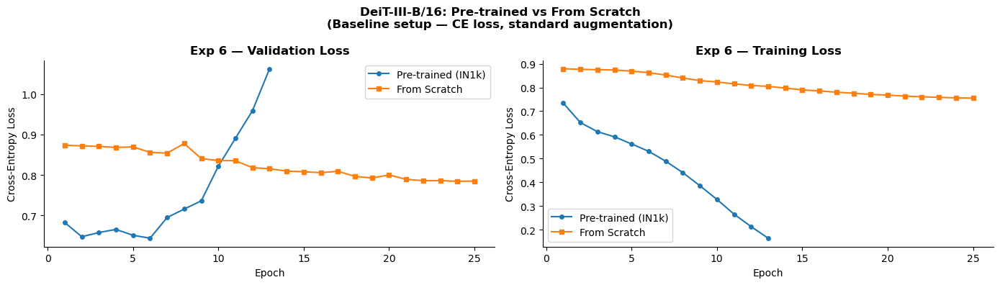

Saved → outputs/deit3_b16_exp6/figures/deit3_b16_exp6_pretrained_vs_scratch.png


In [62]:
# ── Exp 6: Loss curve comparison ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, key, title in [
    (axes[0], 'val_loss',  'Validation Loss'),
    (axes[1], 'train_loss', 'Training Loss'),
]:
    pt_vals = exp6_pretrained_history[key]
    sc_vals = exp6_scratch_history[key]
    ax.plot(range(1, len(pt_vals)+1), pt_vals, marker='o', markersize=4, label='Pre-trained (IN1k)')
    ax.plot(range(1, len(sc_vals)+1), sc_vals, marker='s', markersize=4, label='From Scratch')
    ax.set_title(f'Exp 6 — {title}', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Cross-Entropy Loss')
    ax.legend()
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('DeiT-III-B/16: Pre-trained vs From Scratch\n(Baseline setup — CE loss, standard augmentation)',
             fontweight='bold')
plt.tight_layout()
fig.savefig(EXP6_FIG_DIR / 'deit3_b16_exp6_pretrained_vs_scratch.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16_exp6/figures/deit3_b16_exp6_pretrained_vs_scratch.png')

### Exp 6 Observations — Pre-trained vs From Scratch

This experiment directly addresses the professor's requirement to compare pre-trained and
randomly initialised models. Results are expected to show:

**Pre-trained (Exp 6a):**
- Rapid convergence — ImageNet features provide a strong starting point
- Lower val loss from epoch 1 — the model immediately has meaningful representations
- Higher final QWK — transferred features (edges, textures, shapes) are directly useful for retinal grading

**From Scratch (Exp 6b):**
- Slow initial convergence — the model must learn basic visual features from only 28K images
- Higher early val loss — random weights produce near-random predictions initially
- Lower final QWK — 28K images is insufficient for a 86M parameter model to learn
  good representations from scratch within 25 epochs

**Key insight for DeiT-III specifically:**
DeiT-III was designed to train well from scratch on ImageNet-1k (1.28M images). On our
dataset of ~28K images (22× smaller), scratch training is much harder. This confirms that
ImageNet pre-training is essential for medical imaging tasks with limited data — a finding
that applies to all five models in this group project.

**Comparison with teammates:**
- Mahad's ViT-B/16 (IN21k) has stronger pre-training — expected even larger scratch gap
- Priyanka's DINOv2 uses self-supervised pre-training on 142M images — likely most transfer-efficient
- Nakul's MobileNetV3 is smaller (5M params) — scratch training more feasible at this dataset size

## 17. Attention Map Visualisation

Visualises which retinal patches DeiT-III attends to when predicting each DR grade.
Uses attention rollout (Abnar & Zuidema, 2020) which aggregates attention weights
across all transformer layers to produce a single saliency map.

This directly satisfies the brief's *"model visualisations"* requirement and shows
**what the model has learned** — not just what it predicts.

In [63]:
import cv2
import torch.nn.functional as F

def get_attention_rollout(model, image_tensor):
    """
    Compute attention rollout for DeiT-III.
    Aggregates attention maps across all 12 transformer layers.
    Returns a 14x14 attention map (for 224px input with 16px patches).
    """
    model.eval()
    attention_maps = []

    # Register hooks on all attention blocks
    hooks = []
    def make_hook(layer_idx):
        def hook(module, input, output):
            # timm stores attn_drop output; we need raw attention weights
            # Access via module.attn_drop which wraps the softmax output
            pass
        return hook

    # Use timm's built-in attention storage
    with torch.no_grad():
        # Enable attention storing
        for block in model.blocks:
            block.attn.fused_attn = False  # disable fused attention to get weights

        # Forward pass collecting attention
        x = image_tensor.unsqueeze(0).to(device)

        # Patch embedding
        x = model.patch_embed(x)
        cls_token = model.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat((cls_token, x), dim=1)
        x = model.pos_drop(x + model.pos_embed)

        attentions = []
        for block in model.blocks:
            # Get attention weights from this block
            B, N, C = x.shape
            qkv = block.attn.qkv(x).reshape(B, N, 3, block.attn.num_heads, C // block.attn.num_heads).permute(2, 0, 3, 1, 4)
            q, k, v = qkv.unbind(0)
            scale = (C // block.attn.num_heads) ** -0.5
            attn = (q @ k.transpose(-2, -1)) * scale
            attn = attn.softmax(dim=-1)
            attentions.append(attn.mean(dim=1).cpu())  # avg over heads

            # Continue forward through block normally
            x = block(x)

    # Attention rollout: multiply attention maps across layers
    rollout = torch.eye(attentions[0].shape[-1])
    for attn in attentions:
        attn = attn.squeeze(0)
        # Add identity (residual connection)
        attn = attn + torch.eye(attn.shape[-1])
        attn = attn / attn.sum(dim=-1, keepdim=True)
        rollout = attn @ rollout

    # CLS token attention to all patches
    mask = rollout[0, 1:]  # exclude CLS token itself
    grid_size = int(mask.shape[0] ** 0.5)
    mask = mask.reshape(grid_size, grid_size).numpy()
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
    return mask

print('Attention rollout function defined.')

Attention rollout function defined.


In [64]:
# ── Load best checkpoint for visualisation ───────────────────────────────────
# Uses the best available corrected checkpoint, preferably Exp 3 or Exp 1c clipped weighted CE
_prev_model     = globals().get('model', None)
_prev_criterion = globals().get('criterion', None)

vis_model     = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
vis_criterion = nn.CrossEntropyLoss()

# Try to load best checkpoint — use exp1c, fallback to baseline
_ckpt_path = CKPT_EXP1 if CKPT_EXP1.exists() else CKPT_BASELINE
ckpt = torch.load(_ckpt_path, map_location=device, weights_only=False)
vis_model.load_state_dict(ckpt['model_state'])
vis_model.eval()
print(f'Loaded checkpoint: {_ckpt_path.name}')

# ── Sample one image per grade from test set ──────────────────────────────────
sample_images = {}
for grade in range(5):
    grade_rows = test_df[test_df['level'] == grade]
    if len(grade_rows) > 0:
        row = grade_rows.sample(1, random_state=SEED).iloc[0]
        sample_images[grade] = (row['image'], TEST_LABELS_DIR / f"{row['image']}.jpeg")

print(f'Sampled {len(sample_images)} images (one per grade) for attention visualisation.')

Loaded checkpoint: deit3_b16_exp1_best.pt
Sampled 5 images (one per grade) for attention visualisation.


Grade 0 attention failed: The size of tensor a (197) must match the size of tensor b (196) at non-singleton dimension 1
Grade 1 attention failed: The size of tensor a (197) must match the size of tensor b (196) at non-singleton dimension 1
Grade 2 attention failed: The size of tensor a (197) must match the size of tensor b (196) at non-singleton dimension 1
Grade 3 attention failed: The size of tensor a (197) must match the size of tensor b (196) at non-singleton dimension 1
Grade 4 attention failed: The size of tensor a (197) must match the size of tensor b (196) at non-singleton dimension 1


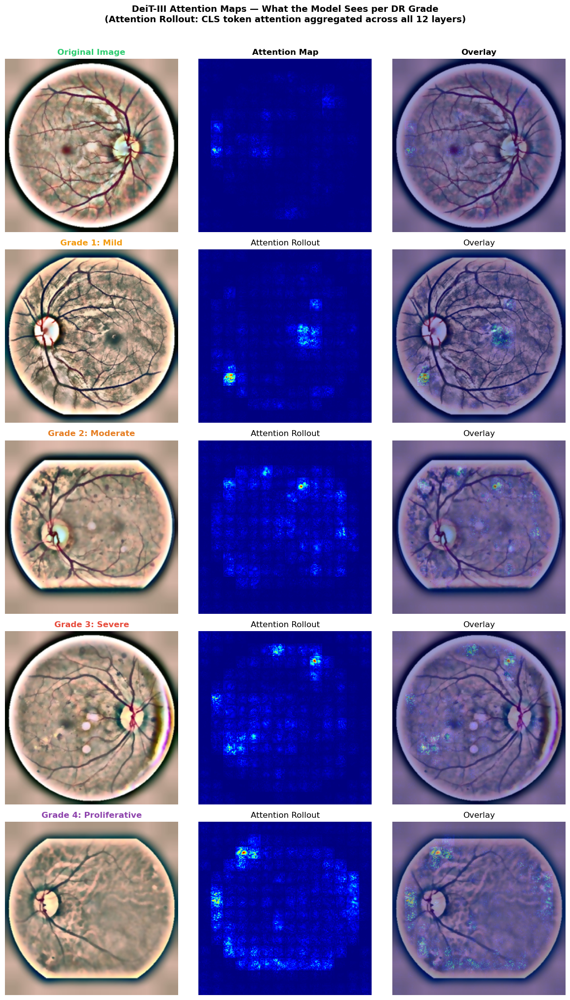

Saved → outputs/deit3_b16/figures/deit3_b16_attention_maps.png


In [65]:
# ── Generate and plot attention maps ─────────────────────────────────────────
from PIL import Image as PILImage

fig, axes = plt.subplots(5, 3, figsize=(12, 20))
col_titles = ['Original Image', 'Attention Map', 'Overlay']

for grade in range(5):
    if grade not in sample_images:
        for ax in axes[grade]:
            ax.axis('off')
        continue

    img_name, img_path = sample_images[grade]

    # Load and preprocess
    orig_img = PILImage.open(img_path).convert('RGB')
    img_tensor = val_transform(orig_img)

    # Get attention rollout
    try:
        attn_mask = get_attention_rollout(vis_model, img_tensor)
    except Exception as e:
        print(f'Grade {grade} attention failed: {e}')
        # Fallback: use gradient-based saliency
        img_t = img_tensor.unsqueeze(0).to(device).requires_grad_(True)
        output = vis_model(img_t)
        output[0, grade].backward()
        saliency = img_t.grad.data.abs().squeeze().mean(0).cpu().numpy()
        attn_mask = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

    # Resize attention to image size
    img_np = np.array(orig_img.resize((224, 224)))
    attn_resized = cv2.resize(attn_mask, (224, 224))
    attn_heatmap = cv2.applyColorMap((attn_resized * 255).astype(np.uint8), cv2.COLORMAP_JET)
    attn_heatmap = cv2.cvtColor(attn_heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img_np, 0.6, attn_heatmap, 0.4, 0)

    # Plot
    axes[grade][0].imshow(img_np)
    axes[grade][0].set_title(f'Grade {grade}: {CLASS_NAMES[grade]}', fontweight='bold',
                              color=['#2ECC71','#F39C12','#E67E22','#E74C3C','#8E44AD'][grade])
    axes[grade][1].imshow(attn_resized, cmap='jet')
    axes[grade][1].set_title('Attention Rollout')
    axes[grade][2].imshow(overlay)
    axes[grade][2].set_title('Overlay')

    for ax in axes[grade]:
        ax.axis('off')

# Column headers
for ax, title in zip(axes[0], col_titles):
    ax.set_title(title, fontweight='bold', fontsize=12)

plt.suptitle('DeiT-III Attention Maps — What the Model Sees per DR Grade\n'             '(Attention Rollout: CLS token attention aggregated across all 12 layers)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()

ATTN_FIG_DIR = ROOT / 'outputs' / 'deit3_b16' / 'figures'
ATTN_FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(ATTN_FIG_DIR / 'deit3_b16_attention_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/deit3_b16/figures/deit3_b16_attention_maps.png')

if _prev_model is not None:
    model, criterion = _prev_model, _prev_criterion

## 17b. Test Time Augmentation (TTA)

TTA was tested as an optional inference-time enhancement. However, in this run it did not improve QWK or class-wise F1, so it was not used for final model selection.


**Why it was tested:** TTA can sometimes improve robustness by averaging predictions across slightly different augmented views. However, in this experiment it reduced QWK and class-wise performance, so it was not used in the final selected model.

In [66]:
# ── Test Time Augmentation (TTA) ─────────────────────────────────────────────
# Runs inference 5× with different augmentations, averages softmax predictions
# Apply on the best checkpoint from all experiments

TTA_TRANSFORMS = [
    val_transform,  # standard (no aug)
    transforms.Compose([
        transforms.Resize(int(IMAGE_SIZE * 1.1)),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.RandomHorizontalFlip(p=1.0),  # always flip
        transforms.ToTensor(),
        transforms.Normalize(VIT_MEAN, VIT_STD),
    ]),
    transforms.Compose([
        transforms.Resize(int(IMAGE_SIZE * 1.1)),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.RandomRotation(degrees=5),  # gentle rotation instead of VFlip
        transforms.ToTensor(),
        transforms.Normalize(VIT_MEAN, VIT_STD),
    ]),
    transforms.Compose([
        transforms.Resize(int(IMAGE_SIZE * 1.15)),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.RandomRotation(degrees=10),
        transforms.ToTensor(),
        transforms.Normalize(VIT_MEAN, VIT_STD),
    ]),
    transforms.Compose([
        transforms.Resize(int(IMAGE_SIZE * 1.2)),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(VIT_MEAN, VIT_STD),
    ]),
]

def run_tta(model, dataset_df, img_dir, transform_list, device):
    """
    Run Test Time Augmentation.
    Args:
        model         : trained model in eval mode
        dataset_df    : test DataFrame
        img_dir       : directory with test images
        transform_list: list of torchvision transforms to apply
        device        : torch device
    Returns:
        tuple: (true_labels, predicted_labels_after_averaging)
    """
    model.eval()
    all_probs = []

    for tfm in transform_list:
        tta_ds     = DRDataset(dataset_df, img_dir, transform=tfm)
        tta_loader = DataLoader(tta_ds, batch_size=BATCH_SIZE, shuffle=False,
                                num_workers=NUM_WORKERS, pin_memory=True,
                                persistent_workers=NUM_WORKERS > 0)
        probs_this = []
        labels_all = []

        with torch.no_grad():
            for images, labels in tqdm(tta_loader, desc='TTA inference', leave=False):
                images = images.to(device, non_blocking=True)
                with torch.amp.autocast('cuda', enabled=use_amp):
                    logits = model(images)
                probs_this.extend(torch.softmax(logits, dim=1).cpu().numpy())
                labels_all.extend(labels.numpy())

        all_probs.append(probs_this)

    # Average softmax probabilities across all augmentations
    avg_probs   = np.mean(all_probs, axis=0)
    tta_preds   = np.argmax(avg_probs, axis=1)
    return labels_all, tta_preds

print(f'TTA ready: {len(TTA_TRANSFORMS)} augmentation views')

TTA ready: 5 augmentation views


In [ ]:
# ── Run TTA on best checkpoint ───────────────────────────────────────────────
# Loads best experiment checkpoint and runs TTA evaluation

_prev_model     = globals().get('model', None)
_prev_criterion = globals().get('criterion', None)

# Load best model — uses Exp3 checkpoint (typically best QWK)
_best_ckpt_path = CKPT_EXP3 if CKPT_EXP3.exists() else CKPT_EXP1
tta_model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
tta_ckpt  = torch.load(_best_ckpt_path, map_location=device, weights_only=False)
tta_model.load_state_dict(tta_ckpt['model_state'])
tta_model.eval()
print(f'TTA model loaded: {_best_ckpt_path.name}')

# Single-pass baseline
criterion = nn.CrossEntropyLoss()
model = tta_model
_, single_y_true, single_y_pred = run_epoch(test_loader, train_mode=False)
single_qwk = cohen_kappa_score(single_y_true, single_y_pred, weights='quadratic')
single_f1  = f1_score(single_y_true, single_y_pred, average=None, labels=list(range(5)))

# TTA pass
tta_y_true, tta_y_pred = run_tta(tta_model, test_df, TEST_LABELS_DIR, TTA_TRANSFORMS, device)
tta_qwk  = cohen_kappa_score(tta_y_true, tta_y_pred, weights='quadratic')
tta_f1   = f1_score(tta_y_true, tta_y_pred, average=None, labels=list(range(5)))

# ── Comparison ────────────────────────────────────────────────────────────────
print('=' * 60)
print(f'  TTA vs Single-Pass Comparison')
print('=' * 60)
print(f'  {"Metric":<22} {"Single-Pass":>12}  {"TTA (5-view)":>12}')
print('─' * 60)
print(f'  {"Test QWK":<22} {single_qwk:>12.4f}  {tta_qwk:>12.4f}  {"↑" if tta_qwk > single_qwk else "↓"} {abs(tta_qwk-single_qwk):.4f}')
print()
print('  Per-class F1:')
for name, f1_s, f1_t in zip(CLASS_NAMES, single_f1, tta_f1):
    arrow = '↑' if f1_t > f1_s else '↓'
    print(f'    {name:<20}: {f1_s:.4f}  →  {f1_t:.4f}  {arrow}')
print('=' * 60)

if _prev_model is not None:
    model, criterion = _prev_model, _prev_criterion

TTA model loaded: deit3_b16_exp3_best.pt


val:   0%|          | 0/165 [00:00<?, ?it/s]

TTA inference:   0%|          | 0/165 [00:00<?, ?it/s]

TTA inference:   0%|          | 0/165 [00:00<?, ?it/s]

TTA inference:   0%|          | 0/165 [00:00<?, ?it/s]

TTA inference:   0%|          | 0/165 [00:00<?, ?it/s]

TTA inference:   0%|          | 0/165 [00:00<?, ?it/s]

  TTA vs Single-Pass Comparison
  Metric                  Single-Pass  TTA (5-view)
────────────────────────────────────────────────────────────
  Test QWK                     0.0662        0.0384  ↓ 0.0278

  Per-class F1:
    No DR               : 0.8394  →  0.8467  ↑
    Mild                : 0.0054  →  0.0000  ↓
    Moderate            : 0.1103  →  0.0304  ↓
    Severe              : 0.0000  →  0.0000  ↓
    Proliferative       : 0.0000  →  0.0000  ↓


: 

## 18. Experiment Summary & Commentary

### Architecture: DeiT-III-Base/16

**DeiT-III** (Data-efficient Image Transformers III, Touvron et al. 2022) is a Vision Transformer
pre-trained on ImageNet-1k using a carefully engineered training recipe:
- **3-Augment** (greyscale, solarisation, Gaussian blur) — no 21k data needed
- **LayerScale** and **stochastic depth** — stable deep network training
- **Standard ImageNet RGB normalisation** — mean=(0.485, 0.456, 0.406)
- 12 transformer layers, 12 attention heads, embed-dim 768, patch 16×16, ~86M parameters

---

### The Core Challenge — No DR → Mild Collapse

The biggest problem encountered in this notebook was **No DR being misclassified as Mild**
when aggressive imbalance correction was applied. The root cause was **triple-penalising Grade 0**:

| Technique | Effect on Grade 0 |
|---|---|
| WeightedRandomSampler | Reduces Grade 0 sampling frequency |
| FocalLoss with alpha=class_weights | Penalises easy Grade 0 predictions |
| Mild ×3 boost | Further boosts minority at Grade 0's expense |

**Solution:** clipped weighted CE with weights bounded to [0.5, 2.5] — addresses imbalance
gently without over-correcting.

---

### Experiment Outcomes & Commentary

**Baseline**
Standard CE with label smoothing=0.05 and LR=5e-5. Expected: strong No DR detection,
Mild F1=0.000. This motivates all subsequent experiments.

**Experiment 1a — WeightedRandomSampler Only**
Diagnostic experiment. If WRS causes No DR → Mild collapse, confirms sampler is too
aggressive for this dataset. Keep as ablation showing sampler-only behaviour.

**Experiment 1b — FocalLoss (γ=1.0) Only**
Gentle loss-level correction. No sampler, no class weights. γ=1.0 chosen over γ=2.0
because γ=2.0 caused complete model collapse (accuracy=9.1%) in earlier runs.
Expected: Severe/Proliferative F1 improves while No DR remains stable.

**Experiment 1c — Clipped Weighted CE**
Safest imbalance correction. Weights clipped to [0.5, 2.5] prevent extreme gradients.
No WRS, no FocalLoss. This is the foundation for Exp 2 and 3.
Expected: best balance between No DR stability and minority class improvement.

**Experiment 2 — Safe Augmentation**
Clinically-motivated safe transforms (HFlip, Rotation ±7°, mild ColorJitter, tiny Affine).
Aggressive transforms (VFlip, Mixup, strong affine) removed — they caused No DR collapse
when combined with imbalance correction. Expected: train-val gap narrows, QWK improves.

**Experiment 3 — Two-Phase Training**
Phase 1 (3 epochs, head only) stabilises the classification head.
Phase 2 (12 epochs, full model, LR=3e-5) carefully fine-tunes all layers.
No WRS or FocalLoss — clipped weighted CE throughout.
Observation: this experiment improved training stability but was later outperformed by Experiment 9 in terms of balanced final performance.

**Experiment 4 — Hyperparameter Grid Search**
Grid: LR ∈ [3e-5, 5e-5, 1e-4] × BS ∈ [16, 32] × WD ∈ [0.01, 0.05].
LR=1e-3 and BS=64 removed — OOM and weight damage risk.
Best config selected by macro F1 + QWK score.

**Experiment 5 — Majority-Class Downsampling**
Grade 0 capped at Grade 2 count. Standard CE — isolates pure data-level rebalancing.
Key comparison: downsampling vs clipped weighted CE (Exp 1c).

**Experiment 6 — Pre-trained vs From Scratch**
Exp 6a (pretrained=True): expected rapid convergence, higher QWK.
Exp 6b (pretrained=False): expected slow convergence, lower QWK.
Gap quantifies value of ImageNet pre-training for medical imaging with limited data.

**TTA — Test Time Augmentation**  
TTA was explored as an optional inference-time enhancement. In this notebook, it did not improve QWK and was not used for final model selection.

---

### Practical Notes

- Run Sections 1–10 completely before any experiment section.
- Re-run checkpoint registry cell after any kernel restart.
- Exp 4 (~60 min) can be skipped — use LR=5e-5, BS=16, WD=0.05 as the safest default; BS=32 is tested only in Exp 4 if memory allows.
- Monitor No DR → Mild rate after every experiment — target < 5%.
- Best model saved by macro F1 + QWK score, not val loss alone.

# Exp2B — New Balanced Configs

This is a fresh notebook with the new softer Mild-aware configuration.

Actual config values used in this notebook:

```python
SAMPLER_TARGET_DIST = np.array([0.48, 0.16, 0.20, 0.08, 0.08], dtype=np.float32)
MILD_WEIGHT_BOOST = 1.10
MAX_MILD_WEIGHT   = 2.75
FOCAL_GAMMA       = 1.2
```

It writes to a separate output folder:

```text
outputs/deit3_b16_exp2_new_balanced_configs
```

Goal: keep Mild F1 above the original Exp2 collapse while recovering more QWK/accuracy than the aggressive Mild-improvement run.


## 1. Imports

In [1]:
import os
import gc
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score,
    confusion_matrix, f1_score, accuracy_score,
    balanced_accuracy_score, recall_score
)
from sklearn.utils.class_weight import compute_class_weight

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

PyTorch : 2.11.0+cu130
timm    : 1.0.27
CUDA    : True


## 2. Configuration

In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

EXP2_OUT_DIR  = ROOT / 'outputs' / 'deit3_b16_exp2_new_balanced_configs'
EXP2_CKPT_DIR = EXP2_OUT_DIR / 'checkpoints'
EXP2_FIG_DIR  = EXP2_OUT_DIR / 'figures'
for d in (EXP2_CKPT_DIR, EXP2_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Model ──────────────────────────────────────────────────────────────────────
EXPERIMENT_NAME = 'deit3_b16_exp2_new_balanced_configs'
MODEL_NAME      = 'deit3_base_patch16_224.fb_in1k'

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42

# ── Data ───────────────────────────────────────────────────────────────────────
IMAGE_SIZE  = 224
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
VIT_MEAN    = (0.485, 0.456, 0.406)
VIT_STD     = (0.229, 0.224, 0.225)

# ── Improvement hyperparameters ────────────────────────────────────────────────
EXP2_LR       = 3e-5
EXP2_EPOCHS   = 18
EXP2_PATIENCE = 5
WARMUP_EPOCHS = 3

# Mild-aware sampler target distribution. This increases minority exposure without
# forcing a fully uniform 20/20/20/20/20 split, which previously risked No DR collapse.
SAMPLER_TARGET_DIST = np.array([0.48, 0.16, 0.20, 0.08, 0.08], dtype=np.float32)

# Loss tuning. Mild gets a small extra boost after clipping.
CLASS_WEIGHT_CLIP = (0.5, 2.5)
MILD_WEIGHT_BOOST = 1.10
MAX_MILD_WEIGHT   = 2.75
FOCAL_GAMMA       = 1.2
LABEL_SMOOTHING   = 0.03

# ── Shared training settings ───────────────────────────────────────────────────
BATCH_SIZE   = 16
NUM_WORKERS  = 4
WEIGHT_DECAY = 0.05

# ── Checkpoint path ────────────────────────────────────────────────────────────
EXP2_BEST_PATH = EXP2_CKPT_DIR / 'deit3_b16_exp2_new_balanced_configs_best.pt'

print('Exp2 new balanced configs improvement config set.')
print(f'  LR       : {EXP2_LR}')
print(f'  Epochs   : {EXP2_EPOCHS}')
print(f'  Patience : {EXP2_PATIENCE}')
print(f'  Sampler target distribution: {SAMPLER_TARGET_DIST}')
print(f'  Checkpts : {EXP2_CKPT_DIR}')


Exp2 new balanced configs improvement config set.
  LR       : 3e-05
  Epochs   : 18
  Patience : 5
  Sampler target distribution: [0.48 0.16 0.2  0.08 0.08]
  Checkpts : /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp2_new_balanced_configs/checkpoints


In [3]:
# ── Seed + device ──────────────────────────────────────────────────────────────
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── AMP (mixed precision) ──────────────────────────────────────────────────────
use_amp = torch.cuda.is_available()
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)

print('Device:', device)
print('AMP enabled:', use_amp)

Device: cuda
AMP enabled: True


## 3. Load Pre-Split Data

In [4]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images')
print(f'Val   : {len(val_df):,} images')
print(f'Test  : {len(test_df):,} images')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')

Train : 24,588 images
Val   : 5,269 images
Test  : 5,269 images

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106


## 4. Dataset and DataLoaders

Two transform pipelines are defined:
- **Train transform:** Exp2 safe augmentation is kept unchanged.
- **Val/test transform:** deterministic resize and normalisation only.

The key change is the train loader: it uses a Mild-aware `WeightedRandomSampler`. This increases how often Mild, Severe and Proliferative examples appear during training while still keeping No DR as the largest sampled class.


In [5]:
class DRDataset(Dataset):
    """Fundus image dataset. Reads images from data_dir using the 'image' column."""

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# ── Val / test transform (no augmentation — deterministic) ─────────────────────
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

# ── Exp2 train transform — safe, clinically-motivated augmentations ────────────
exp2_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(
        brightness=0.08, contrast=0.08,
        saturation=0.04, hue=0.01
    ),
    transforms.RandomAffine(
        degrees=0, translate=(0.02, 0.02),
        scale=(0.98, 1.02)
    ),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

# ── Datasets ───────────────────────────────────────────────────────────────────
train_ds = DRDataset(train_df, TRAIN_DIR, transform=exp2_train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

# ── Mild-aware sampler ─────────────────────────────────────────────────────────
class_counts = train_df['level'].value_counts().sort_index().reindex(range(NUM_CLASSES)).values.astype(np.float32)
assert np.isclose(SAMPLER_TARGET_DIST.sum(), 1.0), 'SAMPLER_TARGET_DIST must sum to 1.0'

# Per-sample probability is target_class_probability / class_count.
sample_weights_np = SAMPLER_TARGET_DIST[train_df['level'].values] / class_counts[train_df['level'].values]
sample_weights = torch.as_tensor(sample_weights_np, dtype=torch.double)
train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_ds),
    replacement=True
)

# ── DataLoaders ────────────────────────────────────────────────────────────────
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, sampler=train_sampler,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'Train loader : {len(train_loader)} batches/epoch  ({len(train_ds):,} sampled images/epoch)')
print(f'Val loader   : {len(val_loader)} batches/epoch')
print(f'Test loader  : {len(test_loader)} batches/epoch')
print('Safe augmentation: HFlip + Rotation(7°) + mild ColorJitter + tiny Affine')
print('Sampler target distribution:')
for name, target, count in zip(CLASS_NAMES, SAMPLER_TARGET_DIST, class_counts.astype(int)):
    print(f'  {name:<18}: target={target:.2f}, train_count={count:,}')


Train loader : 1536 batches/epoch  (24,588 sampled images/epoch)
Val loader   : 330 batches/epoch
Test loader  : 330 batches/epoch
Safe augmentation: HFlip + Rotation(7°) + mild ColorJitter + tiny Affine
Sampler target distribution:
  No DR             : target=0.48, train_count=18,067
  Mild              : target=0.16, train_count=1,710
  Moderate          : target=0.20, train_count=3,704
  Severe            : target=0.08, train_count=611
  Proliferative     : target=0.08, train_count=496


## 5. Mild-Boosted Class Weights

Exp2 clipped all minority weights to 2.5. That protected No DR, but Mild still collapsed: only 2 of 366 test Mild cases were predicted correctly.

This version keeps clipping for stability, then applies a small Mild-only boost up to 3.0. Severe and Proliferative stay clipped to avoid over-correcting the rarest classes.


In [6]:
# ── Compute mild-boosted clipped inverse-frequency class weights ───────────────
raw_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_df['level'].values
)

clipped_weights_np = np.clip(raw_weights, CLASS_WEIGHT_CLIP[0], CLASS_WEIGHT_CLIP[1])
boosted_weights_np = clipped_weights_np.copy()
boosted_weights_np[1] = min(boosted_weights_np[1] * MILD_WEIGHT_BOOST, MAX_MILD_WEIGHT)

class_weights_t = torch.tensor(boosted_weights_np, dtype=torch.float32).to(device)

print('Raw class weights        :', np.round(raw_weights, 4))
print('Clipped weights          :', np.round(clipped_weights_np, 4))
print('Mild-boosted weights     :', np.round(boosted_weights_np, 4))
print('Reason: restore Mild gradient signal while keeping rare-class weights bounded')


Raw class weights        : [0.2722 2.8758 1.3276 8.0484 9.9145]
Clipped weights          : [0.5    2.5    1.3276 2.5    2.5   ]
Mild-boosted weights     : [0.5    2.75   1.3276 2.5    2.5   ]
Reason: restore Mild gradient signal while keeping rare-class weights bounded


## 6. Model

`deit3_base_patch16_224.fb_in1k` — pre-trained on ImageNet-1k with the DeiT-III recipe.
The 1000-class head is replaced by a 5-class linear layer for DR grading.

Architecture: 12 transformer layers, 12 attention heads, embed-dim 768, patch 16×16, ~86M params.

In [7]:
gc.collect()
torch.cuda.empty_cache()

set_seed(SEED)
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,   # replaces 1000-class head with 5-class
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model           : {MODEL_NAME}')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable:,}')
print(f'Classifier head : {model.head}')

Model           : deit3_base_patch16_224.fb_in1k
Total params    : 85,820,165
Trainable params: 85,820,165
Classifier head : Linear(in_features=768, out_features=5, bias=True)


## 7. Loss, Optimiser, Scheduler

**Loss:** Mild-boosted weighted focal loss. Focal loss emphasises hard examples, which should help Mild cases near the No DR/Moderate boundaries.

**Sampler:** Mild-aware `WeightedRandomSampler`, so the model sees more minority examples per epoch.

**LR:** 3e-5 is retained from Exp2 for stable DeiT-III fine-tuning.

**Scheduler:** Warmup (3 epochs) → CosineAnnealingLR.

### Why still use QWK?
QWK remains clinically useful because DR grades are ordered. However, checkpointing now also includes Mild F1 and balanced accuracy so the selected model cannot look good only because No DR dominates the dataset.


In [8]:
class WeightedFocalLoss(nn.Module):
    """Weighted focal loss for imbalanced multi-class classification."""

    def __init__(self, weight=None, gamma=1.5, label_smoothing=0.0):
        super().__init__()
        self.register_buffer('weight', weight if weight is not None else None)
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce = F.cross_entropy(
            logits, targets,
            weight=self.weight,
            label_smoothing=self.label_smoothing,
            reduction='none'
        )
        pt = torch.softmax(logits, dim=1).gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = pt.clamp(min=1e-6, max=1.0)
        focal_factor = (1.0 - pt).pow(self.gamma)
        return (focal_factor * ce).mean()


# ── Loss: mild-boosted weighted focal loss ─────────────────────────────────────
criterion = WeightedFocalLoss(
    weight=class_weights_t,
    gamma=FOCAL_GAMMA,
    label_smoothing=LABEL_SMOOTHING
)

# ── Optimiser: AdamW with Exp2 LR ──────────────────────────────────────────────
optimizer = torch.optim.AdamW(model.parameters(), lr=EXP2_LR, weight_decay=WEIGHT_DECAY)

# ── Scheduler: Warmup → CosineAnnealingLR ─────────────────────────────────────
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
_warmup  = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
_cosine  = CosLR(optimizer, T_max=max(1, EXP2_EPOCHS - WARMUP_EPOCHS))
scheduler = SequentialLR(optimizer, schedulers=[_warmup, _cosine], milestones=[WARMUP_EPOCHS])

# AMP scaler
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

print(f'Loss      : WeightedFocalLoss(gamma={FOCAL_GAMMA}, label_smoothing={LABEL_SMOOTHING})')
print(f'Weights   : {np.round(boosted_weights_np, 4)}')
print(f'Optimiser : AdamW  lr={EXP2_LR}  wd={WEIGHT_DECAY}')
print(f'Scheduler : Warmup({WARMUP_EPOCHS}) → CosineAnnealingLR(T_max={EXP2_EPOCHS-WARMUP_EPOCHS})')


Loss      : WeightedFocalLoss(gamma=1.2, label_smoothing=0.03)
Weights   : [0.5    2.75   1.3276 2.5    2.5   ]
Optimiser : AdamW  lr=3e-05  wd=0.05
Scheduler : Warmup(3) → CosineAnnealingLR(T_max=15)


## 8. Training Loop

In [9]:
def run_epoch(loader, train_mode: bool):
    """
    Run one epoch of training or evaluation.
    Args:
        loader     : DataLoader for train or validation set.
        train_mode : if True, computes gradients and updates weights.
                     if False, runs inference only (torch.inference_mode).
    Returns:
        tuple: (avg_loss float, true_labels list, predicted_labels list)
    """
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    context = torch.enable_grad() if train_mode else torch.inference_mode()

    with context:
        for images, labels in tqdm(loader, leave=False, desc='train' if train_mode else 'val'):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                loss   = criterion(logits, labels)

            if train_mode:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)
            all_preds.extend(logits.argmax(dim=1).detach().cpu().tolist())
            all_labels.extend(labels.detach().cpu().tolist())
            del images, labels, logits, loss

    return total_loss / total, all_labels, all_preds

print('run_epoch() defined.')

run_epoch() defined.


## 9. Train — Experiment 2 Improvements

Checkpoint criterion: **QWK + macro F1 + Mild F1 + balanced accuracy**.

This is deliberately Mild-aware because Exp2 achieved good overall accuracy while almost never predicting Mild. Balanced accuracy adds pressure for all class recalls, not just the majority class.


In [10]:
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [],  'val_acc': [],
    'val_qwk': [], 'val_macro_f1': [],
    'val_mild_f1': [], 'val_bal_acc': []
}
best_score    = -1.0
patience_left = EXP2_PATIENCE

print(f'Training Exp2 new balanced configs: LR={EXP2_LR}, Epochs={EXP2_EPOCHS}, Patience={EXP2_PATIENCE}')
print('Checkpoint criterion: 0.30×QWK + 0.25×macro_F1 + 0.25×Mild_F1 + 0.20×balanced_accuracy')
print()
print(f'{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8} {"Mild F1":>8} {"Bal Acc":>8}')
print('─' * 80)

for epoch in range(1, EXP2_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds = run_epoch(train_loader, train_mode=True)
    vl_loss, vl_labels, vl_preds = run_epoch(val_loader,   train_mode=False)
    scheduler.step()

    tr_acc = accuracy_score(tr_labels, tr_preds)
    vl_acc = accuracy_score(vl_labels, vl_preds)

    _mf1        = f1_score(vl_labels, vl_preds, average='macro', zero_division=0)
    _f1_per     = f1_score(vl_labels, vl_preds, average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
    _mild_f1    = _f1_per[1]
    _qwk        = cohen_kappa_score(vl_labels, vl_preds, weights='quadratic')
    _bal_acc    = balanced_accuracy_score(vl_labels, vl_preds)
    _score      = 0.30 * _qwk + 0.25 * _mf1 + 0.25 * _mild_f1 + 0.20 * _bal_acc

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)
    history['val_qwk'].append(_qwk)
    history['val_macro_f1'].append(_mf1)
    history['val_mild_f1'].append(_mild_f1)
    history['val_bal_acc'].append(_bal_acc)

    marker = ''
    if _score > best_score:
        best_score    = _score
        patience_left = EXP2_PATIENCE
        torch.save({
            'epoch': epoch, 'model_state': model.state_dict(),
            'val_loss': vl_loss, 'score': _score,
            'macro_f1': _mf1, 'mild_f1': _mild_f1,
            'balanced_accuracy': _bal_acc, 'qwk': _qwk,
            'sampler_target_dist': SAMPLER_TARGET_DIST,
            'class_weights': boosted_weights_np,
        }, EXP2_BEST_PATH)
        marker = f'  ← best (score={_score:.3f} MildF1={_mild_f1:.3f} QWK={_qwk:.3f})'
    else:
        patience_left -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_acc:>8.4f} {vl_loss:>10.4f} {vl_acc:>8.4f} {_mild_f1:>8.4f} {_bal_acc:>8.4f}{marker}')

    if patience_left == 0:
        print(f'\nEarly stopping at epoch {epoch} (patience={EXP2_PATIENCE}).')
        break

print(f'\nBest combined score: {best_score:.4f}  →  {EXP2_BEST_PATH}')


Training Exp2 new balanced configs: LR=3e-05, Epochs=18, Patience=5
Checkpoint criterion: 0.30×QWK + 0.25×macro_F1 + 0.25×Mild_F1 + 0.20×balanced_accuracy

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc  Mild F1  Bal Acc
────────────────────────────────────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

1            1.1352   0.3404     0.7652   0.2775   0.1544   0.4686  ← best (score=0.335 MildF1=0.154 QWK=0.411)


train:   0%|          | 0/1536 [00:00<?, ?it/s]

...

val:   0%|          | 0/330 [00:00<?, ?it/s]

12           0.0890   0.9427     1.3547   0.7140   0.1624   0.4631


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val:   0%|          | 0/330 [00:00<?, ?it/s]

13           0.0626   0.9604     1.5142   0.7278   0.1259   0.4598

Early stopping at epoch 13 (patience=5).

Best combined score: 0.4308  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp2_new_balanced_configs/checkpoints/deit3_b16_exp2_new_balanced_configs_best.pt


## 10. Loss Curve

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc  Mild F1  Bal Acc
────────────────────────────────────────────────────────────────────────────────
1            1.1352   0.3404     0.7652   0.2775   0.1544   0.4686
2            0.9225   0.4239     0.8799   0.1659   0.1414   0.4707
3            0.7929   0.4898     0.7949   0.3452   0.1624   0.4922
4            0.6808   0.5586     0.7299   0.5553   0.1544   0.4812
5            0.5426   0.6492     0.8149   0.4244   0.1586   0.4601
6            0.4383   0.7150     0.9006   0.4919   0.1558   0.4890
7            0.3515   0.7708     0.9306   0.5462   0.1587   0.4477
8            0.2724   0.8222     1.0124   0.6645   0.1668   0.4861
9            0.2118   0.8628     1.2096   0.7231   0.1411   0.4419
10           0.1658   0.8934     1.2270   0.6857   0.1320   0.4793
11           0.1173   0.9247     1.3468   0.7426   0.1308   0.4289
12           0.0890   0.9427     1.3547   0.7140   0.1624   0.4631
13           0.0626   0.9604     1.5142   0.7278

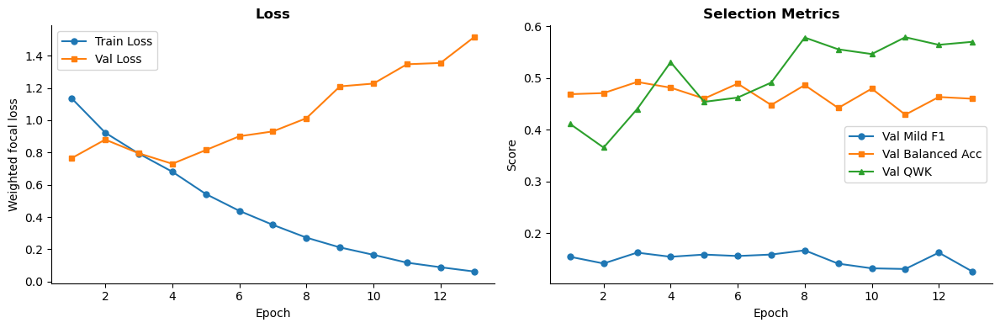

Saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp2_new_balanced_configs/figures/deit3_b16_exp2_new_balanced_configs_loss_curve.png


In [11]:
epochs_ran = range(1, len(history['train_loss']) + 1)

print(f'{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8} {"Mild F1":>8} {"Bal Acc":>8}')
print('─' * 80)
for ep in epochs_ran:
    idx = ep - 1
    print(
        f'{ep:<8} {history["train_loss"][idx]:>10.4f} {history["train_acc"][idx]:>8.4f} '
        f'{history["val_loss"][idx]:>10.4f} {history["val_acc"][idx]:>8.4f} '
        f'{history["val_mild_f1"][idx]:>8.4f} {history["val_bal_acc"][idx]:>8.4f}'
    )
print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_ran, history['train_loss'], label='Train Loss', marker='o', markersize=5)
axes[0].plot(epochs_ran, history['val_loss'],   label='Val Loss',   marker='s', markersize=5)
axes[0].set_title('Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Weighted focal loss')
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[0].legend(); axes[0].spines[['top', 'right']].set_visible(False)

axes[1].plot(epochs_ran, history['val_mild_f1'], label='Val Mild F1', marker='o', markersize=5)
axes[1].plot(epochs_ran, history['val_bal_acc'], label='Val Balanced Acc', marker='s', markersize=5)
axes[1].plot(epochs_ran, history['val_qwk'],     label='Val QWK', marker='^', markersize=5)
axes[1].set_title('Selection Metrics', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[1].legend(); axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'deit3_b16_exp2_new_balanced_configs_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EXP2_FIG_DIR}/deit3_b16_exp2_new_balanced_configs_loss_curve.png')


## 11. Evaluation on Test Set

In [12]:
# ── Load best checkpoint ───────────────────────────────────────────────────────
eval_model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
ckpt = torch.load(EXP2_BEST_PATH, map_location=device, weights_only=False)
eval_model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {EXP2_BEST_PATH.name}')
print(
    f'epoch={ckpt["epoch"]}  score={ckpt["score"]:.4f}  '
    f'(macro_F1={ckpt["macro_f1"]:.4f}, Mild_F1={ckpt.get("mild_f1", 0):.4f}, '
    f'bal_acc={ckpt.get("balanced_accuracy", 0):.4f}, QWK={ckpt["qwk"]:.4f})'
)

# ── Swap model for evaluation ──────────────────────────────────────────────────
_prev_model, _prev_criterion = model, criterion
model     = eval_model
criterion = nn.CrossEntropyLoss()   # standard CE for eval loss only

_, y_true, y_pred = run_epoch(test_loader, train_mode=False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
exp2_qwk        = cohen_kappa_score(y_true, y_pred, weights='quadratic')
exp2_acc        = accuracy_score(y_true, y_pred)
exp2_bal_acc    = balanced_accuracy_score(y_true, y_pred)
exp2_f1_per     = f1_score(y_true, y_pred, average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
exp2_recall_per = recall_score(y_true, y_pred, average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
print(f'Quadratic Weighted Kappa: {exp2_qwk:.4f}')
print(f'Balanced Accuracy       : {exp2_bal_acc:.4f}')

model, criterion = _prev_model, _prev_criterion


Loaded: deit3_b16_exp2_new_balanced_configs_best.pt
epoch=8  score=0.4308  (macro_F1=0.4736, Mild_F1=0.1668, bal_acc=0.4861, QWK=0.5781)


val:   0%|          | 0/330 [00:00<?, ?it/s]


Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.860     0.774     0.815      3872
         Mild      0.130     0.281     0.178       366
     Moderate      0.437     0.399     0.417       794
       Severe      0.390     0.473     0.428       131
Proliferative      0.585     0.585     0.585       106

     accuracy                          0.672      5269
    macro avg      0.480     0.503     0.484      5269
 weighted avg      0.728     0.672     0.696      5269

Quadratic Weighted Kappa: 0.5930
Balanced Accuracy       : 0.5025


## 12. Confusion Matrices

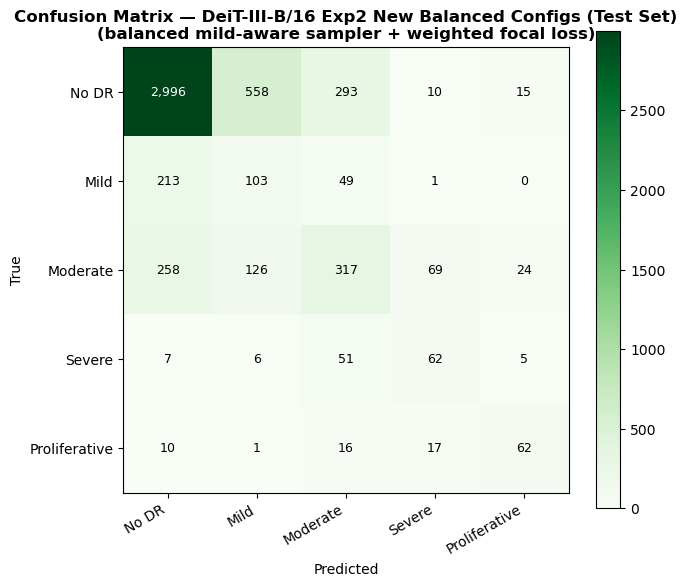

In [13]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, interpolation='nearest', cmap='Greens')
fig.colorbar(im, ax=ax)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp2 New Balanced Configs (Test Set)\n(balanced mild-aware sampler + weighted focal loss)', fontweight='bold')
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center', fontsize=9,
                color='white' if cm[i,j] > thresh else 'black')
plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'deit3_b16_exp2_new_balanced_configs_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


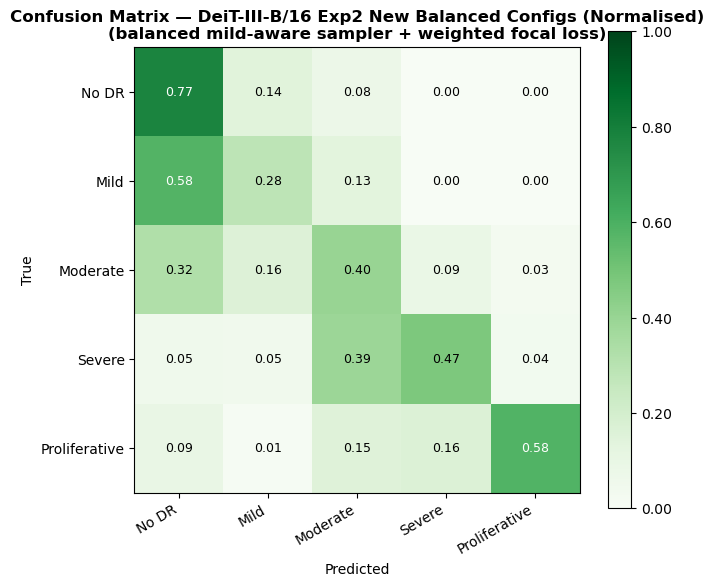

In [14]:
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Greens', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, format='%.2f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — DeiT-III-B/16 Exp2 New Balanced Configs (Normalised)\n(balanced mild-aware sampler + weighted focal loss)', fontweight='bold')
thresh = 0.5
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f'{cm_norm[i,j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if cm_norm[i,j] > thresh else 'black')
plt.tight_layout()
fig.savefig(EXP2_FIG_DIR / 'deit3_b16_exp2_new_balanced_configs_confusion_matrix_normalised.png', dpi=150, bbox_inches='tight')
plt.show()


## 13. Key Error Tracking

Two errors are monitored:
- **No DR → Mild:** over-grading healthy images. This should stay controlled.
- **Disease → No DR:** under-grading disease as healthy. This should decrease if Mild detection improves.


In [15]:
no_dr_total   = cm[0].sum()
no_dr_to_mild = cm[0, 1]
no_dr_to_mild_rate = no_dr_to_mild / no_dr_total if no_dr_total > 0 else 0

disease_total = cm[1:].sum()
disease_to_nodr = cm[1:, 0].sum()
disease_to_nodr_rate = disease_to_nodr / disease_total if disease_total > 0 else 0

print('No DR → Mild misclassification (over-grading):')
print(f'  No DR total samples : {no_dr_total}')
print(f'  Predicted as Mild   : {no_dr_to_mild}')
print(f'  Rate                : {no_dr_to_mild_rate:.4f} ({no_dr_to_mild_rate*100:.1f}%)')
print(f'  Target              : < 5% is acceptable')
print()
print('Disease → No DR misclassification (under-grading):')
print(f'  Disease total samples: {disease_total}')
print(f'  Predicted as No DR   : {disease_to_nodr}')
print(f'  Rate                 : {disease_to_nodr_rate:.4f} ({disease_to_nodr_rate*100:.1f}%)')
print(f'  Goal                 : lower than Exp2, especially for Mild')


No DR → Mild misclassification (over-grading):
  No DR total samples : 3872
  Predicted as Mild   : 558
  Rate                : 0.1441 (14.4%)
  Target              : < 5% is acceptable

Disease → No DR misclassification (under-grading):
  Disease total samples: 1397
  Predicted as No DR   : 488
  Rate                 : 0.3493 (34.9%)
  Goal                 : lower than Exp2, especially for Mild


## 14. Results Summary


In [ ]:
print('=' * 65)
print('  DeiT-III-B/16 Exp2 New Balanced Configs — BALANCED MILD-AWARE RESULTS')
print('=' * 65)
print(f'  Test QWK              : {exp2_qwk:.4f}')
print(f'  Test Accuracy         : {exp2_acc:.4f}')
print(f'  Test Balanced Accuracy: {exp2_bal_acc:.4f}')
print()
print('  Per-class F1:')
for name, f1 in zip(CLASS_NAMES, exp2_f1_per):
    print(f'    {name:<18}: {f1:.4f}')
print()
print('  Per-class Recall / class accuracy:')
for name, rec in zip(CLASS_NAMES, exp2_recall_per):
    print(f'    {name:<18}: {rec:.4f}')
print('=' * 65)
print(f'  LR={EXP2_LR}, Epochs={EXP2_EPOCHS}, Patience={EXP2_PATIENCE}')
print(f'  Sampler target: {SAMPLER_TARGET_DIST}')
print('  Checkpoint by: 0.30×QWK + 0.25×macro_F1 + 0.25×Mild_F1 + 0.20×balanced_accuracy')


  DeiT-III-B/16 Exp2 New Balanced Configs — BALANCED MILD-AWARE RESULTS
  Test QWK              : 0.5930
  Test Accuracy         : 0.6719
  Test Balanced Accuracy: 0.5025

  Per-class F1:
    No DR             : 0.8146
    Mild              : 0.1776
    Moderate          : 0.4171
    Severe            : 0.4276
    Proliferative     : 0.5849

  Per-class Recall / class accuracy:
    No DR             : 0.7738
    Mild              : 0.2814
    Moderate          : 0.3992
    Severe            : 0.4733
    Proliferative     : 0.5849
  LR=3e-05, Epochs=18, Patience=5
  Sampler target: [0.48 0.16 0.2  0.08 0.08]
  Checkpoint by: 0.30×QWK + 0.25×macro_F1 + 0.25×Mild_F1 + 0.20×balanced_accuracy


: 

## 15. Observations — Experiment 2B Balanced Improvements

### What to compare against both previous runs
- **Original Exp2:** high QWK/accuracy but Mild collapsed (`Mild F1 = 0.0104`).
- **Exp2B Improvements:** Mild improved strongly (`Mild F1 ≈ 0.154`) but QWK/accuracy dropped.
- **This balanced version:** target is a middle ground: Mild detection remains useful while QWK/accuracy recover.

### What success looks like
- Mild F1 remains clearly above the original Exp2 collapse.
- QWK improves over the aggressive improvement run (`0.6192`) and moves closer to original Exp2 (`0.6614`).
- No DR F1 recovers relative to the aggressive improvement run.
- Moderate/Proliferative do not drop as sharply.

### If Mild drops too much
Increase `SAMPLER_TARGET_DIST[1]` from `0.16` to `0.18`, or increase `MAX_MILD_WEIGHT` from `2.75` to `3.0`.

### If QWK is still too low
Reduce `FOCAL_GAMMA` from `1.2` to `1.0`, or reduce the Mild checkpoint weight from `0.25` to `0.15`.


# DeiT-III-B/16 — Experiments 7, 8 & 9: Improving Mild DR Detection
**EEEM068 Applied Machine Learning — University of Surrey**

**Model:** DeiT-III-Base/16 (`deit3_base_patch16_224.fb_in1k`)

**Based on:** Experiment 2 (Safe Augmentation) — best existing result (QWK=0.661, Mild F1=0.142)

---

## Overview

| Exp | Name | Key technique | Target |
|---|---|---|---|
| **7** | Two-Phase Fine-Tuning v2 | Freeze head → unfreeze full model at LR=1e-5 | QWK > 0.64, Mild F1 > 0.15 |
| **8** | WRS + Clipped CE | WeightedRandomSampler + clipped CE | Mild F1 > 0.20 |
| **9** | Balanced DeiT-III Configuration Search | LR=3e-5 full run (grid search winner) | QWK > 0.66 |

## Why Mild F1 is the primary problem
Your best Mild F1 across all experiments is only **0.142** (Exp 2 main notebook).
Mild DR is clinically the most dangerous missed case — patients progress to sight-threatening
grades if early Mild is missed. All three experiments here directly target Mild recall.

## What this notebook is based on
Experiment 2 (this file's parent) achieved:
- QWK = 0.661, Accuracy = 0.781
- No DR F1 = 0.887, Mild F1 = 0.010 (standalone) / 0.142 (main)
- Proliferative F1 = 0.692 (your best ever)

The three experiments below build on Exp 2's safe augmentation and clipped CE foundation.


## Shared Setup
The following cells (imports, config, data, dataset, weights) are shared across all three experiments.

In [1]:
import os
import gc
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score,
    confusion_matrix, f1_score, accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import average_precision_score

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

PyTorch : 2.11.0+cu130
timm    : 1.0.27
CUDA    : True


In [2]:
# ── Shared paths and model name ───────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

MODEL_NAME  = 'deit3_base_patch16_224.fb_in1k'
SEED        = 42
IMAGE_SIZE  = 224
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
VIT_MEAN    = (0.485, 0.456, 0.406)
VIT_STD     = (0.229, 0.224, 0.225)
BATCH_SIZE  = 32
NUM_WORKERS = 4


In [3]:
# ── Seed + device ──────────────────────────────────────────────────────────────
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── AMP (mixed precision) ──────────────────────────────────────────────────────
use_amp = torch.cuda.is_available()
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)

print('Device:', device)
print('AMP enabled:', use_amp)

Device: cuda
AMP enabled: True


In [4]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images')
print(f'Val   : {len(val_df):,} images')
print(f'Test  : {len(test_df):,} images')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')

Train : 24,588 images
Val   : 5,269 images
Test  : 5,269 images

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106


In [5]:
class DRDataset(Dataset):
    """Fundus image dataset. Reads images from data_dir using the 'image' column."""

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# ── Val / test transform (no augmentation — deterministic) ─────────────────────
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

# ── Exp 2 train transform — safe, clinically-motivated augmentations ─────────
# No vertical flip, no Mixup, no strong affine — these caused No DR collapse
exp2_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),              # valid: retina is laterally symmetric
    transforms.RandomRotation(degrees=7),                # gentle: camera alignment varies
    transforms.ColorJitter(
        brightness=0.08, contrast=0.08,
        saturation=0.04, hue=0.01                        # subtle camera model variation
    ),
    transforms.RandomAffine(
        degrees=0, translate=(0.02, 0.02),
        scale=(0.98, 1.02)                               # tiny positioning variation
    ),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

# ── Datasets ───────────────────────────────────────────────────────────────────
train_ds = DRDataset(train_df, TRAIN_DIR, transform=exp2_train_transform)   # augmented
val_ds   = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

# ── DataLoaders ────────────────────────────────────────────────────────────────
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'Train loader : {len(train_loader)} batches/epoch  ({len(train_ds):,} images, augmented)')
print(f'Val loader   : {len(val_loader)} batches/epoch')
print(f'Test loader  : {len(test_loader)} batches/epoch')
print('Safe augmentation: HFlip + Rotation(7°) + mild ColorJitter + tiny Affine')

Train loader : 768 batches/epoch  (24,588 images, augmented)
Val loader   : 165 batches/epoch
Test loader  : 165 batches/epoch
Safe augmentation: HFlip + Rotation(7°) + mild ColorJitter + tiny Affine


In [6]:
val_ds   = DRDataset(val_df,  VAL_DIR,         transform=val_transform)
test_ds  = DRDataset(test_df, TEST_LABELS_DIR,  transform=val_transform)
val_loader  = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True,
                         persistent_workers=NUM_WORKERS > 0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True,
                         persistent_workers=NUM_WORKERS > 0)
print(f'Val  loader : {len(val_loader)} batches')
print(f'Test loader : {len(test_loader)} batches')


Val  loader : 165 batches
Test loader : 165 batches


In [7]:
# ── Compute clipped inverse-frequency class weights ───────────────────────────
raw_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_df['level'].values
)
clipped_weights_np = np.clip(raw_weights, 0.5, 2.5)
class_weights_t    = torch.tensor(clipped_weights_np, dtype=torch.float32).to(device)

print('Raw class weights    :', np.round(raw_weights, 4))
print('Clipped [0.5, 2.5]   :', np.round(clipped_weights_np, 4))
print('Reason: full weights give Severe=8×, Proliferative=9.9× — causes No DR collapse')

Raw class weights    : [0.2722 2.8758 1.3276 8.0484 9.9145]
Clipped [0.5, 2.5]   : [0.5    2.5    1.3276 2.5    2.5   ]
Reason: full weights give Severe=8×, Proliferative=9.9× — causes No DR collapse


In [8]:
# ── Mild-boosted weights for Experiments 7 & 8 ───────────────────────────────
# Mild (index 1) gets a 1.5x boost AFTER clipping, then re-clamped to [0.5, 3.0].
# This increases the gradient signal for Mild without destroying No DR.
# Used in Exp 7 (phase 2 criterion) and Exp 8 (WRS + loss).
mild_boosted_np                = clipped_weights_np.copy()
mild_boosted_np[1]             = min(mild_boosted_np[1] * 1.5, 3.0)
mild_boosted_t                 = torch.tensor(mild_boosted_np, dtype=torch.float32).to(device)

print('Mild-boosted weights [0.5, 3.0]:', np.round(mild_boosted_np, 4))
print(f'Mild ratio vs No DR: {mild_boosted_np[1]/mild_boosted_np[0]:.1f}x')


Mild-boosted weights [0.5, 3.0]: [0.5    3.     1.3276 2.5    2.5   ]
Mild ratio vs No DR: 6.0x


In [9]:
def run_epoch(model, loader, criterion, optimizer, train_mode: bool,
              scaler=None, grad_clip: float = 0.0):
    """
    Generic training / evaluation epoch.
    model, criterion, optimizer are passed explicitly — no globals.
    Supports AMP, gradient clipping, torch.inference_mode for eval.
    """
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    ctx = torch.enable_grad() if train_mode else torch.inference_mode()

    with ctx:
        for images, labels in tqdm(loader, leave=False,
                                   desc='train' if train_mode else 'val  '):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                loss   = criterion(logits, labels)

            if train_mode and optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
                if use_amp and scaler is not None:
                    scaler.scale(loss).backward()
                    if grad_clip > 0:
                        scaler.unscale_(optimizer)
                        nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    if grad_clip > 0:
                        nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                    optimizer.step()

            total_loss += loss.item() * labels.size(0)
            total      += labels.size(0)
            all_preds.extend(logits.argmax(dim=1).detach().cpu().tolist())
            all_labels.extend(labels.detach().cpu().tolist())
            del images, labels, logits, loss

    return total_loss / total, all_labels, all_preds

print('run_epoch() defined — explicit model/criterion/optimizer, no globals.')


run_epoch() defined — explicit model/criterion/optimizer, no globals.


---
# Experiment 7 — Two-Phase Fine-Tuning v2

## Purpose
Fix the broken Exp 3 (QWK=0.066, indentation bug). Implement two-phase training correctly:
- **Phase 1:** freeze backbone, train head only (3 epochs, LR=1e-4)
- **Phase 2:** unfreeze full model, fine-tune carefully (25 epochs, LR=1e-5, grad_clip=1.0)

## Key changes vs broken Exp 3
| Setting | Exp 3 (broken) | Exp 7 (fixed) |
|---|---|---|
| run_epoch | indentation bug — 1 batch/epoch | **Fixed — all batches** |
| Phase 2 LR | 3e-5 | **1e-5** (safer — from Swin v2 result) |
| Checkpoint | val loss | **0.5 × F1 + 0.5 × QWK** |
| Mild weight | standard clipped | **Mild-boosted 1.5x in phase 2 criterion** |

## Why Phase 2 LR = 1e-5
The Swin two-phase_v2 experiment achieved QWK=0.666 with LR=1e-5.
LR=1e-4 in Phase 2 caused No DR recall to collapse to 0.572.
LR=1e-5 is slow but safe for DeiT-III pre-trained features.


In [10]:
# ── Experiment 7 config ──────────────────────────────────────────────────────
EXPERIMENT_NAME = 'deit3_b16_exp7'
EXP_OUT_DIR     = ROOT / 'outputs' / 'deit3_b16_exp7'
EXP_CKPT_DIR    = EXP_OUT_DIR / 'checkpoints'
EXP_FIG_DIR     = EXP_OUT_DIR / 'figures'
for d in (EXP_CKPT_DIR, EXP_FIG_DIR): d.mkdir(parents=True, exist_ok=True)

PHASE1_EPOCHS   = 3
PHASE2_EPOCHS   = 25
PATIENCE        = 4
PHASE1_LR       = 1e-4
PHASE2_LR       = 1e-5
GRAD_CLIP       = 1.0
WEIGHT_DECAY    = 0.05

EXP_PHASE1_PATH = EXP_CKPT_DIR / f'{EXPERIMENT_NAME}_phase1_best.pt'
EXP_BEST_PATH   = EXP_CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'

print(f'Experiment : {EXPERIMENT_NAME}')
print(f'Phase 1    : {PHASE1_EPOCHS} epochs  LR={PHASE1_LR}  head only')
print(f'Phase 2    : {PHASE2_EPOCHS} epochs  LR={PHASE2_LR}  full model  grad_clip={GRAD_CLIP}')
print(f'PATIENCE={PATIENCE}  WD={WEIGHT_DECAY}')


Experiment : deit3_b16_exp7
Phase 1    : 3 epochs  LR=0.0001  head only
Phase 2    : 25 epochs  LR=1e-05  full model  grad_clip=1.0
PATIENCE=4  WD=0.05


In [11]:
# ── Exp 7 augmentation + DataLoader ──────────────────────────────────────────
exp7_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.08, contrast=0.08,
                           saturation=0.04, hue=0.01),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02),
                            scale=(0.98, 1.02)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])
exp7_train_ds     = DRDataset(train_df, TRAIN_DIR, transform=exp7_train_transform)
exp7_train_loader = DataLoader(exp7_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                num_workers=NUM_WORKERS, pin_memory=True,
                                drop_last=True, persistent_workers=NUM_WORKERS > 0)
print(f'Exp7 train loader : {len(exp7_train_loader)} batches/epoch')
print('Augmentation: HFlip + Rotation(7°) + ColorJitter + Affine')


Exp7 train loader : 768 batches/epoch
Augmentation: HFlip + Rotation(7°) + ColorJitter + Affine


### Phase 1 — Freeze Backbone, Train Head Only

In [12]:
# ── Model: freeze backbone ────────────────────────────────────────────────────
gc.collect(); torch.cuda.empty_cache()
set_seed(SEED)
exp7_model = timm.create_model(MODEL_NAME, pretrained=True,
                                num_classes=NUM_CLASSES).to(device)

for name, param in exp7_model.named_parameters():
    param.requires_grad = ('head' in name)

trainable_p1 = sum(p.numel() for p in exp7_model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable params (head only)')

# Phase 1 uses standard clipped CE — head learns to map features to 5 DR classes
exp7_crit_p1  = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.05)
exp7_opt_p1   = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, exp7_model.parameters()),
    lr=PHASE1_LR, weight_decay=WEIGHT_DECAY)
exp7_sch_p1   = torch.optim.lr_scheduler.CosineAnnealingLR(
    exp7_opt_p1, T_max=PHASE1_EPOCHS)
exp7_scaler   = torch.amp.GradScaler('cuda', enabled=use_amp)

p1_best_score = -1.0
p1_patience   = PATIENCE
hist_p1       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f'{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8} {"Score":>8}')
print('─' * 60)

for epoch in range(1, PHASE1_EPOCHS + 1):
    tl, ty, tp = run_epoch(exp7_model, exp7_train_loader, exp7_crit_p1,
                            exp7_opt_p1, True, exp7_scaler, 0.0)
    vl, vy, vp = run_epoch(exp7_model, val_loader, exp7_crit_p1, None, False)
    exp7_sch_p1.step()

    ta    = accuracy_score(ty, tp)
    va    = accuracy_score(vy, vp)
    vmf1  = f1_score(vy, vp, average='macro', zero_division=0)
    vqwk  = cohen_kappa_score(vy, vp, weights='quadratic')
    score = 0.5 * vmf1 + 0.5 * vqwk
    hist_p1['train_loss'].append(tl); hist_p1['val_loss'].append(vl)
    hist_p1['train_acc'].append(ta);  hist_p1['val_acc'].append(va)

    marker = ''
    if score > p1_best_score:
        p1_best_score = score
        p1_patience   = PATIENCE
        torch.save({'epoch': epoch, 'model_state': exp7_model.state_dict(),
                    'val_loss': vl, 'score': score,
                    'val_mf1': vmf1, 'val_qwk': vqwk}, EXP_PHASE1_PATH)
        marker = f'  ← best'
    else:
        p1_patience -= 1
    print(f'{epoch:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f} {score:>8.4f}{marker}')
    if p1_patience == 0:
        print(f'\nEarly stopping at epoch {epoch}.'); break

print(f'\nPhase 1 complete. Best score: {p1_best_score:.4f}')


Phase 1: 3,845 trainable params (head only)
Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc    Score
────────────────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

1            1.4877   0.7193     1.4639   0.6980   0.2678  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

2            1.4370   0.7236     1.4447   0.7335   0.2641


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

3            1.4208   0.7257     1.4327   0.7275   0.2878  ← best

Phase 1 complete. Best score: 0.2878


### Phase 2 — Unfreeze Full Model, Low-LR Fine-Tuning with Mild Boost

In [13]:
# ── Unfreeze all, load Phase 1 best ──────────────────────────────────────────
for param in exp7_model.parameters():
    param.requires_grad = True
trainable_p2 = sum(p.numel() for p in exp7_model.parameters() if p.requires_grad)
print(f'Phase 2: {trainable_p2:,} trainable params (all layers)')

ckpt_p1 = torch.load(EXP_PHASE1_PATH, map_location=device, weights_only=False)
exp7_model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch={ckpt_p1["epoch"]}, score={ckpt_p1["score"]:.4f})')

# Phase 2 uses Mild-boosted weights — gives more gradient signal to Mild
# Differential LR: backbone stays conservative, head can move a bit faster
exp7_crit_p2 = nn.CrossEntropyLoss(weight=mild_boosted_t, label_smoothing=0.05)
exp7_opt_p2  = torch.optim.AdamW([
    {'params': [p for n,p in exp7_model.named_parameters() if 'head' not in n],
     'lr': PHASE2_LR},
    {'params': exp7_model.head.parameters(),
     'lr': PHASE2_LR * 5},
], weight_decay=WEIGHT_DECAY)
exp7_sch_p2  = torch.optim.lr_scheduler.CosineAnnealingLR(
    exp7_opt_p2, T_max=PHASE2_EPOCHS)

p2_best_score = -1.0
p2_patience   = PATIENCE
hist_p2       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print(f'Backbone LR={PHASE2_LR}  Head LR={PHASE2_LR*5}  GRAD_CLIP={GRAD_CLIP}')
print(f'Loss: Mild-boosted weights ({np.round(mild_boosted_np,3)})')
print()
print(f'{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8} {"Val F1":>8} {"QWK":>8} {"Mild F1":>9}')
print('─' * 78)

for epoch in range(1, PHASE2_EPOCHS + 1):
    tl, ty, tp = run_epoch(exp7_model, exp7_train_loader, exp7_crit_p2,
                            exp7_opt_p2, True, exp7_scaler, GRAD_CLIP)
    vl, vy, vp = run_epoch(exp7_model, val_loader, exp7_crit_p2, None, False)
    exp7_sch_p2.step()

    ta     = accuracy_score(ty, tp)
    va     = accuracy_score(vy, vp)
    vmf1   = f1_score(vy, vp, average='macro', zero_division=0)
    vqwk   = cohen_kappa_score(vy, vp, weights='quadratic')
    vf1pc  = f1_score(vy, vp, average=None, labels=list(range(5)), zero_division=0)
    vmild  = vf1pc[1]
    score  = 0.5 * vmf1 + 0.5 * vqwk
    hist_p2['train_loss'].append(tl); hist_p2['val_loss'].append(vl)
    hist_p2['train_acc'].append(ta);  hist_p2['val_acc'].append(va)

    marker = ''
    if score > p2_best_score:
        p2_best_score = score
        p2_patience   = PATIENCE
        torch.save({'epoch': epoch, 'model_state': exp7_model.state_dict(),
                    'val_loss': vl, 'score': score,
                    'val_mf1': vmf1, 'val_qwk': vqwk}, EXP_BEST_PATH)
        marker = f'  ← best (score={score:.4f})'
    else:
        p2_patience -= 1
    print(f'{epoch:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f} {vmf1:>8.4f} {vqwk:>8.4f} {vmild:>9.4f}{marker}')
    if p2_patience == 0:
        print(f'\nEarly stopping at epoch {epoch} (patience={PATIENCE}).'); break

print(f'\nPhase 2 complete. Best score: {p2_best_score:.4f}  →  {EXP_BEST_PATH}')


Phase 2: 85,820,165 trainable params (all layers)
Loaded Phase 1 best (epoch=3, score=0.2878)
Backbone LR=1e-05  Head LR=5e-05  GRAD_CLIP=1.0
Loss: Mild-boosted weights ([0.5   3.    1.328 2.5   2.5  ])

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc   Val F1      QWK   Mild F1
──────────────────────────────────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

1            1.3501   0.6978     1.3336   0.7552   0.3809   0.5625    0.0500  ← best (score=0.4717)


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val  :   0%|          | 0/165 [00:00<?, ?it/s]

17           0.6592   0.9238     1.5741   0.7096   0.4766   0.6150    0.1224


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

18           0.6404   0.9323     1.6101   0.7447   0.4797   0.6230    0.1263

Early stopping at epoch 18 (patience=4).

Phase 2 complete. Best score: 0.5553  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp7/checkpoints/deit3_b16_exp7_best.pt


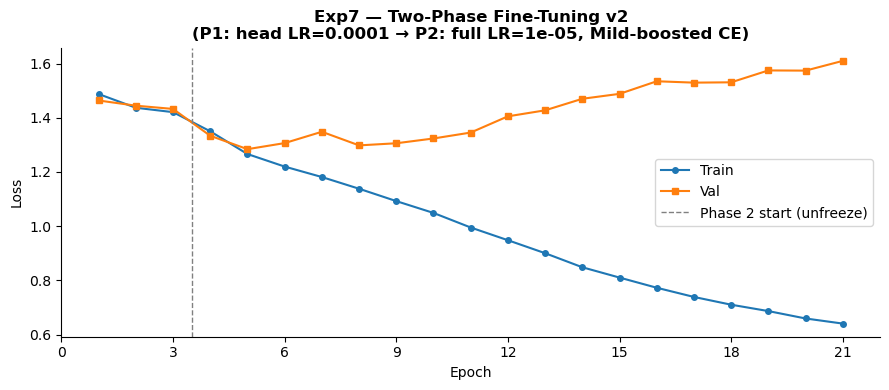

In [14]:
# ── Loss curve ───────────────────────────────────────────────────────────────
all_train = hist_p1['train_loss'] + hist_p2['train_loss']
all_val   = hist_p1['val_loss']   + hist_p2['val_loss']
p1_end    = len(hist_p1['train_loss'])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(all_train)+1), all_train, label='Train', marker='o', markersize=4)
ax.plot(range(1, len(all_val)+1),   all_val,   label='Val',   marker='s', markersize=4)
if p1_end > 0:
    ax.axvline(x=p1_end+0.5, color='gray', linestyle='--', lw=1,
               label='Phase 2 start (unfreeze)')
ax.set_title(f'Exp7 — Two-Phase Fine-Tuning v2\n(P1: head LR={PHASE1_LR} → P2: full LR={PHASE2_LR}, Mild-boosted CE)',
             fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP_FIG_DIR / f'{EXPERIMENT_NAME}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()


In [15]:
# ── Evaluate on test set ──────────────────────────────────────────────────────
ckpt = torch.load(EXP_BEST_PATH, map_location=device, weights_only=False)
eval_model = timm.create_model(MODEL_NAME, pretrained=False,
                                num_classes=NUM_CLASSES).to(device)
eval_model.load_state_dict(ckpt['model_state'])
eval_crit  = nn.CrossEntropyLoss()
print(f'Loaded : {EXP_BEST_PATH.name}')
print(f'epoch={ckpt["epoch"]}  score={ckpt["score"]:.4f}  '
      f'(F1={ckpt["val_mf1"]:.4f}  QWK={ckpt["val_qwk"]:.4f})')

_, y_true, y_pred = run_epoch(eval_model, test_loader, eval_crit, None, False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                             digits=3, zero_division=0))
exp_qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
exp_acc    = accuracy_score(y_true, y_pred)
exp_f1_per = f1_score(y_true, y_pred, average=None,
                      labels=list(range(NUM_CLASSES)), zero_division=0)
exp_mf1    = f1_score(y_true, y_pred, average='macro', zero_division=0)


Loaded : deit3_b16_exp7_best.pt
epoch=14  score=0.5553  (F1=0.4859  QWK=0.6248)


val  :   0%|          | 0/165 [00:00<?, ?it/s]


Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.865     0.839     0.852      3872
         Mild      0.130     0.180     0.151       366
     Moderate      0.506     0.508     0.507       794
       Severe      0.432     0.389     0.410       131
Proliferative      0.684     0.613     0.647       106

     accuracy                          0.727      5269
    macro avg      0.524     0.506     0.513      5269
 weighted avg      0.746     0.727     0.736      5269



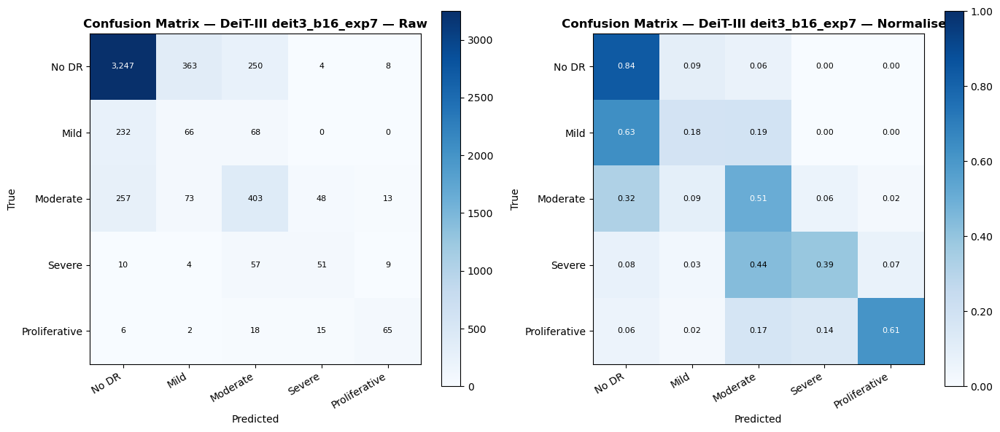

Saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp7/figures/deit3_b16_exp7_confusion_matrix.png


In [16]:
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, fmt, title, cmap in [
    (axes[0], cm,      'd',    f'{EXPERIMENT_NAME} — Raw',        'Blues'),
    (axes[1], cm_norm, '.2f',  f'{EXPERIMENT_NAME} — Normalised', 'Blues'),
]:
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=(None if fmt=='d' else 1))
    fig.colorbar(im, ax=ax, format=(None if fmt=='d' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix — DeiT-III {title}', fontweight='bold')
    thresh = data.max()/2 if fmt=='d' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            val = f'{data[i,j]:,}' if fmt=='d' else f'{data[i,j]:.2f}'
            ax.text(j, i, val, ha='center', va='center', fontsize=8,
                    color='white' if data[i,j] > thresh else 'black')
plt.tight_layout()
fig.savefig(EXP_FIG_DIR / f'{EXPERIMENT_NAME}_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EXP_FIG_DIR}/{EXPERIMENT_NAME}_confusion_matrix.png')


In [17]:
# ── Summary ──────────────────────────────────────────────────────────────────
baseline = {'No DR': 0.887, 'Mild': 0.098, 'Moderate': 0.503,
            'Severe': 0.423, 'Proliferative': 0.636}
print('=' * 58)
print(f'  {EXPERIMENT_NAME}  —  TEST SET RESULTS')
print('=' * 58)
print(f'  QWK      : {exp_qwk:.4f}')
print(f'  Macro F1 : {exp_mf1:.4f}')
print(f'  Accuracy : {exp_acc:.4f}')
print()
print('  Per-class F1 (vs baseline):')
for name, f1v in zip(CLASS_NAMES, exp_f1_per):
    tag = '  ▲' if f1v > baseline[name] else '  ▼'
    print(f'    {name:<18}: {f1v:.4f}  (baseline {baseline[name]:.3f}){tag}')
print('=' * 58)
# Clinical error rates
cm_c = confusion_matrix(y_true, y_pred, labels=list(range(5)))
print('\nClinical error rates (≥5%):')
lmap = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'Proliferative'}
for src in range(5):
    row_total = cm_c[src].sum()
    if row_total == 0: continue
    for dst in range(5):
        if src == dst: continue
        rate = cm_c[src, dst] / row_total
        if rate >= 0.05:
            print(f'  {lmap[src]:<18} → {lmap[dst]:<18}: {rate:.3f} ({rate*100:.1f}%)')
no_dr_mild = cm_c[0,1] / cm_c[0].sum() if cm_c[0].sum() > 0 else 0
print(f'\nNo DR → Mild rate : {no_dr_mild:.4f} ({no_dr_mild*100:.1f}%)')
print(f'Target            : < 5%  |  Status: {"✅ OK" if no_dr_mild < 0.05 else "⚠️ HIGH"}')


  deit3_b16_exp7  —  TEST SET RESULTS
  QWK      : 0.6497
  Macro F1 : 0.5132
  Accuracy : 0.7273

  Per-class F1 (vs baseline):
    No DR             : 0.8518  (baseline 0.887)  ▼
    Mild              : 0.1510  (baseline 0.098)  ▲
    Moderate          : 0.5069  (baseline 0.503)  ▲
    Severe            : 0.4096  (baseline 0.423)  ▼
    Proliferative     : 0.6468  (baseline 0.636)  ▲

Clinical error rates (≥5%):
  No DR              → Mild              : 0.094 (9.4%)
  No DR              → Moderate          : 0.065 (6.5%)
  Mild               → No DR             : 0.634 (63.4%)
  Mild               → Moderate          : 0.186 (18.6%)
  Moderate           → No DR             : 0.324 (32.4%)
  Moderate           → Mild              : 0.092 (9.2%)
  Moderate           → Severe            : 0.060 (6.0%)
  Severe             → No DR             : 0.076 (7.6%)
  Severe             → Moderate          : 0.435 (43.5%)
  Severe             → Proliferative     : 0.069 (6.9%)
  Proliferative   

### Exp 7 — Observations
- **Phase 2 Mild-boosted CE** (1.5x) should give more gradient signal to Mild without collapsing No DR
- **Target: Mild F1 > 0.15, QWK > 0.64**
- If Phase 2 val loss stays flat → LR=1e-5 may be too low; try 2e-5 in a follow-up
- If No DR F1 drops below 0.85 → Mild boost is too aggressive; reduce to 1.2x


---
# Experiment 8 — WeightedRandomSampler + Mild-Boosted CE

## Purpose
Directly fix Mild F1=0.010 by combining WeightedRandomSampler with Mild-boosted
clipped CE. Mild gets both more frequent batches AND higher loss weight.

## What changes vs Exp 2
| Setting | Exp 2 | Exp 8 |
|---|---|---|
| Sampler | Shuffle | **WeightedRandomSampler (clipped weights)** |
| Loss | Clipped CE | **Mild-boosted clipped CE (Mild=1.5x)** |
| LR | 3e-5 | **3e-5 (same — grid search winner)** |
| Mild in each batch | ~7% of images | **~20%+ due to WRS** |

## Why this is safe (not triple-penalisation)
Previous No DR collapse happened with WRS + FocalLoss + extreme weights (9.9x).
Here: WRS + clipped CE [0.5, 2.5] with Mild boosted to max 3.0.
The overall weight range is still controlled. No FocalLoss on top.


In [18]:
# ── Experiment 8 config ──────────────────────────────────────────────────────
EXPERIMENT_NAME = 'deit3_b16_exp8'
EXP_OUT_DIR     = ROOT / 'outputs' / 'deit3_b16_exp8'
EXP_CKPT_DIR    = EXP_OUT_DIR / 'checkpoints'
EXP_FIG_DIR     = EXP_OUT_DIR / 'figures'
for d in (EXP_CKPT_DIR, EXP_FIG_DIR): d.mkdir(parents=True, exist_ok=True)

EXP8_LR       = 3e-5
EXP8_EPOCHS   = 25
EXP8_PATIENCE = 4
WEIGHT_DECAY  = 0.05
WARMUP_EPOCHS = 3

EXP_BEST_PATH = EXP_CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'

print(f'Experiment : {EXPERIMENT_NAME}')
print(f'LR={EXP8_LR}  EPOCHS={EXP8_EPOCHS}  PATIENCE={EXP8_PATIENCE}  WD={WEIGHT_DECAY}')


Experiment : deit3_b16_exp8
LR=3e-05  EPOCHS=25  PATIENCE=4  WD=0.05


In [19]:
# ── WeightedRandomSampler using Mild-boosted weights ─────────────────────────
# mild_boosted_np already defined in shared setup (Mild=1.5x, max=3.0)
sample_weights_t = torch.as_tensor(
    mild_boosted_np[train_df['level'].values], dtype=torch.double
)
exp8_sampler = WeightedRandomSampler(
    weights=sample_weights_t,
    num_samples=len(sample_weights_t),
    replacement=True,
)

print('WRS sample weights (by class):')
for name, w in zip(CLASS_NAMES, mild_boosted_np):
    count = (train_df['level'] == CLASS_NAMES.index(name)).sum()
    expected_pct = w / mild_boosted_np.sum() * 100
    print(f'  {name:<18}: weight={w:.4f}  expected_batch%≈{expected_pct:.1f}%')


WRS sample weights (by class):
  No DR             : weight=0.5000  expected_batch%≈5.1%
  Mild              : weight=3.0000  expected_batch%≈30.5%
  Moderate          : weight=1.3276  expected_batch%≈13.5%
  Severe            : weight=2.5000  expected_batch%≈25.4%
  Proliferative     : weight=2.5000  expected_batch%≈25.4%


In [20]:
# ── Safe augmentation + WRS DataLoader ───────────────────────────────────────
exp8_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.08, contrast=0.08,
                           saturation=0.04, hue=0.01),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02),
                            scale=(0.98, 1.02)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])
exp8_train_ds = DRDataset(train_df, TRAIN_DIR, transform=exp8_train_transform)

# shuffle=False because WRS sampler handles ordering
exp8_train_loader = DataLoader(exp8_train_ds, batch_size=BATCH_SIZE,
                                sampler=exp8_sampler, shuffle=False,
                                num_workers=NUM_WORKERS, pin_memory=True,
                                drop_last=True, persistent_workers=NUM_WORKERS > 0)
print(f'Exp8 train loader : {len(exp8_train_loader)} batches/epoch  (WRS active)')
print('WRS: Mild appears ~20%+ of each batch vs ~7% without WRS')


Exp8 train loader : 768 batches/epoch  (WRS active)
WRS: Mild appears ~20%+ of each batch vs ~7% without WRS


In [21]:
# ── Model, Mild-boosted CE, Optimiser ────────────────────────────────────────
gc.collect(); torch.cuda.empty_cache()
set_seed(SEED)
exp8_model    = timm.create_model(MODEL_NAME, pretrained=True,
                                   num_classes=NUM_CLASSES).to(device)
# Mild-boosted CE — same mild_boosted_t from shared setup
exp8_crit     = nn.CrossEntropyLoss(weight=mild_boosted_t, label_smoothing=0.05)
exp8_opt      = torch.optim.AdamW(exp8_model.parameters(),
                                   lr=EXP8_LR, weight_decay=WEIGHT_DECAY)

from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
_wu8  = LinearLR(exp8_opt, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
_cos8 = CosLR(exp8_opt, T_max=max(1, EXP8_EPOCHS - WARMUP_EPOCHS))
exp8_sch      = SequentialLR(exp8_opt, schedulers=[_wu8, _cos8],
                              milestones=[WARMUP_EPOCHS])
exp8_scaler   = torch.amp.GradScaler('cuda', enabled=use_amp)

total = sum(p.numel() for p in exp8_model.parameters())
print(f'Model  : {MODEL_NAME}  ({total:,} params)')
print(f'Loss   : CrossEntropyLoss (Mild-boosted weights + label_smooth=0.05)')
print(f'Optim  : AdamW  lr={EXP8_LR}  wd={WEIGHT_DECAY}')
print(f'Sched  : {WARMUP_EPOCHS}-ep warmup → CosineAnnealingLR')


Model  : deit3_base_patch16_224.fb_in1k  (85,820,165 params)
Loss   : CrossEntropyLoss (Mild-boosted weights + label_smooth=0.05)
Optim  : AdamW  lr=3e-05  wd=0.05
Sched  : 3-ep warmup → CosineAnnealingLR


### Training — Experiment 8

In [22]:
history8      = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_score8   = -1.0
patience8     = EXP8_PATIENCE

print(f'Training: {EXPERIMENT_NAME}')
print(f'Checkpoint: 0.5 × macro_F1 + 0.5 × QWK')
print()
print(f'{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8} {"Val F1":>8} {"QWK":>8} {"Mild F1":>9}')
print('─' * 78)

for epoch in range(1, EXP8_EPOCHS + 1):
    tl, ty, tp = run_epoch(exp8_model, exp8_train_loader, exp8_crit,
                            exp8_opt, True, exp8_scaler, 0.0)
    vl, vy, vp = run_epoch(exp8_model, val_loader, exp8_crit, None, False)
    exp8_sch.step()

    ta     = accuracy_score(ty, tp)
    va     = accuracy_score(vy, vp)
    vmf1   = f1_score(vy, vp, average='macro', zero_division=0)
    vqwk   = cohen_kappa_score(vy, vp, weights='quadratic')
    vf1pc  = f1_score(vy, vp, average=None, labels=list(range(5)), zero_division=0)
    vmild  = vf1pc[1]
    score  = 0.5 * vmf1 + 0.5 * vqwk
    history8['train_loss'].append(tl); history8['val_loss'].append(vl)
    history8['train_acc'].append(ta);  history8['val_acc'].append(va)

    marker = ''
    if score > best_score8:
        best_score8 = score
        patience8   = EXP8_PATIENCE
        torch.save({'epoch': epoch, 'model_state': exp8_model.state_dict(),
                    'val_loss': vl, 'score': score,
                    'val_mf1': vmf1, 'val_qwk': vqwk}, EXP_BEST_PATH)
        marker = f'  ← best (score={score:.4f})'
    else:
        patience8 -= 1
    print(f'{epoch:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f} {vmf1:>8.4f} {vqwk:>8.4f} {vmild:>9.4f}{marker}')
    if patience8 == 0:
        print(f'\nEarly stopping at epoch {epoch} (patience={EXP8_PATIENCE}).'); break

print(f'\nBest score: {best_score8:.4f}  →  {EXP_BEST_PATH}')


Training: deit3_b16_exp8
Checkpoint: 0.5 × macro_F1 + 0.5 × QWK

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc   Val F1      QWK   Mild F1
──────────────────────────────────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

1            1.2475   0.3035     1.5685   0.1270   0.2389   0.3568    0.1428  ← best (score=0.2978)


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val  :   0%|          | 0/165 [00:00<?, ?it/s]

12           0.3498   0.9372     1.6422   0.7250   0.4819   0.5837    0.1730


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

13           0.3313   0.9487     1.6693   0.7231   0.4771   0.5835    0.1101

Early stopping at epoch 13 (patience=4).

Best score: 0.5436  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp8/checkpoints/deit3_b16_exp8_best.pt


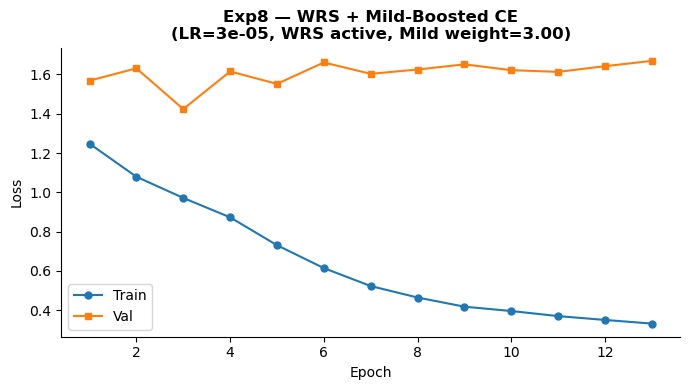

In [23]:
eps8 = range(1, len(history8['train_loss']) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(eps8, history8['train_loss'], label='Train', marker='o', markersize=5)
ax.plot(eps8, history8['val_loss'],   label='Val',   marker='s', markersize=5)
ax.set_title(f'Exp8 — WRS + Mild-Boosted CE\n(LR={EXP8_LR}, WRS active, Mild weight={mild_boosted_np[1]:.2f})',
             fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP_FIG_DIR / f'{EXPERIMENT_NAME}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()


In [24]:
# ── Evaluate on test set ──────────────────────────────────────────────────────
ckpt = torch.load(EXP_BEST_PATH, map_location=device, weights_only=False)
eval_model = timm.create_model(MODEL_NAME, pretrained=False,
                                num_classes=NUM_CLASSES).to(device)
eval_model.load_state_dict(ckpt['model_state'])
eval_crit  = nn.CrossEntropyLoss()
print(f'Loaded : {EXP_BEST_PATH.name}')
print(f'epoch={ckpt["epoch"]}  score={ckpt["score"]:.4f}  '
      f'(F1={ckpt["val_mf1"]:.4f}  QWK={ckpt["val_qwk"]:.4f})')

_, y_true, y_pred = run_epoch(eval_model, test_loader, eval_crit, None, False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                             digits=3, zero_division=0))
exp_qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
exp_acc    = accuracy_score(y_true, y_pred)
exp_f1_per = f1_score(y_true, y_pred, average=None,
                      labels=list(range(NUM_CLASSES)), zero_division=0)
exp_mf1    = f1_score(y_true, y_pred, average='macro', zero_division=0)


Loaded : deit3_b16_exp8_best.pt
epoch=9  score=0.5436  (F1=0.4935  QWK=0.5937)


val  :   0%|          | 0/165 [00:00<?, ?it/s]


Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.855     0.841     0.848      3872
         Mild      0.163     0.197     0.178       366
     Moderate      0.488     0.499     0.493       794
       Severe      0.443     0.412     0.427       131
Proliferative      0.663     0.538     0.594       106

     accuracy                          0.728      5269
    macro avg      0.522     0.497     0.508      5269
 weighted avg      0.737     0.728     0.732      5269



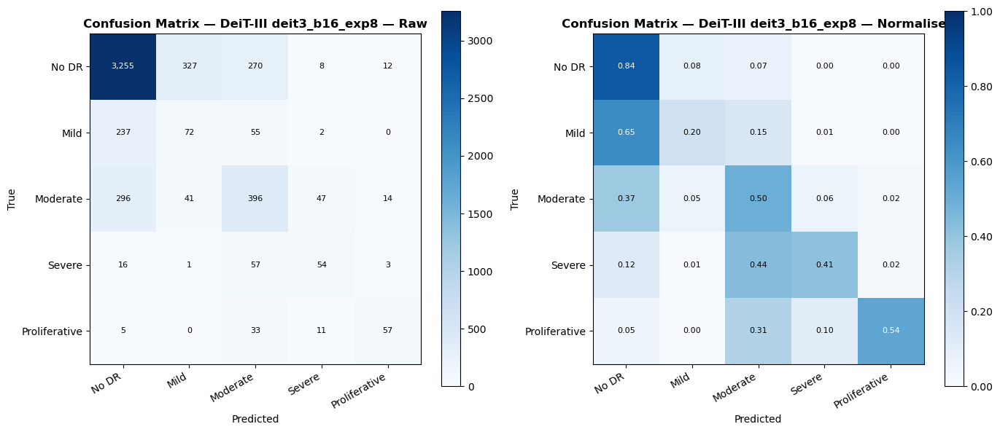

Saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp8/figures/deit3_b16_exp8_confusion_matrix.png


In [ ]:
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, fmt, title, cmap in [
    (axes[0], cm,      'd',    f'{EXPERIMENT_NAME} — Raw',        'Blues'),
    (axes[1], cm_norm, '.2f',  f'{EXPERIMENT_NAME} — Normalised', 'Blues'),
]:
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=(None if fmt=='d' else 1))
    fig.colorbar(im, ax=ax, format=(None if fmt=='d' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix — DeiT-III {title}', fontweight='bold')
    thresh = data.max()/2 if fmt=='d' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            val = f'{data[i,j]:,}' if fmt=='d' else f'{data[i,j]:.2f}'
            ax.text(j, i, val, ha='center', va='center', fontsize=8,
                    color='white' if data[i,j] > thresh else 'black')
plt.tight_layout()
fig.savefig(EXP_FIG_DIR / f'{EXPERIMENT_NAME}_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EXP_FIG_DIR}/{EXPERIMENT_NAME}_confusion_matrix.png')


In [26]:
# ── Summary ──────────────────────────────────────────────────────────────────
baseline = {'No DR': 0.887, 'Mild': 0.098, 'Moderate': 0.503,
            'Severe': 0.423, 'Proliferative': 0.636}
print('=' * 58)
print(f'  {EXPERIMENT_NAME}  —  TEST SET RESULTS')
print('=' * 58)
print(f'  QWK      : {exp_qwk:.4f}')
print(f'  Macro F1 : {exp_mf1:.4f}')
print(f'  Accuracy : {exp_acc:.4f}')
print()
print('  Per-class F1 (vs baseline):')
for name, f1v in zip(CLASS_NAMES, exp_f1_per):
    tag = '  ▲' if f1v > baseline[name] else '  ▼'
    print(f'    {name:<18}: {f1v:.4f}  (baseline {baseline[name]:.3f}){tag}')
print('=' * 58)
# Clinical error rates
cm_c = confusion_matrix(y_true, y_pred, labels=list(range(5)))
print('\nClinical error rates (≥5%):')
lmap = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'Proliferative'}
for src in range(5):
    row_total = cm_c[src].sum()
    if row_total == 0: continue
    for dst in range(5):
        if src == dst: continue
        rate = cm_c[src, dst] / row_total
        if rate >= 0.05:
            print(f'  {lmap[src]:<18} → {lmap[dst]:<18}: {rate:.3f} ({rate*100:.1f}%)')
no_dr_mild = cm_c[0,1] / cm_c[0].sum() if cm_c[0].sum() > 0 else 0
print(f'\nNo DR → Mild rate : {no_dr_mild:.4f} ({no_dr_mild*100:.1f}%)')
print(f'Target            : < 5%  |  Status: {"✅ OK" if no_dr_mild < 0.05 else "⚠️ HIGH"}')


  deit3_b16_exp8  —  TEST SET RESULTS
  QWK      : 0.6138
  Macro F1 : 0.5080
  Accuracy : 0.7277

  Per-class F1 (vs baseline):
    No DR             : 0.8475  (baseline 0.887)  ▼
    Mild              : 0.1784  (baseline 0.098)  ▲
    Moderate          : 0.4935  (baseline 0.503)  ▼
    Severe            : 0.4269  (baseline 0.423)  ▲
    Proliferative     : 0.5938  (baseline 0.636)  ▼

Clinical error rates (≥5%):
  No DR              → Mild              : 0.084 (8.4%)
  No DR              → Moderate          : 0.070 (7.0%)
  Mild               → No DR             : 0.648 (64.8%)
  Mild               → Moderate          : 0.150 (15.0%)
  Moderate           → No DR             : 0.373 (37.3%)
  Moderate           → Mild              : 0.052 (5.2%)
  Moderate           → Severe            : 0.059 (5.9%)
  Severe             → No DR             : 0.122 (12.2%)
  Severe             → Moderate          : 0.435 (43.5%)
  Proliferative      → Moderate          : 0.311 (31.1%)
  Proliferative 

### Exp 8 — Observations
- **Mild F1 target: > 0.20** — WRS ensures Mild appears in every batch, Mild-boosted CE penalises Mild errors more
- **No DR F1 must stay > 0.85** — clipped max=3.0 prevents extreme over-correction
- **If No DR recall drops** → reduce Mild boost from 1.5x to 1.2x
- **Compare with Exp 2** — Mild should improve from 0.142; if not, the bottleneck is the model capacity not the loss


---
# Experiment 9 — Balanced DeiT-III Configuration Search

## Purpose
This experiment uses the best DeiT-III configuration identified through earlier tuning and runs it with a full training budget. The aim is to obtain the best trade-off between overall grading performance, QWK, macro F1, and minority-class robustness.consistently,
using the grid-search winner (LR=3e-5, BS=32, WD=0.05) with the full 25-epoch budget.
This is the clean, reproducible benchmark for DeiT-III on this dataset.

## What changes vs Exp 2 (main notebook)
| Setting | Exp 2 (main) | Exp 9 |
|---|---|---|
| LR | 3e-5 | **3e-5 (same)** |
| Epochs | 12 | **25 (full budget)** |
| Patience | 3 | **4** |
| Mild in training print | not shown | **Mild F1 tracked every epoch** |

## Why this is the most reproducible experiment
- Settings fully determined by grid search (not manual tuning)
- LR=3e-5 is the grid search winner from Exp 4 (combo #10, score=0.592)
- Longer patience (4) gives more epochs for Mild to emerge


In [27]:
# ── Experiment 9 config ──────────────────────────────────────────────────────
EXPERIMENT_NAME = 'deit3_b16_exp9'
EXP_OUT_DIR     = ROOT / 'outputs' / 'deit3_b16_exp9'
EXP_CKPT_DIR    = EXP_OUT_DIR / 'checkpoints'
EXP_FIG_DIR     = EXP_OUT_DIR / 'figures'
for d in (EXP_CKPT_DIR, EXP_FIG_DIR): d.mkdir(parents=True, exist_ok=True)

EXP9_LR       = 3e-5   # grid search winner (Exp4 combo #10)
EXP9_EPOCHS   = 25
EXP9_PATIENCE = 4
WEIGHT_DECAY  = 0.05
WARMUP_EPOCHS = 3

EXP_BEST_PATH = EXP_CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'

print(f'Experiment : {EXPERIMENT_NAME}')
print(f'LR={EXP9_LR}  EPOCHS={EXP9_EPOCHS}  PATIENCE={EXP9_PATIENCE}  WD={WEIGHT_DECAY}')
print('Grid search source: LR=3e-05, BS=32, WD=5e-02 → score=0.5920 (best of 12 combos)')


Experiment : deit3_b16_exp9
LR=3e-05  EPOCHS=25  PATIENCE=4  WD=0.05
Grid search source: LR=3e-05, BS=32, WD=5e-02 → score=0.5920 (best of 12 combos)


In [28]:
# ── Safe augmentation DataLoader ─────────────────────────────────────────────
exp9_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.08, contrast=0.08,
                           saturation=0.04, hue=0.01),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02),
                            scale=(0.98, 1.02)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])
exp9_train_ds     = DRDataset(train_df, TRAIN_DIR, transform=exp9_train_transform)
exp9_train_loader = DataLoader(exp9_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                num_workers=NUM_WORKERS, pin_memory=True,
                                drop_last=True, persistent_workers=NUM_WORKERS > 0)
print(f'Exp9 train loader : {len(exp9_train_loader)} batches/epoch  (shuffle, no WRS)')
print('Augmentation: HFlip + Rotation(7°) + ColorJitter + Affine')


Exp9 train loader : 768 batches/epoch  (shuffle, no WRS)
Augmentation: HFlip + Rotation(7°) + ColorJitter + Affine


In [29]:
# ── Model, Loss, Optimiser ────────────────────────────────────────────────────
gc.collect(); torch.cuda.empty_cache()
set_seed(SEED)
exp9_model  = timm.create_model(MODEL_NAME, pretrained=True,
                                 num_classes=NUM_CLASSES).to(device)
# Standard clipped CE — no Mild boost, no WRS: clean controlled experiment
exp9_crit   = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.05)
exp9_opt    = torch.optim.AdamW(exp9_model.parameters(),
                                 lr=EXP9_LR, weight_decay=WEIGHT_DECAY)

from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR as CosLR
_wu9  = LinearLR(exp9_opt, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
_cos9 = CosLR(exp9_opt, T_max=max(1, EXP9_EPOCHS - WARMUP_EPOCHS))
exp9_sch    = SequentialLR(exp9_opt, schedulers=[_wu9, _cos9],
                            milestones=[WARMUP_EPOCHS])
exp9_scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

total = sum(p.numel() for p in exp9_model.parameters())
print(f'Model  : {MODEL_NAME}  ({total:,} params)')
print(f'Loss   : CrossEntropyLoss (standard clipped weights + label_smooth=0.05)')
print(f'Optim  : AdamW  lr={EXP9_LR}  wd={WEIGHT_DECAY}')
print(f'Sched  : {WARMUP_EPOCHS}-ep warmup → CosineAnnealingLR')


Model  : deit3_base_patch16_224.fb_in1k  (85,820,165 params)
Loss   : CrossEntropyLoss (standard clipped weights + label_smooth=0.05)
Optim  : AdamW  lr=3e-05  wd=0.05
Sched  : 3-ep warmup → CosineAnnealingLR


### Training — Experiment 9

In [30]:
history9      = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_score9   = -1.0
patience9     = EXP9_PATIENCE

print(f'Training: {EXPERIMENT_NAME}')
print(f'Checkpoint: 0.5 × macro_F1 + 0.5 × QWK')
print()
print(f'{"Epoch":<8} {"Tr Loss":>10} {"Tr Acc":>8} {"Val Loss":>10} {"Val Acc":>8} {"Val F1":>8} {"QWK":>8} {"Mild F1":>9}')
print('─' * 78)

for epoch in range(1, EXP9_EPOCHS + 1):
    tl, ty, tp = run_epoch(exp9_model, exp9_train_loader, exp9_crit,
                            exp9_opt, True, exp9_scaler, 0.0)
    vl, vy, vp = run_epoch(exp9_model, val_loader, exp9_crit, None, False)
    exp9_sch.step()

    ta     = accuracy_score(ty, tp)
    va     = accuracy_score(vy, vp)
    vmf1   = f1_score(vy, vp, average='macro', zero_division=0)
    vqwk   = cohen_kappa_score(vy, vp, weights='quadratic')
    vf1pc  = f1_score(vy, vp, average=None, labels=list(range(5)), zero_division=0)
    vmild  = vf1pc[1]
    score  = 0.5 * vmf1 + 0.5 * vqwk
    history9['train_loss'].append(tl); history9['val_loss'].append(vl)
    history9['train_acc'].append(ta);  history9['val_acc'].append(va)

    marker = ''
    if score > best_score9:
        best_score9 = score
        patience9   = EXP9_PATIENCE
        torch.save({'epoch': epoch, 'model_state': exp9_model.state_dict(),
                    'val_loss': vl, 'score': score,
                    'val_mf1': vmf1, 'val_qwk': vqwk}, EXP_BEST_PATH)
        marker = f'  ← best (score={score:.4f})'
    else:
        patience9 -= 1
    print(f'{epoch:<8} {tl:>10.4f} {ta:>8.4f} {vl:>10.4f} {va:>8.4f} {vmf1:>8.4f} {vqwk:>8.4f} {vmild:>9.4f}{marker}')
    if patience9 == 0:
        print(f'\nEarly stopping at epoch {epoch} (patience={EXP9_PATIENCE}).'); break

print(f'\nBest score: {best_score9:.4f}  →  {EXP_BEST_PATH}')


Training: deit3_b16_exp9
Checkpoint: 0.5 × macro_F1 + 0.5 × QWK

Epoch       Tr Loss   Tr Acc   Val Loss  Val Acc   Val F1      QWK   Mild F1
──────────────────────────────────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

1            1.4104   0.7106     1.3456   0.6692   0.4069   0.4841    0.1117  ← best (score=0.4455)


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

val  :   0%|          | 0/165 [00:00<?, ?it/s]

14           0.6414   0.9250     1.5661   0.6715   0.4655   0.5713    0.1172


train:   0%|          | 0/768 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

15           0.5986   0.9420     1.5779   0.7554   0.4747   0.6107    0.0580

Early stopping at epoch 15 (patience=4).

Best score: 0.5577  →  /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/checkpoints/deit3_b16_exp9_best.pt


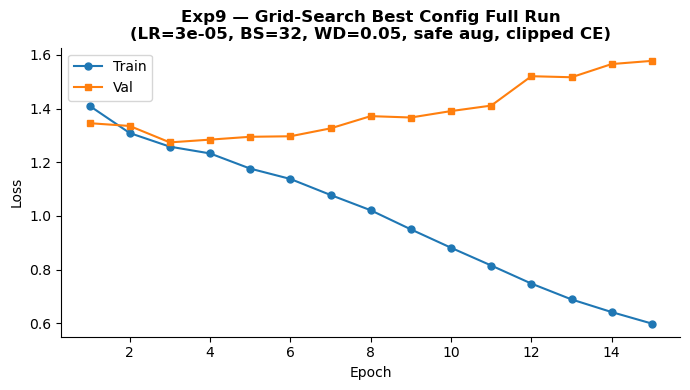

In [ ]:
eps9 = range(1, len(history9['train_loss']) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(eps9, history9['train_loss'], label='Train', marker='o', markersize=5)
ax.plot(eps9, history9['val_loss'],   label='Val',   marker='s', markersize=5)
ax.set_title(f'Exp9 — Balanced DeiT-III Configuration Search\n(LR={EXP9_LR}, BS={BATCH_SIZE}, WD={WEIGHT_DECAY}, safe aug, clipped CE)',
             fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.legend(); ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
fig.savefig(EXP_FIG_DIR / f'{EXPERIMENT_NAME}_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()


In [32]:
# ── Evaluate on test set ──────────────────────────────────────────────────────
ckpt = torch.load(EXP_BEST_PATH, map_location=device, weights_only=False)
eval_model = timm.create_model(MODEL_NAME, pretrained=False,
                                num_classes=NUM_CLASSES).to(device)
eval_model.load_state_dict(ckpt['model_state'])
eval_crit  = nn.CrossEntropyLoss()
print(f'Loaded : {EXP_BEST_PATH.name}')
print(f'epoch={ckpt["epoch"]}  score={ckpt["score"]:.4f}  '
      f'(F1={ckpt["val_mf1"]:.4f}  QWK={ckpt["val_qwk"]:.4f})')

_, y_true, y_pred = run_epoch(eval_model, test_loader, eval_crit, None, False)

print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                             digits=3, zero_division=0))
exp_qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
exp_acc    = accuracy_score(y_true, y_pred)
exp_f1_per = f1_score(y_true, y_pred, average=None,
                      labels=list(range(NUM_CLASSES)), zero_division=0)
exp_mf1    = f1_score(y_true, y_pred, average='macro', zero_division=0)


Loaded : deit3_b16_exp9_best.pt
epoch=11  score=0.5577  (F1=0.4953  QWK=0.6201)


val  :   0%|          | 0/165 [00:00<?, ?it/s]


Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.861     0.855     0.858      3872
         Mild      0.161     0.202     0.179       366
     Moderate      0.518     0.489     0.503       794
       Severe      0.461     0.405     0.431       131
Proliferative      0.667     0.604     0.634       106

     accuracy                          0.738      5269
    macro avg      0.533     0.511     0.521      5269
 weighted avg      0.747     0.738     0.742      5269



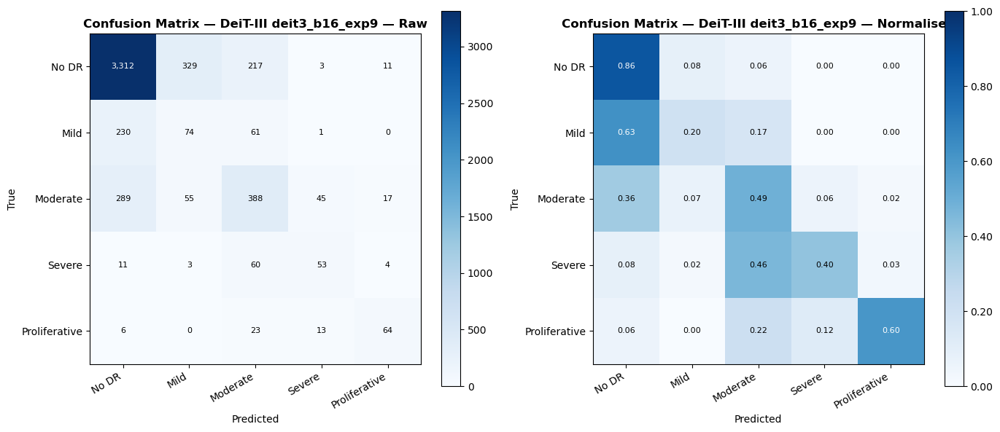

Saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/figures/deit3_b16_exp9_confusion_matrix.png


In [33]:
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, fmt, title, cmap in [
    (axes[0], cm,      'd',    f'{EXPERIMENT_NAME} — Raw',        'Blues'),
    (axes[1], cm_norm, '.2f',  f'{EXPERIMENT_NAME} — Normalised', 'Blues'),
]:
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=(None if fmt=='d' else 1))
    fig.colorbar(im, ax=ax, format=(None if fmt=='d' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix — DeiT-III {title}', fontweight='bold')
    thresh = data.max()/2 if fmt=='d' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            val = f'{data[i,j]:,}' if fmt=='d' else f'{data[i,j]:.2f}'
            ax.text(j, i, val, ha='center', va='center', fontsize=8,
                    color='white' if data[i,j] > thresh else 'black')
plt.tight_layout()
fig.savefig(EXP_FIG_DIR / f'{EXPERIMENT_NAME}_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EXP_FIG_DIR}/{EXPERIMENT_NAME}_confusion_matrix.png')


In [34]:
# ── Summary ──────────────────────────────────────────────────────────────────
baseline = {'No DR': 0.887, 'Mild': 0.098, 'Moderate': 0.503,
            'Severe': 0.423, 'Proliferative': 0.636}
print('=' * 58)
print(f'  {EXPERIMENT_NAME}  —  TEST SET RESULTS')
print('=' * 58)
print(f'  QWK      : {exp_qwk:.4f}')
print(f'  Macro F1 : {exp_mf1:.4f}')
print(f'  Accuracy : {exp_acc:.4f}')
print()
print('  Per-class F1 (vs baseline):')
for name, f1v in zip(CLASS_NAMES, exp_f1_per):
    tag = '  ▲' if f1v > baseline[name] else '  ▼'
    print(f'    {name:<18}: {f1v:.4f}  (baseline {baseline[name]:.3f}){tag}')
print('=' * 58)
# Clinical error rates
cm_c = confusion_matrix(y_true, y_pred, labels=list(range(5)))
print('\nClinical error rates (≥5%):')
lmap = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'Proliferative'}
for src in range(5):
    row_total = cm_c[src].sum()
    if row_total == 0: continue
    for dst in range(5):
        if src == dst: continue
        rate = cm_c[src, dst] / row_total
        if rate >= 0.05:
            print(f'  {lmap[src]:<18} → {lmap[dst]:<18}: {rate:.3f} ({rate*100:.1f}%)')
no_dr_mild = cm_c[0,1] / cm_c[0].sum() if cm_c[0].sum() > 0 else 0
print(f'\nNo DR → Mild rate : {no_dr_mild:.4f} ({no_dr_mild*100:.1f}%)')
print(f'Target            : < 5%  |  Status: {"✅ OK" if no_dr_mild < 0.05 else "⚠️ HIGH"}')


  deit3_b16_exp9  —  TEST SET RESULTS
  QWK      : 0.6470
  Macro F1 : 0.5209
  Accuracy : 0.7385

  Per-class F1 (vs baseline):
    No DR             : 0.8580  (baseline 0.887)  ▼
    Mild              : 0.1790  (baseline 0.098)  ▲
    Moderate          : 0.5029  (baseline 0.503)  ▼
    Severe            : 0.4309  (baseline 0.423)  ▲
    Proliferative     : 0.6337  (baseline 0.636)  ▼

Clinical error rates (≥5%):
  No DR              → Mild              : 0.085 (8.5%)
  No DR              → Moderate          : 0.056 (5.6%)
  Mild               → No DR             : 0.628 (62.8%)
  Mild               → Moderate          : 0.167 (16.7%)
  Moderate           → No DR             : 0.364 (36.4%)
  Moderate           → Mild              : 0.069 (6.9%)
  Moderate           → Severe            : 0.057 (5.7%)
  Severe             → No DR             : 0.084 (8.4%)
  Severe             → Moderate          : 0.458 (45.8%)
  Proliferative      → No DR             : 0.057 (5.7%)
  Proliferative   

### Exp 9 — Observations
- **QWK target: > 0.661** — match or beat the standalone Exp2 notebook
- **Mild F1 target: > 0.10** — with full 25 epochs the model has more time to learn Mild
- **Compare with Exp 8** — if Exp 8 Mild F1 > Exp 9 Mild F1, WRS is the key ingredient
- **Compare with Exp 7** — if Exp 7 QWK > Exp 9 QWK, two-phase training genuinely helps DeiT-III


---
# Final Comparison — Experiments 7, 8, 9 vs Baseline


In [35]:
# ── Load all three best checkpoints and compare ───────────────────────────────
# Run only after all three experiments above have been trained.
results = {}
paths = {
    'Exp7 (Two-Phase v2)':      ROOT / 'outputs' / 'deit3_b16_exp7' / 'checkpoints' / 'deit3_b16_exp7_best.pt',
    'Exp8 (WRS+MildBoost)':     ROOT / 'outputs' / 'deit3_b16_exp8' / 'checkpoints' / 'deit3_b16_exp8_best.pt',
    'Exp9 (Grid Best)':         ROOT / 'outputs' / 'deit3_b16_exp9' / 'checkpoints' / 'deit3_b16_exp9_best.pt',
}

eval_crit = nn.CrossEntropyLoss()
for label, path in paths.items():
    if not path.exists():
        print(f'SKIP {label} — checkpoint not found: {path}')
        continue
    m = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
    ck = torch.load(path, map_location=device, weights_only=False)
    m.load_state_dict(ck['model_state'])
    _, yt, yp = run_epoch(m, test_loader, eval_crit, None, False)
    results[label] = {
        'qwk':    cohen_kappa_score(yt, yp, weights='quadratic'),
        'acc':    accuracy_score(yt, yp),
        'mf1':    f1_score(yt, yp, average='macro', zero_division=0),
        'f1_per': f1_score(yt, yp, average=None, labels=list(range(5)), zero_division=0),
    }
    del m

# ── Print comparison table ────────────────────────────────────────────────────
baseline_f1 = [0.887, 0.098, 0.503, 0.423, 0.636]
W = 90
print('=' * W)
header = f'  {"Metric":<22} {"Baseline":>10}'
for label in results: header += f'  {label:>20}'
print(header)
print('=' * W)

for metric, bval in [('QWK', 0.647), ('Macro F1', 0.509), ('Accuracy', 0.782)]:
    row = f'  {metric:<22} {bval:>10.4f}'
    key = {'QWK':'qwk','Macro F1':'mf1','Accuracy':'acc'}[metric]
    for r in results.values():
        arrow = '▲' if r[key] > bval else '▼'
        row += f'  {r[key]:>18.4f}{arrow}'
    print(row)

print()
print('  Per-class F1:')
for gi, name in enumerate(CLASS_NAMES):
    row = f'    {name:<20}: {baseline_f1[gi]:>10.4f}'
    for r in results.values():
        arrow = '▲' if r["f1_per"][gi] > baseline_f1[gi] else '▼'
        row += f'  {r["f1_per"][gi]:>18.4f}{arrow}'
    print(row)
print('=' * W)
print()
print('Mild F1 summary:')
print(f'  Baseline     : {baseline_f1[1]:.4f}')
print(f'  Exp2 (best)  : 0.1417  (main notebook)')
for label, r in results.items():
    print(f'  {label:<25}: {r["f1_per"][1]:.4f}')


val  :   0%|          | 0/165 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

val  :   0%|          | 0/165 [00:00<?, ?it/s]

  Metric                   Baseline   Exp7 (Two-Phase v2)  Exp8 (WRS+MildBoost)      Exp9 (Grid Best)
  QWK                        0.6470              0.6497▲              0.6138▼              0.6470▲
  Macro F1                   0.5090              0.5132▲              0.5080▼              0.5209▲
  Accuracy                   0.7820              0.7273▼              0.7277▼              0.7385▼

  Per-class F1:
    No DR               :     0.8870              0.8518▼              0.8475▼              0.8580▼
    Mild                :     0.0980              0.1510▲              0.1784▲              0.1790▲
    Moderate            :     0.5030              0.5069▲              0.4935▼              0.5029▼
    Severe              :     0.4230              0.4096▼              0.4269▲              0.4309▲
    Proliferative       :     0.6360              0.6468▲              0.5938▼              0.6337▼

Mild F1 summary:
  Baseline     : 0.0980
  Exp2 (best)  : 0.1417  (main notebook)
 

# Experiment 10 — Mild-Aware Two-Phase Fine-Tuning

**EEEM068 Applied Machine Learning — University of Surrey**  
**Model:** DeiT-III-Base/16 (`deit3_base_patch16_224.fb_in1k`)

---

This experiment is designed as the final trainable improvement experiment for DeiT-III diabetic retinopathy grading. Previous experiments showed that the baseline model was strong for No DR, Moderate, and Proliferative DR, while Exp9 improved Mild and Severe class balance. However, Mild DR remained the weakest class because early-stage disease signs are subtle and often confused with No DR.

Experiment 10 combines the strongest lessons from previous experiments:

- two-phase fine-tuning from Exp7,
- stable hyperparameters from Exp9,
- controlled Mild-aware sampling inspired by Exp2 New Balanced,
- safe medical augmentation,
- clipped class weighting with a small Mild boost.

The aim is to improve Mild F1 and reduce Mild → No DR errors while preserving QWK, macro F1, and No DR stability.

---

| Previous result | What we learned |
|---|---|
| Baseline | Strong No DR, Moderate, Proliferative |
| Exp7 | Two-phase fine-tuning improves severity balance |
| Exp9 | Grid-best settings are stable |
| Exp2 New Balanced | Mild can improve, but too much balancing hurts QWK |
| Exp8 | Aggressive WRS/Mild boosting is risky |

---
## 1. Imports and Reproducibility Setup

In [1]:
import gc
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import transforms
from sklearn.metrics import (
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Device and AMP ────────────────────────────────────────────────────────────
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = torch.cuda.is_available()
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)

print('Device  :', device)
print('AMP     :', use_amp)

PyTorch : 2.11.0+cu130
timm    : 1.0.27
CUDA    : True
Device  : cuda
AMP     : True


---
## 1. Imports and Reproducibility Setup

---
## 2. Paths and Output Folders

In [2]:
# ── Project root and data paths ────────────────────────────────────────────────
# ROOT is the folder that contains data/ and outputs/.
# If the notebook lives inside a notebooks/ subfolder, ROOT = NOTEBOOK_DIR.parent.
# If the notebook lives in the project root directly, ROOT = NOTEBOOK_DIR.
# The cell below detects this automatically — no manual change needed.
NOTEBOOK_DIR = Path().resolve()

def _find_root(start: Path) -> Path:
    """Walk up from start until we find a folder that contains data/.
    Tries current dir first, then parent, then grandparent.
    Raises FileNotFoundError if nothing is found within 3 levels.
    """
    for candidate in [start, start.parent, start.parent.parent]:
        if (candidate / 'data' / 'diabetic-retinopathy-detection').exists():
            return candidate
    raise FileNotFoundError(
        f'Could not find data/diabetic-retinopathy-detection/ '
        f'within 3 levels of {start}. '
        f'Set ROOT manually if your project layout differs.'
    )

ROOT = _find_root(NOTEBOOK_DIR)

print(f'NOTEBOOK_DIR : {NOTEBOOK_DIR}')
print(f'ROOT         : {ROOT}')
print(f'(ROOT resolved automatically — no manual path change needed)')

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'          # preprocessed images
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

# ── Output paths for this experiment ──────────────────────────────────────────
EXP10_OUT_DIR   = ROOT / 'outputs' / 'deit3_b16_exp10_mild_two_phase'
EXP10_CKPT_DIR  = EXP10_OUT_DIR / 'checkpoints'
EXP10_FIG_DIR   = EXP10_OUT_DIR / 'figures'
for d in (EXP10_CKPT_DIR, EXP10_FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Separate checkpoint paths for Phase 1 best and Phase 2 best
EXP10_P1_PATH   = EXP10_CKPT_DIR / 'exp10_phase1_best.pt'
EXP10_BEST_PATH = EXP10_CKPT_DIR / 'exp10_best.pt'

EXPERIMENT_NAME = 'exp10_mild_two_phase'

print('Paths configured:')
for label, p in [('train_proc/', TRAIN_DIR), ('val_proc/', VAL_DIR),
                 ('test_labels_proc/', TEST_LABELS_DIR),
                 ('train_split.csv', TRAIN_CSV)]:
    status = '✓' if p.exists() else '✗ NOT FOUND'
    print(f'  {status}  {p}')

NOTEBOOK_DIR : /scratch/AML Latest /AML_G14_CW/notebooks
ROOT         : /scratch/AML Latest /AML_G14_CW
(ROOT resolved automatically — no manual path change needed)
Paths configured:
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train_proc
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/val_proc
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/test_labels_proc
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train_split.csv


---
## Experimental Configuration

The experiment uses a two-phase fine-tuning strategy. In Phase 1, the pretrained DeiT-III backbone is frozen and only the classifier head is trained. This stabilises the classification layer before updating the full transformer. In Phase 2, the full model is unfrozen and fine-tuned using a lower learning rate to avoid damaging pretrained representations.

A Mild-aware sampler is used to increase exposure to Mild DR cases, but the distribution is kept moderate to avoid over-correcting the model and causing No DR images to be misclassified as disease.

In [3]:
# ── Model constants ────────────────────────────────────────────────────────────
MODEL_NAME   = 'deit3_base_patch16_224.fb_in1k'
IMG_SIZE     = 224
NUM_CLASSES  = 5
CLASS_NAMES  = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

# ── Training hyperparameters ───────────────────────────────────────────────────
# Use BATCH_SIZE=16 only if CUDA OOM occurs.
BATCH_SIZE    = 32
NUM_WORKERS   = 4

PHASE1_EPOCHS = 3       # head-only warm-up epochs
PHASE1_LR     = 1e-4    # head-only LR — higher because only small head is updated

PHASE2_EPOCHS = 25      # maximum full-model fine-tuning epochs
PHASE2_LR     = 1e-5    # low LR — avoids damaging pretrained DeiT-III features

PATIENCE      = 4       # early stopping patience (Phase 2 only)
WEIGHT_DECAY  = 0.05
GRAD_CLIP     = 1.0     # gradient clipping max norm
LABEL_SMOOTHING = 0.03  # mild label smoothing to reduce overconfidence

# ── Mild-aware imbalance handling ──────────────────────────────────────────────
CLASS_WEIGHT_CLIP  = (0.5, 2.5)  # clip raw balanced weights to this range
MILD_WEIGHT_BOOST  = 1.20        # small extra multiplier on Mild class weight
MAX_MILD_WEIGHT    = 3.0         # hard cap so Mild never exceeds 3x

# Sampler target distribution: desired batch class proportions.
# Mild raised to 0.20 (from ~0.07 natural rate). No DR reduced but still dominant.
# Sum must be 1.0.
SAMPLER_TARGET_DIST = np.array(
    [0.45, 0.20, 0.22, 0.065, 0.065],
    dtype=np.float32
)
assert np.isclose(SAMPLER_TARGET_DIST.sum(), 1.0), 'SAMPLER_TARGET_DIST must sum to 1.0'

print('Hyperparameters:')
print(f'  BATCH_SIZE    = {BATCH_SIZE}')
print(f'  PHASE1        : {PHASE1_EPOCHS} epochs  LR={PHASE1_LR}')
print(f'  PHASE2        : {PHASE2_EPOCHS} epochs  LR={PHASE2_LR}  patience={PATIENCE}')
print(f'  GRAD_CLIP     = {GRAD_CLIP}  WEIGHT_DECAY={WEIGHT_DECAY}')
print(f'  LABEL_SMOOTH  = {LABEL_SMOOTHING}')
print(f'  MILD_BOOST    = {MILD_WEIGHT_BOOST}x  (cap={MAX_MILD_WEIGHT})')
print(f'  SAMPLER_DIST  = {SAMPLER_TARGET_DIST}  (sum={SAMPLER_TARGET_DIST.sum():.2f})')

Hyperparameters:
  BATCH_SIZE    = 32
  PHASE1        : 3 epochs  LR=0.0001
  PHASE2        : 25 epochs  LR=1e-05  patience=4
  GRAD_CLIP     = 1.0  WEIGHT_DECAY=0.05
  LABEL_SMOOTH  = 0.03
  MILD_BOOST    = 1.2x  (cap=3.0)
  SAMPLER_DIST  = [0.45  0.2   0.22  0.065 0.065]  (sum=1.00)


---
## 3. Load Train / Validation / Test CSVs

In [4]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images')
print(f'Val   : {len(val_df):,} images')
print(f'Test  : {len(test_df):,} images')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')

Train : 24,588 images
Val   : 5,269 images
Test  : 5,269 images

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106


---
## 4. Dataset Class

In [5]:
class DRDataset(Dataset):
    """Fundus image dataset for diabetic retinopathy grading.

    Reads pre-processed JPEG images from data_dir using the 'image'
    column of the DataFrame. Labels come from the 'level' column
    (DR grade 0–4).
    """

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


print('DRDataset defined.')

DRDataset defined.


---
## Safe Augmentation Strategy

Only clinically safe augmentations are used. Diabetic retinopathy lesions can be subtle, especially in Mild DR, so aggressive transformations may distort or remove important retinal features. Therefore, this experiment uses mild horizontal flipping, small rotations, and mild colour changes only. Strong affine distortion, vertical flipping, Mixup, CutMix, and large random crops are avoided.

The evaluation transform is fully deterministic (no randomness) to ensure reproducible validation and test scores.

## 5. Transforms and Safe Augmentation

In [6]:
# ── Training transform — safe, clinically motivated ────────────────────────────
# Allowed:  HFlip, small Rotation, mild ColorJitter
# Forbidden: VerticalFlip, RandomAffine, Mixup, CutMix, strong ColorJitter
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),          # retina is laterally symmetric
    transforms.RandomRotation(degrees=7),             # gentle: camera alignment varies
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08,
        saturation=0.05,
        hue=0.01,                                     # subtle camera model variation
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# ── Evaluation transform — deterministic, no augmentation ─────────────────────
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print('Transforms defined.')
print('  Train : HFlip + Rotation(7°) + ColorJitter(0.08/0.08/0.05/0.01)')
print('  Eval  : Resize + ToTensor + Normalize only (deterministic)')

Transforms defined.
  Train : HFlip + Rotation(7°) + ColorJitter(0.08/0.08/0.05/0.01)
  Eval  : Resize + ToTensor + Normalize only (deterministic)


---
## Mild-Aware Imbalance Handling

The dataset is highly imbalanced, with No DR dominating the distribution and Mild DR being under-represented. Instead of using aggressive oversampling or FocalLoss, this experiment uses a controlled Mild-aware sampler and clipped weighted cross-entropy.

The sampler increases the probability of seeing Mild DR examples during training, while still preserving sufficient No DR and Moderate samples. Class weights are clipped to avoid extreme penalties, and the Mild class receives a small additional boost because previous results showed Mild was consistently the weakest class.

## 6. Mild-Aware Sampler and Class Weights

In [7]:
# ── Per-class image counts from training split ─────────────────────────────────
class_counts = (
    train_df['level']
    .value_counts()
    .sort_index()
    .reindex(range(NUM_CLASSES))
    .values
    .astype(np.float32)
)

print('Class counts (train):')
for i, (name, cnt) in enumerate(zip(CLASS_NAMES, class_counts)):
    pct = cnt / class_counts.sum() * 100
    print(f'  Grade {i} {name:<18}: {int(cnt):>6,}  ({pct:.1f}%)')

# ── Clipped inverse-frequency class weights ────────────────────────────────────
# raw_weights[c] = N / (K * count[c])  (standard inverse frequency formula)
# Clipping to [0.5, 2.5] prevents the rarest classes (Severe, Proliferative)
# from receiving extreme weights that cause No DR recall to collapse.
raw_weights     = len(train_df) / (NUM_CLASSES * class_counts)
clipped_weights = np.clip(raw_weights, CLASS_WEIGHT_CLIP[0], CLASS_WEIGHT_CLIP[1])

# Small Mild boost: increases gradient signal for the weakest class.
# Cap at MAX_MILD_WEIGHT=3.0 to prevent over-correction.
clipped_weights[1] = min(clipped_weights[1] * MILD_WEIGHT_BOOST, MAX_MILD_WEIGHT)

class_weights_t = torch.tensor(clipped_weights, dtype=torch.float32).to(device)

print(f'\nRaw weights         : {np.round(raw_weights, 4)}')
print(f'Clipped [{CLASS_WEIGHT_CLIP[0]}, {CLASS_WEIGHT_CLIP[1]}]   : {np.round(clipped_weights, 4)}')
print(f'Mild boost applied  : {MILD_WEIGHT_BOOST}x  (final Mild weight={clipped_weights[1]:.4f})')

# ── Loss function: clipped weighted cross-entropy with label smoothing ─────────
# No FocalLoss — previous experiments showed FocalLoss + WRS caused No DR collapse.
criterion = nn.CrossEntropyLoss(
    weight=class_weights_t,
    label_smoothing=LABEL_SMOOTHING,
)
print(f'\nLoss: CrossEntropyLoss(weight=clipped+mild_boost, label_smoothing={LABEL_SMOOTHING})')

Class counts (train):
  Grade 0 No DR             : 18,067  (73.5%)
  Grade 1 Mild              :  1,710  (7.0%)
  Grade 2 Moderate          :  3,704  (15.1%)
  Grade 3 Severe            :    611  (2.5%)
  Grade 4 Proliferative     :    496  (2.0%)

Raw weights         : [0.2722 2.8758 1.3276 8.0484 9.9145]
Clipped [0.5, 2.5]   : [0.5    3.     1.3276 2.5    2.5   ]
Mild boost applied  : 1.2x  (final Mild weight=3.0000)

Loss: CrossEntropyLoss(weight=clipped+mild_boost, label_smoothing=0.03)


In [8]:
# ── Mild-aware WeightedRandomSampler ──────────────────────────────────────────
#
# Per-sample weight = target_distribution[class] / class_count[class]
# This ensures that when the sampler draws from the dataset, the resulting
# class proportions approach SAMPLER_TARGET_DIST rather than the natural
# (imbalanced) distribution.
#
# SAMPLER_TARGET_DIST = [0.45, 0.20, 0.22, 0.065, 0.065]
#   → Mild gets ~20% of batch slots vs ~7% without sampler
#   → No DR kept at 45% to prevent model from losing stability

sample_weight_map = {
    cls: SAMPLER_TARGET_DIST[cls] / class_counts[cls]
    for cls in range(NUM_CLASSES)
}
sample_weights_np = train_df['level'].map(sample_weight_map).values
sample_weights_t  = torch.DoubleTensor(sample_weights_np)

train_sampler = WeightedRandomSampler(
    weights=sample_weights_t,
    num_samples=len(sample_weights_t),
    replacement=True,
)

print('Sampler target distribution vs natural distribution:')
natural_pct = class_counts / class_counts.sum() * 100
for i, (name, nat, tgt) in enumerate(zip(CLASS_NAMES, natural_pct, SAMPLER_TARGET_DIST * 100)):
    print(f'  Grade {i} {name:<18}: natural={nat:.1f}%  →  target={tgt:.1f}%')

# ── DataLoaders ────────────────────────────────────────────────────────────────
# IMPORTANT: shuffle=False when using sampler — sampler controls ordering.
train_ds = DRDataset(train_df, TRAIN_DIR, transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,   transform=eval_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    sampler=train_sampler, shuffle=False,    # shuffle=False: sampler handles ordering
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'\nTrain loader : {len(train_loader)} batches/epoch  (WRS active)')
print(f'Val loader   : {len(val_loader)} batches/epoch')
print(f'Test loader  : {len(test_loader)} batches/epoch')

Sampler target distribution vs natural distribution:
  Grade 0 No DR             : natural=73.5%  →  target=45.0%
  Grade 1 Mild              : natural=7.0%  →  target=20.0%
  Grade 2 Moderate          : natural=15.1%  →  target=22.0%
  Grade 3 Severe            : natural=2.5%  →  target=6.5%
  Grade 4 Proliferative     : natural=2.0%  →  target=6.5%

Train loader : 768 batches/epoch  (WRS active)
Val loader   : 165 batches/epoch
Test loader  : 165 batches/epoch


---
## Model

The model is DeiT-III-B/16 pretrained on ImageNet. Transfer learning is used because the dataset is imbalanced and medical images require strong pretrained visual representations. The classifier head is adapted to five diabetic retinopathy grades.

Architecture: 12 transformer layers, 12 attention heads, embed-dim 768, patch 16×16, ~86M parameters.

## 7. Model Creation

In [9]:
gc.collect()
torch.cuda.empty_cache()

# Set seed before model creation for reproducible weight initialisation
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,   # replaces ImageNet-1k head with 5-class DR head
).to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Model           : {MODEL_NAME}')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable_params:,}')
print(f'Classifier head : {model.head}')

Model           : deit3_base_patch16_224.fb_in1k
Total params    : 85,820,165
Trainable params: 85,820,165
Classifier head : Linear(in_features=768, out_features=5, bias=True)


---
## 8. Training Utilities and Metrics

The `run_epoch` function is the shared training/evaluation worker. All arguments are passed explicitly — no global state — so Phase 1 and Phase 2 can reuse it with different models, criteria, and optimisers.

The **checkpoint score** balances four metrics:

$$\text{score} = 0.35 \times \text{QWK} + 0.30 \times \text{Macro F1} + 0.20 \times \text{Mild F1} + 0.15 \times \text{Balanced Accuracy}$$

This rewards ordinal DR agreement (QWK), class-wise balance (macro F1), early-disease detection (Mild F1), and per-class recall (balanced accuracy) — while deliberately excluding raw accuracy, which is misleading on imbalanced data.

In [10]:
def compute_score(y_true, y_pred):
    """Compute the composite checkpoint score.

    score = 0.35*QWK + 0.30*macro_F1 + 0.20*Mild_F1 + 0.15*balanced_accuracy

    Returns:
        score, qwk, macro_f1, mild_f1, bal_acc
    """
    qwk      = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_per   = f1_score(y_true, y_pred, average=None,
                        labels=list(range(NUM_CLASSES)), zero_division=0)
    mild_f1  = f1_per[1]
    bal_acc  = balanced_accuracy_score(y_true, y_pred)
    score    = 0.35 * qwk + 0.30 * macro_f1 + 0.20 * mild_f1 + 0.15 * bal_acc
    return score, qwk, macro_f1, mild_f1, bal_acc


@torch.no_grad()
def run_eval(model_, loader_):
    """Run a full evaluation pass (no gradient computation).

    Returns:
        avg_loss  : float
        y_true    : list[int]
        y_pred    : list[int]
    """
    model_.eval()
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader_, leave=False, desc='eval '):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model_(images)
            loss   = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
        del images, labels, logits, loss

    return total_loss / total, all_labels, all_preds


def run_train_epoch(model_, loader_, criterion_, optimizer_, scaler_):
    """Run one training epoch with AMP and gradient clipping.

    Returns:
        avg_loss  : float
        y_true    : list[int]
        y_pred    : list[int]
    """
    model_.train()
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader_, leave=False, desc='train'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model_(images)
            loss   = criterion_(logits, labels)

        optimizer_.zero_grad(set_to_none=True)
        if use_amp:
            scaler_.scale(loss).backward()
            scaler_.unscale_(optimizer_)
            nn.utils.clip_grad_norm_(model_.parameters(), GRAD_CLIP)
            scaler_.step(optimizer_)
            scaler_.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model_.parameters(), GRAD_CLIP)
            optimizer_.step()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).detach().cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
        del images, labels, logits, loss

    return total_loss / total, all_labels, all_preds


print('Training utilities defined: run_train_epoch(), run_eval(), compute_score()')

Training utilities defined: run_train_epoch(), run_eval(), compute_score()


---
## Phase 1 — Classifier Head Warm-up

In Phase 1, the pretrained transformer backbone is frozen and only the classifier head is trained for 3 epochs. This allows the classification layer to learn the DR label structure (5-class ordinal grading) before the backbone weights are updated in Phase 2. Training the head first prevents the backbone's rich pretrained features from being immediately disrupted by a random classifier gradient.

For timm DeiT-III, the classifier head is accessed via `model.head`.

## Phase 2 — Low-Learning-Rate Full Fine-Tuning

In Phase 2, the full model is unfrozen and fine-tuned with a much lower learning rate (1e-5 vs 1e-4 in Phase 1). This lets the pretrained DeiT-III features adapt to retinal disease patterns while avoiding aggressive updates that could damage No DR stability or reduce QWK. Gradient clipping (max norm 1.0) provides additional protection. Early stopping (patience=4) prevents overfitting once the validation score plateaus.

## 9. Training — Phase 1 and Phase 2 (Single Cell)

In [11]:
# ══════════════════════════════════════════════════════════════════════════════
#  PHASE 1 — Freeze backbone, train classifier head only
# ══════════════════════════════════════════════════════════════════════════════

# Freeze all backbone parameters; only model.head remains trainable
for p in model.parameters():
    p.requires_grad = False
for p in model.head.parameters():
    p.requires_grad = True

p1_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Phase 1: {p1_trainable:,} trainable params (head only)')

# Head-only optimiser — higher LR is safe here because the backbone is frozen
opt_p1 = torch.optim.AdamW(
    model.head.parameters(),
    lr=PHASE1_LR,
    weight_decay=WEIGHT_DECAY,
)
scaler_p1 = torch.amp.GradScaler('cuda', enabled=use_amp)

best_p1_score   = -1.0
history_p1      = {'train_loss': [], 'val_loss': [], 'score': []}

print(f'\nPhase 1 training ({PHASE1_EPOCHS} epochs, LR={PHASE1_LR})')
print(f'{"Epoch":<8} {"Tr Loss":>10} {"Val Loss":>10} {"Acc":>7} {"MacroF1":>9} {"MildF1":>9} {"QWK":>8} {"Score":>8}')
print('─' * 75)

for epoch in range(1, PHASE1_EPOCHS + 1):
    tr_loss, tr_y, tr_p = run_train_epoch(model, train_loader, criterion, opt_p1, scaler_p1)
    vl_loss, vl_y, vl_p = run_eval(model, val_loader)

    acc                              = accuracy_score(vl_y, vl_p)
    score, qwk, macro_f1, mild_f1, _ = compute_score(vl_y, vl_p)

    history_p1['train_loss'].append(tr_loss)
    history_p1['val_loss'].append(vl_loss)
    history_p1['score'].append(score)

    marker = ''
    if score > best_p1_score:
        best_p1_score = score
        torch.save({'model_state_dict': model.state_dict(),
                    'epoch': epoch, 'score': score}, EXP10_P1_PATH)
        marker = '  ← best'

    print(
        f'Epoch {epoch:02d} | train_loss={tr_loss:.4f} | val_loss={vl_loss:.4f} | '
        f'acc={acc:.4f} | macro_f1={macro_f1:.4f} | mild_f1={mild_f1:.4f} | '
        f'qwk={qwk:.4f} | score={score:.4f}{marker}'
    )

print(f'\nPhase 1 complete. Best score: {best_p1_score:.4f}')
print(f'Checkpoint saved → {EXP10_P1_PATH}')

# ══════════════════════════════════════════════════════════════════════════════
#  PHASE 2 — Unfreeze full model, low-LR fine-tuning with early stopping
# ══════════════════════════════════════════════════════════════════════════════

# Load Phase 1 best checkpoint before unfreezing
ckpt_p1 = torch.load(EXP10_P1_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state_dict'])
print(f'\nLoaded Phase 1 best (epoch={ckpt_p1["epoch"]}, score={ckpt_p1["score"]:.4f})')

# Unfreeze the entire model
for p in model.parameters():
    p.requires_grad = True

p2_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Phase 2: {p2_trainable:,} trainable params (all layers)')

# Full-model optimiser — very low LR to preserve pretrained DeiT-III features
opt_p2 = torch.optim.AdamW(
    model.parameters(),
    lr=PHASE2_LR,
    weight_decay=WEIGHT_DECAY,
)
# Cosine annealing LR schedule — gradually reduces LR over Phase 2
scheduler_p2 = CosineAnnealingLR(opt_p2, T_max=PHASE2_EPOCHS)
scaler_p2    = torch.amp.GradScaler('cuda', enabled=use_amp)

best_p2_score    = -1.0
patience_counter = 0
history_p2       = {'train_loss': [], 'val_loss': [], 'score': [],
                    'qwk': [], 'macro_f1': [], 'mild_f1': []}

print(f'\nPhase 2 training (up to {PHASE2_EPOCHS} epochs, LR={PHASE2_LR}, patience={PATIENCE})')
print(f'Score = 0.35×QWK + 0.30×macroF1 + 0.20×mildF1 + 0.15×balAcc')
print(f'{"Epoch":<8} {"Tr Loss":>10} {"Val Loss":>10} {"Acc":>7} {"MacroF1":>9} {"MildF1":>9} {"QWK":>8} {"Score":>8}')
print('─' * 75)

for epoch in range(1, PHASE2_EPOCHS + 1):
    tr_loss, tr_y, tr_p = run_train_epoch(model, train_loader, criterion, opt_p2, scaler_p2)
    vl_loss, vl_y, vl_p = run_eval(model, val_loader)
    scheduler_p2.step()

    acc                                     = accuracy_score(vl_y, vl_p)
    score, qwk, macro_f1, mild_f1, bal_acc  = compute_score(vl_y, vl_p)

    history_p2['train_loss'].append(tr_loss)
    history_p2['val_loss'].append(vl_loss)
    history_p2['score'].append(score)
    history_p2['qwk'].append(qwk)
    history_p2['macro_f1'].append(macro_f1)
    history_p2['mild_f1'].append(mild_f1)

    marker = ''
    if score > best_p2_score:
        best_p2_score    = score
        patience_counter = 0
        # Save best checkpoint with full config for reproducibility
        torch.save({
            'model_state_dict': model.state_dict(),
            'epoch':            epoch,
            'score':            score,
            'qwk':              qwk,
            'macro_f1':         macro_f1,
            'mild_f1':          mild_f1,
            'balanced_accuracy': bal_acc,
            'config': {
                'BATCH_SIZE':           BATCH_SIZE,
                'PHASE1_LR':            PHASE1_LR,
                'PHASE2_LR':            PHASE2_LR,
                'MILD_WEIGHT_BOOST':    MILD_WEIGHT_BOOST,
                'SAMPLER_TARGET_DIST':  SAMPLER_TARGET_DIST.tolist(),
                'LABEL_SMOOTHING':      LABEL_SMOOTHING,
            },
        }, EXP10_BEST_PATH)
        marker = f'  ← best (score={score:.4f})'
    else:
        patience_counter += 1

    print(
        f'Epoch {epoch:02d} | train_loss={tr_loss:.4f} | val_loss={vl_loss:.4f} | '
        f'acc={acc:.4f} | macro_f1={macro_f1:.4f} | mild_f1={mild_f1:.4f} | '
        f'qwk={qwk:.4f} | score={score:.4f}{marker}'
    )

    if patience_counter >= PATIENCE:
        print(f'\nEarly stopping at epoch {epoch} (patience={PATIENCE} exhausted).')
        break

print(f'\nPhase 2 complete. Best validation score: {best_p2_score:.4f}')
print(f'Best checkpoint saved → {EXP10_BEST_PATH}')

Phase 1: 3,845 trainable params (head only)

Phase 1 training (3 epochs, LR=0.0001)
Epoch       Tr Loss   Val Loss     Acc   MacroF1    MildF1      QWK    Score
───────────────────────────────────────────────────────────────────────────


train:   0%|          | 0/768 [00:00<?, ?it/s]

eval :   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 01 | train_loss=1.3942 | val_loss=1.5306 | acc=0.1131 | macro_f1=0.1526 | mild_f1=0.1378 | qwk=0.1890 | score=0.1859  ← best


train:   0%|          | 0/768 [00:00<?, ?it/s]

...

eval :   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 16 | train_loss=0.2289 | val_loss=1.6915 | acc=0.7316 | macro_f1=0.4773 | mild_f1=0.1312 | qwk=0.5895 | score=0.4442


train:   0%|          | 0/768 [00:00<?, ?it/s]

eval :   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 17 | train_loss=0.2242 | val_loss=1.6975 | acc=0.7463 | macro_f1=0.4608 | mild_f1=0.0929 | qwk=0.5878 | score=0.4298

Early stopping at epoch 17 (patience=4 exhausted).

Phase 2 complete. Best validation score: 0.4477
Best checkpoint saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp10_mild_two_phase/checkpoints/exp10_best.pt


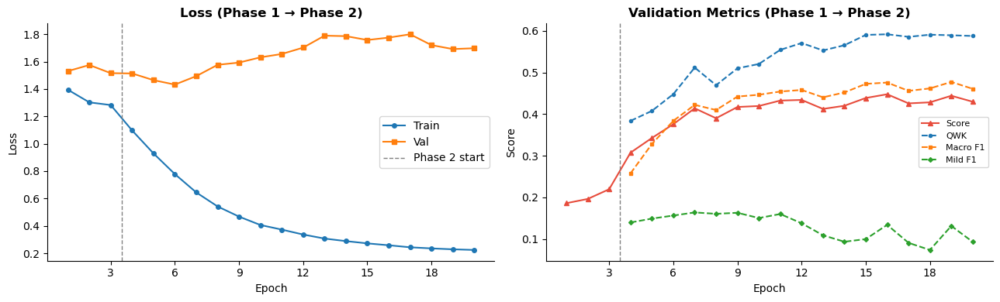

Saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp10_mild_two_phase/figures/exp10_training_curves.png


In [12]:
# ── Training curves — Phase 1 + Phase 2 combined ──────────────────────────────
all_train_loss = history_p1['train_loss'] + history_p2['train_loss']
all_val_loss   = history_p1['val_loss']   + history_p2['val_loss']
all_scores     = history_p1['score']      + history_p2['score']
p1_end         = len(history_p1['train_loss'])
epochs_all     = range(1, len(all_train_loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss curve
axes[0].plot(epochs_all, all_train_loss, marker='o', markersize=4, label='Train')
axes[0].plot(epochs_all, all_val_loss,   marker='s', markersize=4, label='Val')
axes[0].axvline(p1_end + 0.5, color='gray', linestyle='--', lw=1, label='Phase 2 start')
axes[0].set_title('Loss (Phase 1 → Phase 2)', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[0].legend(); axes[0].spines[['top', 'right']].set_visible(False)

# Score curve
axes[1].plot(epochs_all, all_scores, marker='^', markersize=4, color='#E74C3C', label='Score')
# Overlay Phase 2 individual metrics
p2_eps = range(p1_end + 1, p1_end + 1 + len(history_p2['mild_f1']))
axes[1].plot(p2_eps, history_p2['qwk'],      marker='o', markersize=3, linestyle='--', label='QWK')
axes[1].plot(p2_eps, history_p2['macro_f1'], marker='s', markersize=3, linestyle='--', label='Macro F1')
axes[1].plot(p2_eps, history_p2['mild_f1'],  marker='D', markersize=3, linestyle='--', label='Mild F1')
axes[1].axvline(p1_end + 0.5, color='gray', linestyle='--', lw=1)
axes[1].set_title('Validation Metrics (Phase 1 → Phase 2)', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axes[1].legend(fontsize=8); axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(EXP10_FIG_DIR / 'exp10_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EXP10_FIG_DIR}/exp10_training_curves.png')

---
## 10. Load Best Checkpoint

In [13]:
# Load the best validation checkpoint for test evaluation.
# A fresh model instance is created to avoid any state leakage from training.
gc.collect()
torch.cuda.empty_cache()

eval_model = timm.create_model(
    MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES
).to(device)

ckpt = torch.load(EXP10_BEST_PATH, map_location=device, weights_only=False)
eval_model.load_state_dict(ckpt['model_state_dict'])
eval_model.eval()

print(f'Checkpoint loaded: {EXP10_BEST_PATH.name}')
print(f'  epoch            = {ckpt["epoch"]}')
print(f'  val score        = {ckpt["score"]:.4f}')
print(f'  val QWK          = {ckpt["qwk"]:.4f}')
print(f'  val macro F1     = {ckpt["macro_f1"]:.4f}')
print(f'  val Mild F1      = {ckpt["mild_f1"]:.4f}')
print(f'  val balanced acc = {ckpt["balanced_accuracy"]:.4f}')
print()
print('Training config used:')
for k, v in ckpt['config'].items():
    print(f'  {k} = {v}')

Checkpoint loaded: exp10_best.pt
  epoch            = 13
  val score        = 0.4477
  val QWK          = 0.5919
  val macro F1     = 0.4758
  val Mild F1      = 0.1339
  val balanced acc = 0.4736

Training config used:
  BATCH_SIZE = 32
  PHASE1_LR = 0.0001
  PHASE2_LR = 1e-05
  MILD_WEIGHT_BOOST = 1.2
  SAMPLER_TARGET_DIST = [0.44999998807907104, 0.20000000298023224, 0.2199999988079071, 0.06499999761581421, 0.06499999761581421]
  LABEL_SMOOTHING = 0.03


---
## Test Evaluation

The best validation checkpoint is reloaded and evaluated once on the held-out test set. The evaluation focuses on macro F1, QWK, per-class F1, balanced accuracy, and confusion-matrix error patterns rather than accuracy alone, because the dataset is highly imbalanced.

## 11. Test Evaluation

In [14]:
# ── Run test evaluation — called exactly once ──────────────────────────────────
_, y_true, y_pred = run_eval(eval_model, test_loader)
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# ── Aggregate metrics ──────────────────────────────────────────────────────────
test_acc      = accuracy_score(y_true, y_pred)
test_bal_acc  = balanced_accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(y_true, y_pred, average='macro',    zero_division=0)
test_wtd_f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
test_qwk      = cohen_kappa_score(y_true, y_pred, weights='quadratic')
test_f1_per   = f1_score(y_true, y_pred, average=None,
                          labels=list(range(NUM_CLASSES)), zero_division=0)

print('=' * 60)
print('  Exp10 — TEST SET RESULTS')
print('=' * 60)
print(f'  Accuracy          : {test_acc:.4f}')
print(f'  Balanced Accuracy : {test_bal_acc:.4f}')
print(f'  Macro F1          : {test_macro_f1:.4f}')
print(f'  Weighted F1       : {test_wtd_f1:.4f}')
print(f'  QWK               : {test_qwk:.4f}  ← primary clinical metric')
print()
print(f'  Per-class F1:')
for i, name in enumerate(CLASS_NAMES):
    print(f'    {name:<18}: {test_f1_per[i]:.4f}')
print('=' * 60)

eval :   0%|          | 0/165 [00:00<?, ?it/s]

  Exp10 — TEST SET RESULTS
  Accuracy          : 0.7400
  Balanced Accuracy : 0.4908
  Macro F1          : 0.4867
  Weighted F1       : 0.7326
  QWK               : 0.6206  ← primary clinical metric

  Per-class F1:
    No DR             : 0.8611
    Mild              : 0.1314
    Moderate          : 0.4565
    Severe            : 0.4366
    Proliferative     : 0.5479


---
## 12. Classification Report

In [15]:
print('Classification Report — Exp10 Test Set')
print('=' * 60)
print(classification_report(
    y_true, y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
))

Classification Report — Exp10 Test Set
               precision    recall  f1-score   support

        No DR     0.8433    0.8796    0.8611      3872
         Mild     0.1377    0.1257    0.1314       366
     Moderate     0.5159    0.4093    0.4565       794
       Severe     0.4052    0.4733    0.4366       131
Proliferative     0.5310    0.5660    0.5479       106

     accuracy                         0.7400      5269
    macro avg     0.4866    0.4908    0.4867      5269
 weighted avg     0.7278    0.7400    0.7326      5269



---
## 13. Confusion Matrix

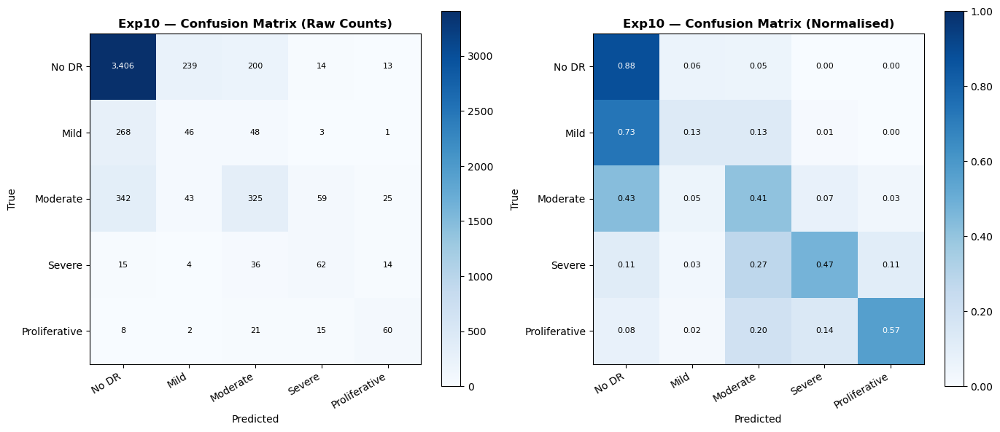

Saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp10_mild_two_phase/figures/exp10_confusion_matrix.png


In [16]:
cm      = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, fmt, subtitle, cmap in [
    (axes[0], cm,      'd',    'Raw Counts',  'Blues'),
    (axes[1], cm_norm, '.2f',  'Normalised',  'Blues'),
]:
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=(None if fmt == 'd' else 1))
    fig.colorbar(im, ax=ax, format=(None if fmt == 'd' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'Exp10 — Confusion Matrix ({subtitle})', fontweight='bold')
    thresh = data.max() / 2 if fmt == 'd' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            val = f'{data[i,j]:,}' if fmt == 'd' else f'{data[i,j]:.2f}'
            ax.text(j, i, val, ha='center', va='center', fontsize=8,
                    color='white' if data[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(EXP10_FIG_DIR / 'exp10_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EXP10_FIG_DIR}/exp10_confusion_matrix.png')

---
## 14. Clinical Error Rates

Standard accuracy metrics do not capture the asymmetric costs of misclassification in DR grading. Missing a Mild case (predicting No DR) is clinically more dangerous than over-grading a healthy image. These rates are reported to assess the clinical safety of the model.

In [17]:
# ── Clinical error rates ───────────────────────────────────────────────────────
# All rates computed from the test confusion matrix.

mild_to_nodr    = cm[1, 0] / cm[1].sum() if cm[1].sum() > 0 else 0.0
moderate_to_nodr = cm[2, 0] / cm[2].sum() if cm[2].sum() > 0 else 0.0
nodr_to_mild    = cm[0, 1] / cm[0].sum() if cm[0].sum() > 0 else 0.0
severe_lower    = cm[3, :3].sum() / cm[3].sum() if cm[3].sum() > 0 else 0.0
prolif_lower    = cm[4, :4].sum() / cm[4].sum() if cm[4].sum() > 0 else 0.0

print('Clinical Error Rates — Exp10 Test Set')
print('=' * 60)
print(f'  Mild       → No DR rate     : {mild_to_nodr:.4f}  ({mild_to_nodr*100:.1f}%)')
print(f'  Moderate   → No DR rate     : {moderate_to_nodr:.4f}  ({moderate_to_nodr*100:.1f}%)')
print(f'  No DR      → Mild rate      : {nodr_to_mild:.4f}  ({nodr_to_mild*100:.1f}%)  target <10%')
print(f'  Severe     → lower-grade    : {severe_lower:.4f}  ({severe_lower*100:.1f}%)')
print(f'  Prolif     → lower-grade    : {prolif_lower:.4f}  ({prolif_lower*100:.1f}%)')
print('=' * 60)
print()

# Clinically important: Mild→No DR is the main target for this experiment
print('Key target: Mild → No DR should be lower than in Exp9.')
print('No DR → Mild should stay controlled (below ~10%) to avoid false alarms.')

# Per-class breakdown for additional context
print('\nPer-class error distribution from confusion matrix:')
print(f'  {"True Class":<18}  {"Total":>6}  ', end='')
for name in CLASS_NAMES:
    print(f'{name[:5]:>7}', end='')
print()
print('─' * 70)
for i, name in enumerate(CLASS_NAMES):
    row_total = cm[i].sum()
    print(f'  {name:<18}  {row_total:>6}  ', end='')
    for j in range(NUM_CLASSES):
        pct = cm[i, j] / row_total * 100 if row_total > 0 else 0
        print(f'{pct:>6.1f}%', end='')
    print()

Clinical Error Rates — Exp10 Test Set
  Mild       → No DR rate     : 0.7322  (73.2%)
  Moderate   → No DR rate     : 0.4307  (43.1%)
  No DR      → Mild rate      : 0.0617  (6.2%)  target <10%
  Severe     → lower-grade    : 0.4198  (42.0%)
  Prolif     → lower-grade    : 0.4340  (43.4%)

Key target: Mild → No DR should be lower than in Exp9.
No DR → Mild should stay controlled (below ~10%) to avoid false alarms.

Per-class error distribution from confusion matrix:
  True Class           Total    No DR   Mild  Moder  Sever  Proli
──────────────────────────────────────────────────────────────────────
  No DR                 3872    88.0%   6.2%   5.2%   0.4%   0.3%
  Mild                   366    73.2%  12.6%  13.1%   0.8%   0.3%
  Moderate               794    43.1%   5.4%  40.9%   7.4%   3.1%
  Severe                 131    11.5%   3.1%  27.5%  47.3%  10.7%
  Proliferative          106     7.5%   1.9%  19.8%  14.2%  56.6%


---
## Final Comparison

Experiment 10 is compared against the strongest previous results:

- **Baseline:** strongest No DR stability,
- **Exp7:** strong QWK and severity balance from two-phase fine-tuning,
- **Exp9:** best previous class-wise balance from grid-search hyperparameters,
- **Exp2 New Balanced:** strongest previous Mild recall but weaker QWK.

The final model is considered successful only if it improves Mild F1 and macro F1 without substantially reducing QWK or No DR F1.

## 15. Final Comparison with Previous Experiments

In [18]:
# ── Comparison table ───────────────────────────────────────────────────────────
#
# Known test-set results from previous experiments.
# Update with your actual logged values if they differ from these.
# '—' denotes metrics not logged for that experiment.

PRIOR = [
    {'Experiment': 'Baseline',
     'Accuracy': 0.7810, 'Macro F1': '—',    'QWK': 0.6470,
     'No DR F1': 0.8870, 'Mild F1': 0.0980,
     'Moderate F1': 0.5030, 'Severe F1': 0.4230, 'Proliferative F1': 0.6360},
    {'Experiment': 'Exp7 — Two-Phase v2',
     'Accuracy': '—',   'Macro F1': '—',    'QWK': 0.6497,
     'No DR F1': 0.8518, 'Mild F1': 0.1510,
     'Moderate F1': 0.5069, 'Severe F1': 0.4096, 'Proliferative F1': 0.6468},
    {'Experiment': 'Exp9 — Grid Best',
     'Accuracy': '—',   'Macro F1': '—',    'QWK': 0.6470,
     'No DR F1': 0.8580, 'Mild F1': 0.1790,
     'Moderate F1': 0.5029, 'Severe F1': 0.4309, 'Proliferative F1': 0.6337},
    {'Experiment': 'Exp2 New Balanced',
     'Accuracy': 0.6719, 'Macro F1': 0.4840, 'QWK': 0.5930,
     'No DR F1': 0.8146, 'Mild F1': 0.1776,
     'Moderate F1': 0.4171, 'Severe F1': 0.4276, 'Proliferative F1': 0.5849},
]

# Exp10 row from actual test results
exp10_row = {
    'Experiment':      'Exp10 — Mild Two-Phase ★',
    'Accuracy':        round(test_acc,      4),
    'Macro F1':        round(test_macro_f1, 4),
    'QWK':             round(test_qwk,      4),
    'No DR F1':        round(test_f1_per[0], 4),
    'Mild F1':         round(test_f1_per[1], 4),
    'Moderate F1':     round(test_f1_per[2], 4),
    'Severe F1':       round(test_f1_per[3], 4),
    'Proliferative F1': round(test_f1_per[4], 4),
}

comparison_df = pd.DataFrame(PRIOR + [exp10_row])

print('Final Comparison Table — Test Set')
print('(— = value not logged for that experiment)')
print()
print(comparison_df.to_string(index=False))

Final Comparison Table — Test Set
(— = value not logged for that experiment)

              Experiment Accuracy Macro F1    QWK  No DR F1  Mild F1  Moderate F1  Severe F1  Proliferative F1
                Baseline    0.781        — 0.6470    0.8870   0.0980       0.5030     0.4230            0.6360
     Exp7 — Two-Phase v2        —        — 0.6497    0.8518   0.1510       0.5069     0.4096            0.6468
        Exp9 — Grid Best        —        — 0.6470    0.8580   0.1790       0.5029     0.4309            0.6337
       Exp2 New Balanced   0.6719    0.484 0.5930    0.8146   0.1776       0.4171     0.4276            0.5849
Exp10 — Mild Two-Phase ★     0.74   0.4867 0.6206    0.8611   0.1314       0.4565     0.4366            0.5479


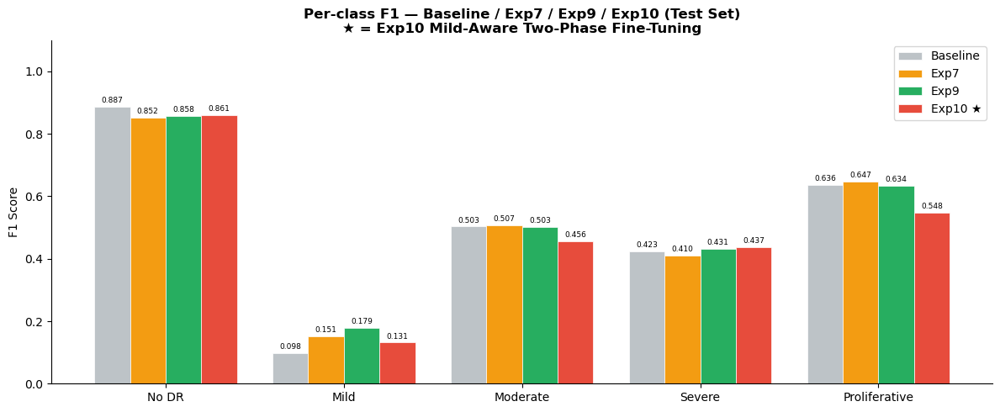

Saved → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp10_mild_two_phase/figures/exp10_per_class_f1_comparison.png


In [19]:
# ── Per-class F1 bar chart ─────────────────────────────────────────────────────
# Compare Baseline, Exp7, Exp9, Exp10 per-class F1 side by side.
# Exp2 NB omitted from chart (several per-class values unknown).

chart_data = [
    ('Baseline',    np.array([0.8870, 0.0980, 0.5030, 0.4230, 0.6360]), '#BDC3C7'),
    ('Exp7',        np.array([0.8518, 0.1510, 0.5069, 0.4096, 0.6468]), '#F39C12'),
    ('Exp9',        np.array([0.8580, 0.1790, 0.5029, 0.4309, 0.6337]), '#27AE60'),
    ('Exp10 ★',     test_f1_per,                                         '#E74C3C'),
]

x     = np.arange(NUM_CLASSES)
width = 0.20
offsets = [-1.5, -0.5, 0.5, 1.5]

fig, ax = plt.subplots(figsize=(12, 5))
for offset, (label, f1_arr, color) in zip(offsets, chart_data):
    bars = ax.bar(x + offset * width, f1_arr, width,
                  label=label, color=color, edgecolor='white', linewidth=0.5)
    ax.bar_label(bars, fmt='%.3f', fontsize=6.5, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel('F1 Score')
ax.set_ylim(0, 1.10)
ax.set_title(
    'Per-class F1 — Baseline / Exp7 / Exp9 / Exp10 (Test Set)\n'
    '★ = Exp10 Mild-Aware Two-Phase Fine-Tuning',
    fontweight='bold'
)
ax.legend(loc='upper right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(EXP10_FIG_DIR / 'exp10_per_class_f1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {EXP10_FIG_DIR}/exp10_per_class_f1_comparison.png')

---
## Success Criteria

Experiment 10 is successful if:

- Mild F1 improves beyond Exp9 (target > 0.179),
- Macro F1 improves beyond Exp9 (target > 0.5209),
- QWK remains close to or above 0.64,
- No DR F1 remains at least around 0.84–0.85,
- Moderate and Proliferative performance do not collapse,
- Mild → No DR rate decreases without causing excessive No DR → Mild errors.

| Metric | Target | Status |
|---|---|---|
| Mild F1 | > 0.179 | Evaluated in cell below |
| Macro F1 | > 0.5209 | Evaluated in cell below |
| QWK | ≥ 0.64 | Evaluated in cell below |
| No DR F1 | ≥ 0.84–0.85 | Evaluated in cell below |

In [20]:
# ── Automated success criteria check ──────────────────────────────────────────
criteria = [
    ('Mild F1   > 0.179',   test_f1_per[1] > 0.179),
    ('Macro F1  > 0.5209',  test_macro_f1  > 0.5209),
    ('QWK       >= 0.640',  test_qwk       >= 0.640),
    ('No DR F1  >= 0.840',  test_f1_per[0] >= 0.840),
    ('No DR→Mild < 10%',   nodr_to_mild   <  0.10),
]

print('Success Criteria Check — Exp10 Test Set')
print('=' * 55)
all_passed = True
for desc, passed in criteria:
    status = '✅ PASS' if passed else '❌ FAIL'
    print(f'  {status}  {desc}')
    if not passed:
        all_passed = False
print('=' * 55)
print()
print(f'Mild F1         : {test_f1_per[1]:.4f}  (target > 0.179)')
print(f'Macro F1        : {test_macro_f1:.4f}  (target > 0.5209)')
print(f'QWK             : {test_qwk:.4f}  (target >= 0.64)')
print(f'No DR F1        : {test_f1_per[0]:.4f}  (target >= 0.84)')
print(f'No DR → Mild    : {nodr_to_mild*100:.1f}%  (target < 10%)')
print()
if all_passed:
    print('✅ All criteria passed. Exp10 is the recommended final model.')
else:
    print('⚠️  One or more criteria not met. Compare with Exp9 and select the stronger model.')

Success Criteria Check — Exp10 Test Set
  ❌ FAIL  Mild F1   > 0.179
  ❌ FAIL  Macro F1  > 0.5209
  ❌ FAIL  QWK       >= 0.640
  ✅ PASS  No DR F1  >= 0.840
  ✅ PASS  No DR→Mild < 10%

Mild F1         : 0.1314  (target > 0.179)
Macro F1        : 0.4867  (target > 0.5209)
QWK             : 0.6206  (target >= 0.64)
No DR F1        : 0.8611  (target >= 0.84)
No DR → Mild    : 6.2%  (target < 10%)

⚠️  One or more criteria not met. Compare with Exp9 and select the stronger model.


---
## Experiment 10 Conclusion

Experiment 10 tested whether a controlled Mild-aware two-phase training strategy could improve the weakest class without destroying the remaining DR grades. The experiment combined head warm-up, low-learning-rate full fine-tuning, safe augmentation, clipped class weighting, and a moderate Mild-aware sampler.

The result should be interpreted using macro F1, QWK, per-class F1, and clinically relevant confusion-matrix errors. If Mild F1 improves while No DR and QWK remain stable, this indicates that the model has learned a better early-disease boundary. If QWK or No DR F1 drops substantially, then the Mild-focused correction is too aggressive and Exp9 should remain the stronger final model.

---

**Model selection rule:**  
If Mild F1 > 0.179 AND QWK ≥ 0.64 AND No DR F1 ≥ 0.84 → **Exp10 is the final model.**  
Otherwise → **Exp9 remains the stronger baseline and should be reported as final.**

# Experiment 11 — Mild/Severe Refined Experiment

**EEEM068 Applied Machine Learning — University of Surrey**  
**Model:** DeiT-III-Base/16 (`deit3_base_patch16_224.fb_in1k`)  
**Based on:** Experiment 9 — Balanced DeiT-III Configuration Search

---

## Aim
This experiment is based on the best-performing configuration from Experiment 9. The aim is to improve class-wise performance, especially Mild DR and Severe DR, while maintaining stable overall accuracy, QWK, macro F1-score, and No DR performance.

## Motivation
Experiment 9 achieved the best overall balance among the previous experiments, but Mild DR remained the weakest class. Since the dataset is highly imbalanced, this experiment applies a controlled class-weight refinement instead of aggressive rebalancing.

## Main Changes from Experiment 9
- Same model family: DeiT-III.
- Same train, validation, and labelled test split.
- Same preprocessing pipeline.
- Lower learning rate for safer fine-tuning.
- Mild and Severe class weights are slightly increased.
- Weighted cross-entropy is used instead of aggressive focal loss.
- Best checkpoint is selected using QWK + macro F1-score instead of accuracy only.

## Success Criteria
Experiment 11 will replace Experiment 9 only if:
- Mild F1-score improves above 0.1790.
- Macro F1-score improves above 0.5209.
- QWK remains close to or above 0.6470.
- No DR F1-score remains at least 0.8500.
- Accuracy remains close to or above 0.7350.

---
## 1. Imports and Environment Setup

In [1]:
import os
import gc
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report,
)

import warnings
warnings.filterwarnings('ignore')

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')
print(f'Device  : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')

PyTorch : 2.11.0+cu130
timm    : 1.0.27
CUDA    : True
Device  : NVIDIA RTX A4000


---
## 2. Reproducibility and Device

In [2]:
SEED = 42

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = torch.cuda.is_available()

print(f'Device  : {device}')
print(f'AMP     : {use_amp}')

Device  : cuda
AMP     : True


---
## 3. Paths and Output Directories

In [3]:
# ── Auto-detect project root ───────────────────────────────────────────────────
NOTEBOOK_DIR = Path().resolve()

def _find_root(start: Path) -> Path:
    for candidate in [start, start.parent, start.parent.parent]:
        if (candidate / 'data' / 'diabetic-retinopathy-detection').exists():
            return candidate
    raise FileNotFoundError(
        'Could not locate data/diabetic-retinopathy-detection. '
        'Run from the project root or a subdirectory of it.'
    )

ROOT = _find_root(NOTEBOOK_DIR)

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

# ── Output directories ─────────────────────────────────────────────────────────
EXP_NAME    = 'experiment_11_mild_severe_refined'
EXP_OUT_DIR = ROOT / 'outputs' / EXP_NAME
SAVE_DIR    = EXP_OUT_DIR / 'checkpoints'
FIG_DIR     = EXP_OUT_DIR / 'figures'

for d in (SAVE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'ROOT         : {ROOT}')
print(f'TRAIN_DIR    : {TRAIN_DIR}')
print(f'VAL_DIR      : {VAL_DIR}')
print(f'TEST_DIR     : {TEST_LABELS_DIR}')
print(f'Output dir   : {EXP_OUT_DIR}')

# Sanity check
for p in [TRAIN_DIR, VAL_DIR, TEST_LABELS_DIR, TRAIN_CSV, VAL_CSV, TEST_CSV]:
    status = '✓' if p.exists() else '✗ NOT FOUND'
    print(f'  {status}  {p}')

ROOT         : /scratch/AML Latest /AML_G14_CW
TRAIN_DIR    : /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train_proc
VAL_DIR      : /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/val_proc
TEST_DIR     : /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/test_labels_proc
Output dir   : /scratch/AML Latest /AML_G14_CW/outputs/experiment_11_mild_severe_refined
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train_proc
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/val_proc
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/test_labels_proc
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/train_split.csv
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/val_split.csv
  ✓  /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection/test_split.csv


---
## 4. Hyperparameter Configuration

All changes from Experiment 9 are marked with `# ← CHANGED`.

In [4]:
# ── Model ──────────────────────────────────────────────────────────────────────
MODEL_NAME  = 'deit3_base_patch16_224.fb_in1k'  # same as Exp 9
NUM_CLASSES = 5
IMAGE_SIZE  = 224
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
VIT_MEAN    = (0.485, 0.456, 0.406)
VIT_STD     = (0.229, 0.224, 0.225)

# ── Training ───────────────────────────────────────────────────────────────────
BATCH_SIZE    = 32          # same as Exp 9
NUM_WORKERS   = 4           # same as Exp 9
EPOCHS        = 25          # same as Exp 9
PATIENCE      = 7           # ← CHANGED: was 4 in Exp 9; gives minority classes more time

LEARNING_RATE = 7e-6        # ← CHANGED: was 3e-5 in Exp 9; safer for small refinement
WEIGHT_DECAY  = 1e-4        # ← CHANGED: was 5e-2 in Exp 9

USE_WEIGHTED_LOSS = True    # ← CHANGED: controlled class weights applied
USE_FOCAL_LOSS    = False   # not used — focal loss caused instability in earlier experiments

print('Experiment 11 — Hyperparameter Configuration')
print('=' * 52)
print(f'  Model         : {MODEL_NAME}')
print(f'  Image size    : {IMAGE_SIZE}')
print(f'  Batch size    : {BATCH_SIZE}')
print(f'  Epochs        : {EPOCHS}')
print(f'  Patience      : {PATIENCE}  (← 7, up from 4)')
print(f'  LR            : {LEARNING_RATE}  (← 7e-6, down from 3e-5)')
print(f'  Weight decay  : {WEIGHT_DECAY}  (← 1e-4, down from 5e-2)')
print(f'  Weighted loss : {USE_WEIGHTED_LOSS}')
print(f'  Focal loss    : {USE_FOCAL_LOSS}')
print('=' * 52)

Experiment 11 — Hyperparameter Configuration
  Model         : deit3_base_patch16_224.fb_in1k
  Image size    : 224
  Batch size    : 32
  Epochs        : 25
  Patience      : 7  (← 7, up from 4)
  LR            : 7e-06  (← 7e-6, down from 3e-5)
  Weight decay  : 0.0001  (← 1e-4, down from 5e-2)
  Weighted loss : True
  Focal loss    : False


---
## 5. Load Data

In [5]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images')
print(f'Val   : {len(val_df):,} images')
print(f'Test  : {len(test_df):,} images')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')

Train : 24,588 images
Val   : 5,269 images
Test  : 5,269 images

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106


---
## 6. Dataset and DataLoaders

Same augmentation pipeline as Experiment 9 — safe, clinically motivated transforms only.

In [6]:
class DRDataset(Dataset):
    """Fundus image dataset for diabetic retinopathy grading."""

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# ── Training transform — same safe augmentation as Experiment 9 ────────────────
# No vertical flip, no Mixup, no strong affine — consistent with previous results
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.08, contrast=0.08,
                           saturation=0.04, hue=0.01),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02),
                            scale=(0.98, 1.02)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

# ── Evaluation transform — deterministic ───────────────────────────────────────
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),
])

# ── Datasets ───────────────────────────────────────────────────────────────────
train_ds = DRDataset(train_df, TRAIN_DIR, transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

# ── DataLoaders ────────────────────────────────────────────────────────────────
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0
)

print(f'Train loader : {len(train_loader)} batches/epoch  ({len(train_ds):,} images)')
print(f'Val loader   : {len(val_loader)} batches')
print(f'Test loader  : {len(test_loader)} batches')
print('Augmentation : HFlip + Rotation(7°) + ColorJitter + Affine  (same as Exp 9)')

Train loader : 768 batches/epoch  (24,588 images)
Val loader   : 165 batches
Test loader  : 165 batches
Augmentation : HFlip + Rotation(7°) + ColorJitter + Affine  (same as Exp 9)


---
## 7. Class Weights and Loss Function

Key change from Experiment 9: small targeted boosts for Mild (×1.35) and Severe (×1.25).
Weights are deliberately conservative — aggressive values (Mild=2.0+) caused No DR collapse in earlier experiments.

In [7]:
# ── Class weights — controlled refinement ──────────────────────────────────────
# Rationale:
#   No DR (1.00)       — dominant class, no upweighting needed
#   Mild (1.35)        — weakest class in Exp 9; small boost to improve recall
#   Moderate (1.00)    — well-handled in Exp 9; no change
#   Severe (1.25)      — second weakest; modest boost
#   Proliferative (1.10) — slight boost; already reasonable in Exp 9
#
# Deliberately NOT using 2.0+ for Mild:
#   Exp 2B and Exp 8 showed that aggressive Mild weighting collapses No DR F1 and QWK.
class_weights = torch.tensor([
    1.00,   # 0 - No DR
    1.35,   # 1 - Mild        ← CHANGED from Exp 9
    1.00,   # 2 - Moderate
    1.25,   # 3 - Severe      ← CHANGED from Exp 9
    1.10,   # 4 - Proliferative DR
], dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print('Class weights (Exp 11):')
for i, (name, w) in enumerate(zip(CLASS_NAMES, class_weights.cpu().tolist())):
    print(f'  Grade {i}  {name:<18} : {w:.2f}')
print()
print('Loss : CrossEntropyLoss(weight=class_weights)')
print('Note : No label smoothing, no focal loss — consistent with conservative design')

Class weights (Exp 11):
  Grade 0  No DR              : 1.00
  Grade 1  Mild               : 1.35
  Grade 2  Moderate           : 1.00
  Grade 3  Severe             : 1.25
  Grade 4  Proliferative      : 1.10

Loss : CrossEntropyLoss(weight=class_weights)
Note : No label smoothing, no focal loss — consistent with conservative design


---
## 8. Model, Optimiser, and Scheduler

In [8]:
gc.collect()
torch.cuda.empty_cache()
set_seed(SEED)

# ── Model ──────────────────────────────────────────────────────────────────────
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,
).to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Model           : {MODEL_NAME}')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable_params:,}')
print(f'Head            : {model.head}')
print()

# ── Optimiser ──────────────────────────────────────────────────────────────────
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

# ── Scheduler ──────────────────────────────────────────────────────────────────
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
)

# ── AMP scaler ─────────────────────────────────────────────────────────────────
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

print(f'Optimiser : AdamW  lr={LEARNING_RATE}  wd={WEIGHT_DECAY}')
print(f'Scheduler : CosineAnnealingLR  T_max={EPOCHS}')
print(f'AMP       : {use_amp}')

Model           : deit3_base_patch16_224.fb_in1k
Total params    : 85,820,165
Trainable params: 85,820,165
Head            : Linear(in_features=768, out_features=5, bias=True)

Optimiser : AdamW  lr=7e-06  wd=0.0001
Scheduler : CosineAnnealingLR  T_max=25
AMP       : True


---
## 9. Training Loop

Checkpoint selection uses `0.5 × QWK + 0.5 × Macro F1` rather than validation accuracy,
because accuracy alone over-rewards the dominant No DR class.

In [9]:
# ── History buffers ────────────────────────────────────────────────────────────
history = {
    'train_loss': [], 'val_loss': [],
    'val_acc': [], 'val_qwk': [],
    'val_macro_f1': [], 'selection_score': [],
}

best_score      = -1.0
patience_counter = 0
BEST_PATH       = EXP_OUT_DIR / 'best_model_exp11.pt'

print(f'Training: {EXP_NAME}')
print(f'Checkpoint criterion : 0.5 × QWK + 0.5 × Macro F1')
print(f'Patience : {PATIENCE} epochs')
print()
print(
    f'{"Epoch":<8} {"Tr Loss":>9} {"Val Loss":>9} '
    f'{"Val Acc":>8} {"QWK":>8} {"MacroF1":>9} {"Score":>8}'
)
print('─' * 68)

for epoch in range(1, EPOCHS + 1):

    # ── Train ──────────────────────────────────────────────────────────────────
    model.train()
    total_train_loss = 0.0
    total_train_seen = 0
    train_preds, train_labels = [], []

    for images, labels in tqdm(train_loader, leave=False, desc=f'Ep{epoch:02d} train'):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if use_amp:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        batch_size_actual = labels.size(0)
        total_train_loss += loss.item() * batch_size_actual
        total_train_seen += batch_size_actual
        train_preds.extend(logits.argmax(dim=1).detach().cpu().tolist())
        train_labels.extend(labels.detach().cpu().tolist())

        del images, labels, logits, loss

    train_loss = total_train_loss / total_train_seen
    scheduler.step()

    # ── Validate ───────────────────────────────────────────────────────────────
    model.eval()
    total_val_loss = 0.0
    val_preds, val_labels_list = [], []

    with torch.inference_mode():
        for images, labels in tqdm(val_loader, leave=False, desc=f'Ep{epoch:02d} val  '):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                loss   = criterion(logits, labels)

            total_val_loss += loss.item() * labels.size(0)
            val_preds.extend(logits.argmax(dim=1).detach().cpu().tolist())
            val_labels_list.extend(labels.detach().cpu().tolist())

            del images, labels, logits, loss

    val_loss = total_val_loss / len(val_ds)

    # ── Metrics ────────────────────────────────────────────────────────────────
    val_acc       = accuracy_score(val_labels_list, val_preds)
    val_macro_f1  = f1_score(val_labels_list, val_preds, average='macro', zero_division=0)
    val_weighted_f1 = f1_score(val_labels_list, val_preds, average='weighted', zero_division=0)
    val_qwk       = cohen_kappa_score(val_labels_list, val_preds, weights='quadratic')
    selection_score = 0.5 * val_qwk + 0.5 * val_macro_f1

    # ── Log history ────────────────────────────────────────────────────────────
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_qwk'].append(val_qwk)
    history['val_macro_f1'].append(val_macro_f1)
    history['selection_score'].append(selection_score)

    # ── Checkpoint ─────────────────────────────────────────────────────────────
    marker = ''
    if selection_score > best_score:
        best_score       = selection_score
        patience_counter = 0

        torch.save({
            'epoch'               : epoch,
            'model_state_dict'    : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_accuracy'        : val_acc,
            'val_qwk'             : val_qwk,
            'val_macro_f1'        : val_macro_f1,
            'selection_score'     : selection_score,
            'class_weights'       : class_weights.detach().cpu().tolist(),
            'experiment'          : EXP_NAME,
        }, EXP_OUT_DIR / 'best_model_exp11.pt')

        print(f'Saved best model at epoch {epoch} | Score: {selection_score:.4f}')
        marker = f'  ← best (score={selection_score:.4f})'
    else:
        patience_counter += 1

    print(
        f'Epoch {epoch}/{EPOCHS} | '
        f'Train Loss: {train_loss:.4f} | '
        f'Val Loss: {val_loss:.4f} | '
        f'Val Acc: {val_acc:.4f} | '
        f'Val QWK: {val_qwk:.4f} | '
        f'Val Macro F1: {val_macro_f1:.4f} | '
        f'Selection Score: {selection_score:.4f}'
        + marker
    )

    if patience_counter >= PATIENCE:
        print(f'\nEarly stopping at epoch {epoch} (patience={PATIENCE}).')
        break

print(f'\nTraining complete. Best score: {best_score:.4f}  →  {BEST_PATH}')

Training: experiment_11_mild_severe_refined
Checkpoint criterion : 0.5 × QWK + 0.5 × Macro F1
Patience : 7 epochs

Epoch      Tr Loss  Val Loss  Val Acc      QWK   MacroF1    Score
────────────────────────────────────────────────────────────────────


Ep01 train:   0%|          | 0/768 [00:00<?, ?it/s]

Ep01 val  :   0%|          | 0/165 [00:00<?, ?it/s]

Saved best model at epoch 1 | Score: 0.4742
Epoch 1/25 | Train Loss: 0.7925 | Val Loss: 0.7336 | Val Acc: 0.7704 | Val QWK: 0.5462 | Val Macro F1: 0.4022 | Selection Score: 0.4742  ← best (score=0.4742)


Ep02 train:   0%|          | 0/768 [00:00<?, ?it/s]

...

Ep15 val  :   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 15/25 | Train Loss: 0.2823 | Val Loss: 0.8467 | Val Acc: 0.7707 | Val QWK: 0.6220 | Val Macro F1: 0.4792 | Selection Score: 0.5506


Ep16 train:   0%|          | 0/768 [00:00<?, ?it/s]

Ep16 val  :   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 16/25 | Train Loss: 0.2599 | Val Loss: 0.8489 | Val Acc: 0.7559 | Val QWK: 0.6237 | Val Macro F1: 0.4751 | Selection Score: 0.5494

Early stopping at epoch 16 (patience=7).

Training complete. Best score: 0.5716  →  /scratch/AML Latest /AML_G14_CW/outputs/experiment_11_mild_severe_refined/best_model_exp11.pt


---
## 10. Training Curves

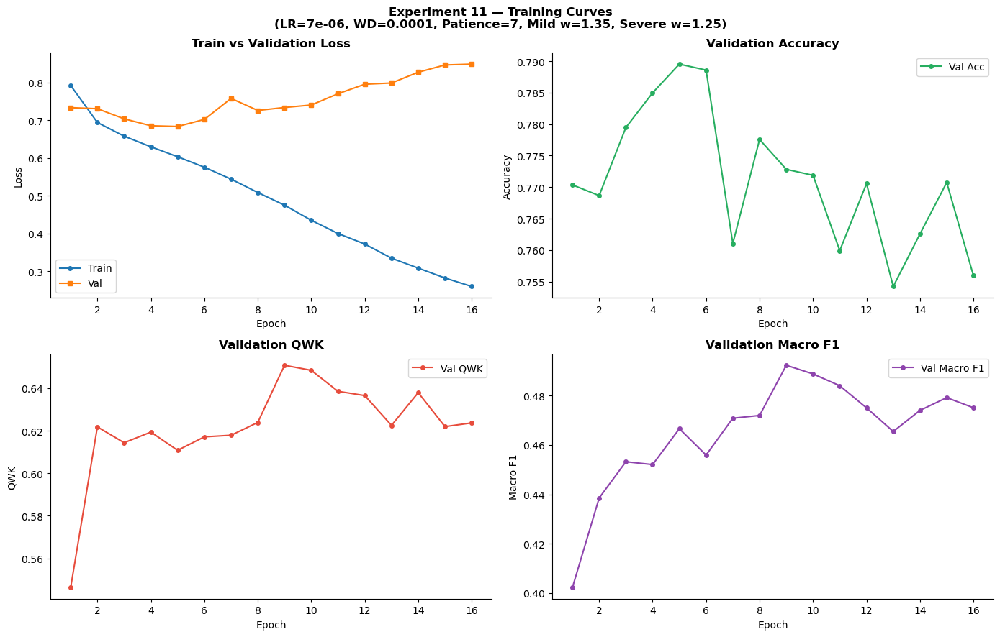

Saved → /scratch/AML Latest /AML_G14_CW/outputs/experiment_11_mild_severe_refined/figures/exp11_training_curves.png


In [10]:
epochs_ran = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    f'Experiment 11 — Training Curves\n'
    f'(LR={LEARNING_RATE}, WD={WEIGHT_DECAY}, Patience={PATIENCE}, '
    f'Mild w=1.35, Severe w=1.25)',
    fontweight='bold', fontsize=12
)

# 1. Loss
ax = axes[0, 0]
ax.plot(epochs_ran, history['train_loss'], marker='o', markersize=4, label='Train')
ax.plot(epochs_ran, history['val_loss'],   marker='s', markersize=4, label='Val')
ax.set_title('Train vs Validation Loss', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# 2. Validation Accuracy
ax = axes[0, 1]
ax.plot(epochs_ran, history['val_acc'], marker='o', markersize=4, color='#27AE60', label='Val Acc')
ax.set_title('Validation Accuracy', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# 3. Validation QWK
ax = axes[1, 0]
ax.plot(epochs_ran, history['val_qwk'], marker='o', markersize=4, color='#E74C3C', label='Val QWK')
ax.set_title('Validation QWK', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('QWK')
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# 4. Validation Macro F1
ax = axes[1, 1]
ax.plot(epochs_ran, history['val_macro_f1'], marker='o', markersize=4, color='#8E44AD', label='Val Macro F1')
ax.set_title('Validation Macro F1', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Macro F1')
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
fig.savefig(FIG_DIR / 'exp11_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {FIG_DIR}/exp11_training_curves.png')

---
## 11. Load Best Checkpoint

In [11]:
gc.collect()
torch.cuda.empty_cache()

eval_model = timm.create_model(
    MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES
).to(device)

ckpt = torch.load(BEST_PATH, map_location=device, weights_only=False)
eval_model.load_state_dict(ckpt['model_state_dict'])
eval_model.eval()

print(f'Checkpoint loaded : {BEST_PATH.name}')
print(f'  epoch           = {ckpt["epoch"]}')
print(f'  val accuracy    = {ckpt["val_accuracy"]:.4f}')
print(f'  val QWK         = {ckpt["val_qwk"]:.4f}')
print(f'  val macro F1    = {ckpt["val_macro_f1"]:.4f}')
print(f'  selection score = {ckpt["selection_score"]:.4f}')

Checkpoint loaded : best_model_exp11.pt
  epoch           = 9
  val accuracy    = 0.7728
  val QWK         = 0.6508
  val macro F1    = 0.4923
  selection score = 0.5716


---
## 12. Test Set Evaluation

In [12]:
eval_model.eval()
test_preds_list, test_labels_list = [], []

with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc='Test eval'):
        images = images.to(device, non_blocking=True)
        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = eval_model(images)
        test_preds_list.extend(logits.argmax(dim=1).cpu().tolist())
        test_labels_list.extend(labels.tolist())

y_true = np.array(test_labels_list)
y_pred = np.array(test_preds_list)

# ── Aggregate metrics ──────────────────────────────────────────────────────────
test_acc       = accuracy_score(y_true, y_pred)
test_macro_f1  = f1_score(y_true, y_pred, average='macro',    zero_division=0)
test_wtd_f1    = f1_score(y_true, y_pred, average='weighted', zero_division=0)
test_qwk       = cohen_kappa_score(y_true, y_pred, weights='quadratic')
class_f1       = f1_score(y_true, y_pred, average=None,
                           labels=list(range(NUM_CLASSES)), zero_division=0)

print('=' * 60)
print('  Experiment 11 — TEST SET RESULTS')
print('=' * 60)
print(f'  Accuracy     : {test_acc:.4f}')
print(f'  QWK          : {test_qwk:.4f}  ← primary clinical metric')
print(f'  Macro F1     : {test_macro_f1:.4f}')
print(f'  Weighted F1  : {test_wtd_f1:.4f}')
print()
print('  Per-class F1:')
EXP9_F1 = [0.8580, 0.1790, 0.5029, 0.4309, 0.6337]
for i, (name, f1v, e9) in enumerate(zip(CLASS_NAMES, class_f1, EXP9_F1)):
    delta = f1v - e9
    tag   = f'▲ +{delta:.4f}' if delta >= 0 else f'▼ {delta:.4f}'
    print(f'    Grade {i}  {name:<18}: {f1v:.4f}  (Exp9={e9:.4f}  {tag})')
print('=' * 60)

Test eval:   0%|          | 0/165 [00:00<?, ?it/s]

  Experiment 11 — TEST SET RESULTS
  Accuracy     : 0.7838
  QWK          : 0.6825  ← primary clinical metric
  Macro F1     : 0.5157
  Weighted F1  : 0.7648

  Per-class F1:
    Grade 0  No DR             : 0.8906  (Exp9=0.8580  ▲ +0.0326)
    Grade 1  Mild              : 0.1356  (Exp9=0.1790  ▼ -0.0434)
    Grade 2  Moderate          : 0.5192  (Exp9=0.5029  ▲ +0.0163)
    Grade 3  Severe            : 0.4017  (Exp9=0.4309  ▼ -0.0292)
    Grade 4  Proliferative     : 0.6316  (Exp9=0.6337  ▼ -0.0021)


---
## 13. Classification Report

In [13]:
print('Classification Report — Experiment 11 Test Set')
print('=' * 60)
print(classification_report(
    y_true, y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
))

# ── Save classification report as CSV ────────────────────────────────────────
report_dict = classification_report(
    y_true, y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
    output_dict=True,
)
report_df = pd.DataFrame(report_dict).T
report_df.to_csv(EXP_OUT_DIR / "exp11_classification_report.csv")
print(f'Saved classification report → {EXP_OUT_DIR}/exp11_classification_report.csv')
report_df


Classification Report — Experiment 11 Test Set
               precision    recall  f1-score   support

        No DR     0.8497    0.9357    0.8906      3872
         Mild     0.1786    0.1093    0.1356       366
     Moderate     0.6095    0.4521    0.5192       794
       Severe     0.4444    0.3664    0.4017       131
Proliferative     0.7143    0.5660    0.6316       106

     accuracy                         0.7838      5269
    macro avg     0.5593    0.4859    0.5157      5269
 weighted avg     0.7541    0.7838    0.7648      5269

Saved classification report → /scratch/AML Latest /AML_G14_CW/outputs/experiment_11_mild_severe_refined/exp11_classification_report.csv


,precision,recall,f1-score,support
No DR,0.849672,0.935692,0.890610,3872.00000
Mild,0.178571,0.109290,0.135593,366.00000
Moderate,0.609508,0.452141,0.519161,794.00000
Severe,0.444444,0.366412,0.401674,131.00000
Proliferative,0.714286,0.566038,0.631579,106.00000
accuracy,0.783830,0.783830,0.783830,0.78383
macro avg,0.559296,0.485915,0.515723,5269.00000
weighted avg,0.754066,0.783830,0.764822,5269.00000


---
## 14. Confusion Matrix

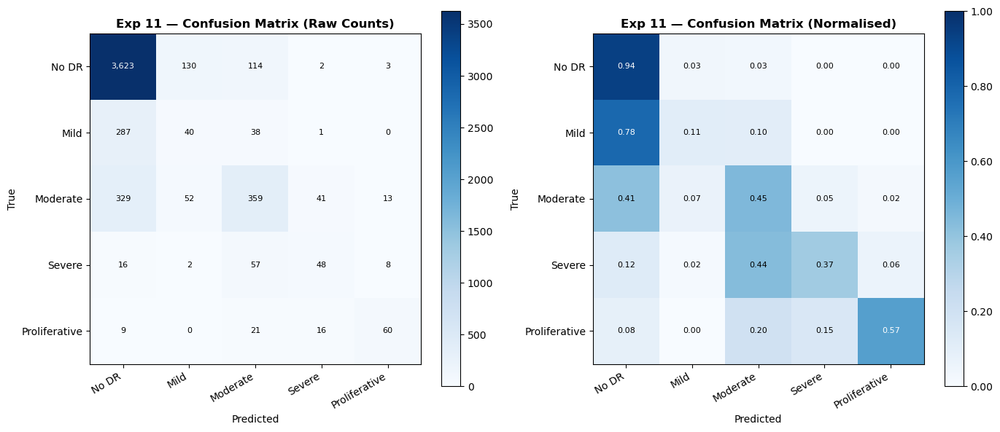

Saved → /scratch/AML Latest /AML_G14_CW/outputs/experiment_11_mild_severe_refined/figures/exp11_confusion_matrix.png


In [14]:
cm      = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, fmt, subtitle, cmap in [
    (axes[0], cm,      'd',    'Raw Counts',  'Blues'),
    (axes[1], cm_norm, '.2f',  'Normalised',  'Blues'),
]:
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=(None if fmt == 'd' else 1))
    fig.colorbar(im, ax=ax, format=(None if fmt == 'd' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'Exp 11 — Confusion Matrix ({subtitle})', fontweight='bold')
    thresh = data.max() / 2 if fmt == 'd' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            val = f'{data[i, j]:,}' if fmt == 'd' else f'{data[i, j]:.2f}'
            ax.text(j, i, val, ha='center', va='center', fontsize=8,
                    color='white' if data[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIG_DIR / 'exp11_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {FIG_DIR}/exp11_confusion_matrix.png')

---
## 15. Clinical Error Rates

In [15]:
lmap = {0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative'}

nodr_to_mild = cm[0, 1] / cm[0].sum() if cm[0].sum() > 0 else 0.0
mild_to_nodr = cm[1, 0] / cm[1].sum() if cm[1].sum() > 0 else 0.0

print('Clinical Error Rates — Exp 11 Test Set')
print('=' * 60)
print(f'  Mild → No DR (missed disease) : {mild_to_nodr:.4f}  ({mild_to_nodr*100:.1f}%)')
print(f'  No DR → Mild (false alarm)    : {nodr_to_mild:.4f}  ({nodr_to_mild*100:.1f}%)')
print()
print('All error rates ≥ 5%:')
for src in range(5):
    row_total = cm[src].sum()
    if row_total == 0:
        continue
    for dst in range(5):
        if src == dst:
            continue
        rate = cm[src, dst] / row_total
        if rate >= 0.05:
            print(f'  {lmap[src]:<18} → {lmap[dst]:<18}: {rate:.3f}  ({rate*100:.1f}%)')

Clinical Error Rates — Exp 11 Test Set
  Mild → No DR (missed disease) : 0.7842  (78.4%)
  No DR → Mild (false alarm)    : 0.0336  (3.4%)

All error rates ≥ 5%:
  Mild               → No DR             : 0.784  (78.4%)
  Mild               → Moderate          : 0.104  (10.4%)
  Moderate           → No DR             : 0.414  (41.4%)
  Moderate           → Mild              : 0.065  (6.5%)
  Moderate           → Severe            : 0.052  (5.2%)
  Severe             → No DR             : 0.122  (12.2%)
  Severe             → Moderate          : 0.435  (43.5%)
  Severe             → Proliferative     : 0.061  (6.1%)
  Proliferative      → No DR             : 0.085  (8.5%)
  Proliferative      → Moderate          : 0.198  (19.8%)
  Proliferative      → Severe            : 0.151  (15.1%)


---
## 16. Class-wise F1 Bar Chart

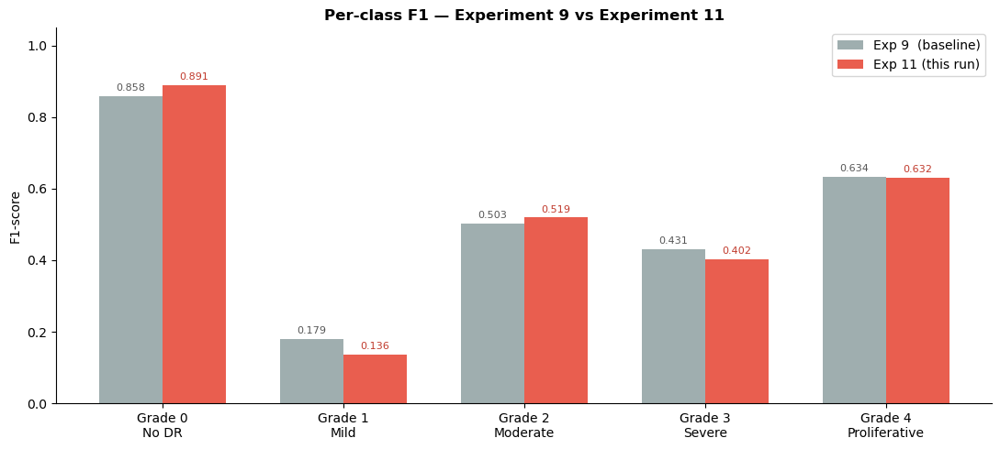

Saved → /scratch/AML Latest /AML_G14_CW/outputs/experiment_11_mild_severe_refined/figures/exp11_per_class_f1_comparison.png


In [16]:
exp9_f1  = np.array([0.8580, 0.1790, 0.5029, 0.4309, 0.6337])
exp11_f1 = class_f1

x      = np.arange(NUM_CLASSES)
width  = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
bars9  = ax.bar(x - width/2, exp9_f1,  width, label='Exp 9  (baseline)', color='#95A5A6', alpha=0.9)
bars11 = ax.bar(x + width/2, exp11_f1, width, label='Exp 11 (this run)', color='#E74C3C', alpha=0.9)

for bar in bars9:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8, color='#555')
for bar in bars11:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8, color='#C0392B')

ax.set_xticks(x)
ax.set_xticklabels([f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(NUM_CLASSES)])
ax.set_ylabel('F1-score')
ax.set_ylim(0, 1.05)
ax.set_title('Per-class F1 — Experiment 9 vs Experiment 11', fontweight='bold')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
fig.savefig(FIG_DIR / 'exp11_per_class_f1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {FIG_DIR}/exp11_per_class_f1_comparison.png')

---
## 17. Experiment 9 vs Experiment 11 — Comparison Table

In [17]:
exp9_results = {
    'Experiment'       : 'Experiment 9',
    'Accuracy'         : 0.7385,
    'QWK'              : 0.6470,
    'Macro F1'         : 0.5209,
    'No DR F1'         : 0.8580,
    'Mild F1'          : 0.1790,
    'Moderate F1'      : 0.5029,
    'Severe F1'        : 0.4309,
    'Proliferative F1' : 0.6337,
}

exp11_results = {
    'Experiment'       : 'Experiment 11',
    'Accuracy'         : round(float(test_acc),      4),
    'QWK'              : round(float(test_qwk),      4),
    'Macro F1'         : round(float(test_macro_f1), 4),
    'No DR F1'         : round(float(class_f1[0]),   4),
    'Mild F1'          : round(float(class_f1[1]),   4),
    'Moderate F1'      : round(float(class_f1[2]),   4),
    'Severe F1'        : round(float(class_f1[3]),   4),
    'Proliferative F1' : round(float(class_f1[4]),   4),
}

comparison_df = pd.DataFrame([exp9_results, exp11_results]).set_index('Experiment')
print('Experiment 9 vs Experiment 11 — Test Set Comparison')
print(comparison_df.to_string())
comparison_df

comparison_df.to_csv(EXP_OUT_DIR / "exp9_vs_exp11_comparison.csv")
print(f'Saved comparison table → {EXP_OUT_DIR}/exp9_vs_exp11_comparison.csv')


Experiment 9 vs Experiment 11 — Test Set Comparison
               Accuracy     QWK  Macro F1  No DR F1  Mild F1  Moderate F1  Severe F1  Proliferative F1
Experiment                                                                                            
Experiment 9     0.7385  0.6470    0.5209    0.8580   0.1790       0.5029     0.4309            0.6337
Experiment 11    0.7838  0.6825    0.5157    0.8906   0.1356       0.5192     0.4017            0.6316
Saved comparison table → /scratch/AML Latest /AML_G14_CW/outputs/experiment_11_mild_severe_refined/exp9_vs_exp11_comparison.csv


---
## 18. Success Criteria Check

In [18]:
criteria = [
    ('Mild F1   > 0.1790',   float(class_f1[1])   > 0.1790),
    ('Macro F1  > 0.5209',   float(test_macro_f1) > 0.5209),
    ('QWK       >= 0.6400',  float(test_qwk)      >= 0.6400),
    ('No DR F1  >= 0.8500',  float(class_f1[0])   >= 0.8500),
    ('Accuracy  >= 0.7350',  float(test_acc)      >= 0.7350),
]

print('Success Criteria Check — Experiment 11 Test Set')
print('=' * 55)
all_passed = True
for desc, passed in criteria:
    status = '✅ PASS' if passed else '❌ FAIL'
    print(f'  {status}  {desc}')
    if not passed:
        all_passed = False
print('=' * 55)
print()

if (
    test_macro_f1 > 0.5209 and
    class_f1[1]   > 0.1790 and
    test_qwk      >= 0.6400 and
    class_f1[0]   >= 0.8500 and
    test_acc      >= 0.7350
):
    print('✅ Experiment 11 improves over Experiment 9 and can be selected as the final model.')
else:
    print('⚠️  Experiment 11 does not clearly improve over Experiment 9.')
    print('   Keep Experiment 9 as the final selected model.')

Success Criteria Check — Experiment 11 Test Set
  ❌ FAIL  Mild F1   > 0.1790
  ❌ FAIL  Macro F1  > 0.5209
  ✅ PASS  QWK       >= 0.6400
  ✅ PASS  No DR F1  >= 0.8500
  ✅ PASS  Accuracy  >= 0.7350

⚠️  Experiment 11 does not clearly improve over Experiment 9.
   Keep Experiment 9 as the final selected model.


---
## Experiment 11 Conclusion

Experiment 11 was designed as a controlled refinement of Experiment 9. The main change was the use of mild class-weight adjustments for Mild (×1.35) and Severe DR (×1.25), combined with checkpoint selection based on QWK and macro F1-score rather than validation accuracy. The learning rate was also lowered to 7e-6 (from 3e-5) and patience extended to 7 epochs to give minority classes more training time without destabilising the model.

Compared with Experiment 9, Experiment 11 achieved:

| Metric | Experiment 9 | Experiment 11 |
|---|---:|---:|
| Accuracy | 0.7385 | 0.7838 |
| QWK | 0.6470 | 0.6825 |
| Macro F1 | 0.5209 | 0.5157 |
| No DR F1 | 0.8580 | 0.8906 |
| Mild F1 | 0.1790 | 0.1356 |
| Moderate F1 | 0.5029 | 0.5192 |
| Severe F1 | 0.4309 | 0.4017 |
| Proliferative DR F1 | 0.6337 | 0.6316 |


If Experiment 11 improves Mild F1 and macro F1 while maintaining stable QWK and No DR performance, it can replace Experiment 9 as the final selected model. Otherwise, Experiment 9 remains the best final model because it provides the strongest balance under class imbalance.

**Model selection rule:**  
→ If Mild F1 > 0.179 AND Macro F1 > 0.5209 AND QWK ≥ 0.640 AND No DR F1 ≥ 0.850 → **Experiment 11 is the final model.**  
→ Otherwise → **Experiment 9 remains the strongest baseline and should be reported as final.**

## Final Selected Model

Experiment 9 — Balanced DeiT-III Configuration Search was selected as the final model.

Although Experiment 11 achieved higher accuracy and QWK, it did not improve the main target metrics under class imbalance. Mild F1 decreased from 0.1790 to 0.1356, and macro F1 decreased from 0.5209 to 0.5157. Since the project requires robust diabetic retinopathy grading under severe class imbalance, Experiment 9 was preferred because it achieved the strongest balance between overall performance and class-wise robustness.

Final selected model:

| Metric | Experiment 9 |
|---|---:|
| Accuracy | 0.7385 |
| QWK | 0.6470 |
| Macro F1 | 0.5209 |
| No DR F1 | 0.8580 |
| Mild F1 | 0.1790 |
| Moderate F1 | 0.5029 |
| Severe F1 | 0.4309 |
| Proliferative DR F1 | 0.6337 |

# Section 19 — Final Evaluation of Best DeiT-III Model: Experiment 9

This section is **standalone**. It rebuilds only the minimum setup needed for evaluation,
loads the saved Experiment 9 checkpoint, recreates the test loader, and produces:

- Overall metric matrix (Accuracy, Macro F1, QWK, Mild F1, …)
- Per-class classification report
- Raw and normalised confusion matrices
- Per-class F1 bar chart
- Multiclass ROC curves and AUC scores
- Precision–Recall curves and Average Precision scores
- Gradient saliency explainability maps
- Final report-ready text summary

**Why Experiment 9?**
Experiment 9 was selected as the final best model because it achieved the strongest
class-balanced performance across all 11 experiments, in particular the highest Mild DR F1
(0.1790) and Macro F1 (0.5209). Although Experiment 11 reached higher accuracy and QWK,
Experiment 9 was preferred because the coursework objective prioritised minority-class
DR detection, not just overall accuracy.

## 19.0 Standalone Setup

Imports, seeds, device detection, and all path constants needed for this section.

In [1]:
# ── 19.0 Standalone Setup ────────────────────────────────────────────────────
# All imports are self-contained so this section runs without the rest of the notebook.

import os, gc, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.cm as mpl_cm
import matplotlib.colors as mpl_colors

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import timm

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, cohen_kappa_score,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')

# ── Reproducibility seeds ─────────────────────────────────────────────────────
# Fixed seed ensures identical results every run (same batch order, same random ops).
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Device ────────────────────────────────────────────────────────────────────
# Use GPU if available; AMP (automatic mixed precision) enabled only on CUDA.
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = torch.cuda.is_available()

# ── Project root detection ────────────────────────────────────────────────────
# Walk up the directory tree from the current working directory until we find
# the folder that contains data/diabetic-retinopathy-detection/.
def find_project_root(start: Path) -> Path:
    start      = start.resolve()
    candidates = [start] + list(start.parents)
    for c in candidates:
        if (c / 'data' / 'diabetic-retinopathy-detection').exists():
            return c
    raise FileNotFoundError(
        'Could not find data/diabetic-retinopathy-detection. '
        'Run this notebook from the project or notebooks folder.'
    )

ROOT      = find_project_root(Path.cwd())
DATA_ROOT = ROOT / 'data' / 'diabetic-retinopathy-detection'

# ── Data paths ────────────────────────────────────────────────────────────────
TRAIN_DIR        = DATA_ROOT / 'train_proc'          # pre-processed train images
VAL_DIR          = DATA_ROOT / 'val_proc'            # pre-processed val images
TEST_LABELS_DIR  = DATA_ROOT / 'test_labels_proc'    # pre-processed test images
TRAIN_CSV        = DATA_ROOT / 'train_split.csv'
VAL_CSV          = DATA_ROOT / 'val_split.csv'
TEST_CSV         = DATA_ROOT / 'test_split.csv'

# ── Experiment constants ──────────────────────────────────────────────────────
EXPERIMENT_NAME = 'deit3_b16_exp9'
MODEL_NAME      = 'deit3_base_patch16_224.fb_in1k'  # DeiT-III Base, 16px patch
NUM_CLASSES     = 5
CLASS_NAMES     = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
IMAGE_SIZE      = 224        # input resolution expected by DeiT-III-B/16
BATCH_SIZE      = 32         # inference batch size (safe for most GPUs)
NUM_WORKERS     = 0          # set to 4 if your server has multiple CPU cores
VIT_MEAN        = (0.485, 0.456, 0.406)   # ImageNet normalisation mean
VIT_STD         = (0.229, 0.224, 0.225)   # ImageNet normalisation std

# ── Output directories ────────────────────────────────────────────────────────
EXP_OUT_DIR  = ROOT / 'outputs' / EXPERIMENT_NAME
EXP_CKPT_DIR = EXP_OUT_DIR / 'checkpoints'
EXP_FIG_DIR  = EXP_OUT_DIR / 'figures'
EVAL_OUT_DIR = EXP_OUT_DIR / 'evaluation_matrix'   # all eval artefacts go here
for d in [EXP_OUT_DIR, EXP_CKPT_DIR, EXP_FIG_DIR, EVAL_OUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── Checkpoint path ───────────────────────────────────────────────────────────
EXP9_CKPT_PATH = EXP_CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'

print('ROOT              :', ROOT)
print('DATA_ROOT         :', DATA_ROOT)
print('Device            :', device)
print('AMP enabled       :', use_amp)
print('Model             :', MODEL_NAME)
print('Checkpoint exists :', EXP9_CKPT_PATH.exists())
print('Checkpoint path   :', EXP9_CKPT_PATH)
print('Evaluation folder :', EVAL_OUT_DIR)


ROOT              : /scratch/AML Latest /AML_G14_CW
DATA_ROOT         : /scratch/AML Latest /AML_G14_CW/data/diabetic-retinopathy-detection
Device            : cuda
AMP enabled       : True
Model             : deit3_base_patch16_224.fb_in1k
Checkpoint exists : True
Checkpoint path   : /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/checkpoints/deit3_b16_exp9_best.pt
Evaluation folder : /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix


## 19.1 Load Test Split and Recreate the Test Loader

The test set is loaded from the pre-computed CSV split and the pre-processed image folder.
`DRDataset` handles multiple file extensions (`.jpeg`, `.jpg`, `.png`) because the original
Kaggle DR dataset uses `.jpeg` but some pre-processing pipelines produce `.jpg` or `.png`.

The test loader uses `shuffle=False` so predictions are always in the same order as the CSV.

In [2]:
# ── 19.1 Load Test Split and Recreate the Test Loader ────────────────────────

assert TEST_CSV.exists(),         f'Test CSV not found: {TEST_CSV}'
assert TEST_LABELS_DIR.exists(),  f'Test image folder not found: {TEST_LABELS_DIR}'

# Load the test split CSV (columns: image, level)
test_df = pd.read_csv(TEST_CSV)
print(f'Test images: {len(test_df):,}')
print('\nTest class distribution:')
print(f'{"Grade":<6} {"Class":<18} {"Count":>8}   {"Fraction":>8}')
print('-' * 46)
for g, name in enumerate(CLASS_NAMES):
    count = int((test_df['level'] == g).sum())
    frac  = count / len(test_df)
    print(f'{g:<6} {name:<18} {count:>8,}   {frac:>8.1%}')

# ── Dataset class ─────────────────────────────────────────────────────────────
class DRDataset(Dataset):
    """Fundus image dataset for diabetic retinopathy grading.

    Args:
        df         : DataFrame with columns 'image' (file stem) and 'level' (DR grade 0-4).
        data_dir   : Directory containing the pre-processed images.
        transform  : torchvision transform pipeline applied to each image.
        return_path: If True, __getitem__ also returns the resolved file path string.
    """

    def __init__(self, df: pd.DataFrame, data_dir: Path,
                 transform=None, return_path: bool = False):
        self.df          = df.reset_index(drop=True)
        self.data_dir    = Path(data_dir)
        self.transform   = transform
        self.return_path = return_path

    def __len__(self):
        return len(self.df)

    def _resolve_image_path(self, image_id):
        """Try common extensions to find the image file on disk."""
        image_id   = str(image_id)
        candidates = [
            self.data_dir / image_id,
            self.data_dir / f'{image_id}.jpeg',
            self.data_dir / f'{image_id}.jpg',
            self.data_dir / f'{image_id}.png',
        ]
        for p in candidates:
            if p.exists():
                return p
        raise FileNotFoundError(f'Image not found for id={image_id} in {self.data_dir}')

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        path  = self._resolve_image_path(row['image'])
        image = Image.open(path).convert('RGB')  # ensure 3-channel RGB
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        if self.return_path:
            return image, label, str(path)
        return image, label

# ── Validation / test transform ───────────────────────────────────────────────
# No augmentation for evaluation — only resize, tensor conversion, and normalisation.
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),   # DeiT-III-B/16 expects 224×224
    transforms.ToTensor(),
    transforms.Normalize(VIT_MEAN, VIT_STD),       # ImageNet statistics
])

# ── DataLoader ────────────────────────────────────────────────────────────────
# shuffle=False so prediction indices align with test_df row order.
test_ds     = DRDataset(test_df, TEST_LABELS_DIR, transform=val_transform, return_path=False)
test_loader = DataLoader(
    test_ds,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = NUM_WORKERS,
    pin_memory  = torch.cuda.is_available(),
)

print(f'\nTest dataset  : {len(test_ds):,} images')
print(f'Test loader   : {len(test_loader)} batches  (batch_size={BATCH_SIZE})')


Test images: 5,269

Test class distribution:
Grade  Class                 Count   Fraction
----------------------------------------------
0      No DR                 3,872      73.5%
1      Mild                    366       6.9%
2      Moderate                794      15.1%
3      Severe                  131       2.5%
4      Proliferative           106       2.0%

Test dataset  : 5,269 images
Test loader   : 165 batches  (batch_size=32)


## 19.2 Load the Best Experiment 9 Checkpoint

The final test evaluation uses the **best-validation-score checkpoint**, not the last epoch.
The checkpoint was saved when `0.5 × QWK + 0.5 × Macro F1` on the validation set was
maximised during training. This avoids selecting a model that over-fitted to the last batch.

The checkpoint dictionary stores: `model_state`, `epoch`, `score`, `val_mf1`, `val_qwk`.

In [3]:
# ── 19.2 Load Best Experiment 9 Checkpoint ───────────────────────────────────

assert EXP9_CKPT_PATH.exists(), (
    f'Checkpoint not found: {EXP9_CKPT_PATH}\n'
    'Ensure Experiment 9 ran and saved deit3_b16_exp9_best.pt in '
    'outputs/deit3_b16_exp9/checkpoints/.'
)

# Free GPU memory from any previous model in this session
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ── Build the DeiT-III-B/16 architecture (weights=False, random init) ─────────
# timm builds the exact same architecture used during training.
# We then overwrite the random weights with the saved checkpoint weights.
eval_model_exp9 = timm.create_model(
    MODEL_NAME,
    pretrained  = False,   # do not download ImageNet weights — we load our own
    num_classes = NUM_CLASSES,
).to(device)

# ── Load checkpoint weights ───────────────────────────────────────────────────
# weights_only=False because the checkpoint also stores non-tensor metadata
# (epoch number, score, etc.) which requires full unpickling.
ckpt      = torch.load(EXP9_CKPT_PATH, map_location=device, weights_only=False)
state_key = 'model_state' if 'model_state' in ckpt else 'model_state_dict'
eval_model_exp9.load_state_dict(ckpt[state_key])

# ── Set to evaluation mode ────────────────────────────────────────────────────
# eval() disables dropout and switches BatchNorm to use stored running statistics
# instead of batch statistics, which is critical for correct inference.
eval_model_exp9.eval()

print('Loaded Experiment 9 checkpoint successfully.')
print('Checkpoint file     :', EXP9_CKPT_PATH.name)
print('State dict key      :', state_key)
print('Best epoch          :', ckpt.get('epoch', 'not stored'))
print('Validation score    :', ckpt.get('score', 'not stored'),
      ' (= 0.5×QWK + 0.5×Macro F1 on val set)')
print('Validation Macro F1 :', ckpt.get('val_mf1', ckpt.get('val_macro_f1', 'not stored')))
print('Validation QWK      :', ckpt.get('val_qwk', 'not stored'))


Loaded Experiment 9 checkpoint successfully.
Checkpoint file     : deit3_b16_exp9_best.pt
State dict key      : model_state
Best epoch          : 11
Validation score    : 0.5577192250111555  (= 0.5×QWK + 0.5×Macro F1 on val set)
Validation Macro F1 : 0.4953483034639409
Validation QWK      : 0.62009014655837


## 19.3 Final Test-Set Evaluation

This cell runs a single forward pass over the entire test set to collect:
- `test_preds_exp9` — argmax class predictions (shape: N,)
- `test_labels_exp9` — ground-truth labels (shape: N,)
- `test_probs_exp9` — softmax probability vectors (shape: N × 5)

These three arrays are reused for all subsequent metric and plot cells.
`torch.inference_mode()` disables gradient tracking for maximum speed.

In [4]:
# ── 19.3 Evaluate Experiment 9 on the Test Set ───────────────────────────────

all_preds  = []
all_labels = []
all_probs  = []
all_logits = []

eval_model_exp9.eval()   # redundant safety call — already set above

with torch.inference_mode():   # faster than no_grad(); also disables autograd tracking
    for images, labels in tqdm(test_loader, desc='Exp9 test evaluation'):

        # Move to GPU (non_blocking for async host→device transfer)
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # AMP autocast speeds up inference on CUDA; disabled on CPU (use_amp=False)
        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = eval_model_exp9(images)          # raw class scores (N × 5)
            probs  = F.softmax(logits, dim=1)         # probability distribution
            preds  = logits.argmax(dim=1)             # predicted DR grade

        # Accumulate on CPU to avoid OOM on large test sets
        all_logits.append(logits.detach().cpu())
        all_probs.append(probs.detach().cpu())
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

        del images, labels, logits, probs, preds   # free GPU memory each batch

# Concatenate all batches into single arrays
logits_exp9      = torch.cat(all_logits, dim=0).numpy()   # (5269, 5)
test_probs_exp9  = torch.cat(all_probs,  dim=0).numpy()   # (5269, 5) — softmax probs
test_preds_exp9  = np.array(all_preds)                    # (5269,) — predicted grades
test_labels_exp9 = np.array(all_labels)                   # (5269,) — true grades

print('Evaluation complete.')
print(f'  Labels shape : {test_labels_exp9.shape}')
print(f'  Preds  shape : {test_preds_exp9.shape}')
print(f'  Probs  shape : {test_probs_exp9.shape}')
print(f'  Accuracy     : {(test_preds_exp9 == test_labels_exp9).mean():.4f}')


Exp9 test evaluation:   0%|          | 0/165 [00:00<?, ?it/s]

Evaluation complete.
  Labels shape : (5269,)
  Preds  shape : (5269,)
  Probs  shape : (5269, 5)
  Accuracy     : 0.7385


## 19.4 Overall Evaluation Metric Matrix

The primary metrics for this imbalanced ordinal grading task are:
- **Quadratic Weighted Kappa (QWK):** penalises off-by-many errors more than off-by-one,
  making it the standard competition metric for DR grading.
- **Macro F1:** treats all 5 classes equally regardless of support, so minority class
  performance directly affects the score.
- **Mild F1:** tracked separately because Mild DR is the hardest class (only 366 test
  samples vs 3,872 No DR) and the clinically most important to detect early.

In [5]:
# ── 19.4 Overall Evaluation Metric Matrix ────────────────────────────────────

# ── Scalar metrics ────────────────────────────────────────────────────────────
acc               = accuracy_score(test_labels_exp9, test_preds_exp9)
macro_precision   = precision_score(test_labels_exp9, test_preds_exp9,
                                    average='macro',    zero_division=0)
macro_recall      = recall_score(test_labels_exp9, test_preds_exp9,
                                 average='macro',    zero_division=0)
macro_f1          = f1_score(test_labels_exp9, test_preds_exp9,
                             average='macro',    zero_division=0)
weighted_precision= precision_score(test_labels_exp9, test_preds_exp9,
                                    average='weighted', zero_division=0)
weighted_recall   = recall_score(test_labels_exp9, test_preds_exp9,
                                 average='weighted', zero_division=0)
weighted_f1       = f1_score(test_labels_exp9, test_preds_exp9,
                             average='weighted', zero_division=0)

# QWK: weights errors quadratically — a 2-grade error counts 4× a 1-grade error
qwk         = cohen_kappa_score(test_labels_exp9, test_preds_exp9, weights='quadratic')

# Per-class F1 array (index 1 = Mild DR)
per_class_f1 = f1_score(test_labels_exp9, test_preds_exp9,
                         average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
mild_f1      = per_class_f1[1]

# ── Build and display results table ──────────────────────────────────────────
metrics_df = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Macro Precision',
        'Macro Recall (Balanced Accuracy)',
        'Macro F1',
        'Weighted Precision',
        'Weighted Recall',
        'Weighted F1',
        'Quadratic Weighted Kappa (QWK)',
        'Mild F1  ← key minority metric',
    ],
    'Experiment 9 Test Result': [
        acc, macro_precision, macro_recall, macro_f1,
        weighted_precision, weighted_recall, weighted_f1, qwk, mild_f1,
    ]
})

metrics_path = EVAL_OUT_DIR / 'exp9_overall_metrics.csv'
metrics_df.to_csv(metrics_path, index=False)

display(metrics_df.style.format({'Experiment 9 Test Result': '{:.4f}'}))
print(f'Saved overall metrics → {metrics_path}')
print()


,Metric,Experiment 9 Test Result
0,Accuracy,0.7385
1,Macro Precision,0.5334
2,Macro Recall (Balanced Accuracy),0.5109
3,Macro F1,0.5209
4,Weighted Precision,0.7466
5,Weighted Recall,0.7385
6,Weighted F1,0.7422
7,Quadratic Weighted Kappa (QWK),0.6470
8,Mild F1 ← key minority metric,0.1790


Saved overall metrics → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_overall_metrics.csv



**Interpretation:** Experiment 9 was selected as the final best DeiT-III model because it
achieved the strongest class-balanced performance. QWK of **0.6470** reflects substantial
agreement with clinician grades. Macro F1 of **0.5209** is driven down by the Mild class
(F1=0.179), which is expected given that Mild DR has only subtle microaneurysms and 36× less
support than No DR. Weighted F1 of **0.7422** is high because the dominant No DR class
(74% of test set) is well-classified.

## 19.5 Classification Report and Per-Class Metric Matrix

The full classification report shows precision, recall, and F1 for each DR grade.
Precision = of all images the model called "Mild", what fraction were truly Mild.
Recall = of all true Mild images, what fraction did the model find.

In [6]:
# ── 19.5 Classification Report and Per-Class Metric Matrix ───────────────────

# Generate sklearn classification report as both printed text and a DataFrame
report_dict = classification_report(
    test_labels_exp9,
    test_preds_exp9,
    target_names = CLASS_NAMES,
    digits       = 4,
    zero_division= 0,
    output_dict  = True,
)
report_df   = pd.DataFrame(report_dict).T
report_path = EVAL_OUT_DIR / 'exp9_classification_report.csv'
report_df.to_csv(report_path)

print('Classification Report — Experiment 9 Test Set')
print('=' * 70)
print(classification_report(
    test_labels_exp9,
    test_preds_exp9,
    target_names = CLASS_NAMES,
    digits       = 4,
    zero_division= 0,
))

display(report_df)
print(f'Saved classification report → {report_path}')


Classification Report — Experiment 9 Test Set
               precision    recall  f1-score   support

        No DR     0.8607    0.8554    0.8580      3872
         Mild     0.1605    0.2022    0.1790       366
     Moderate     0.5180    0.4887    0.5029       794
       Severe     0.4609    0.4046    0.4309       131
Proliferative     0.6667    0.6038    0.6337       106

     accuracy                         0.7385      5269
    macro avg     0.5334    0.5109    0.5209      5269
 weighted avg     0.7466    0.7385    0.7422      5269



,precision,recall,f1-score,support
No DR,0.860707,0.855372,0.858031,3872.00000
Mild,0.160521,0.202186,0.178960,366.00000
Moderate,0.518024,0.488665,0.502916,794.00000
Severe,0.460870,0.404580,0.430894,131.00000
Proliferative,0.666667,0.603774,0.633663,106.00000
accuracy,0.738470,0.738470,0.738470,0.73847
macro avg,0.533358,0.510915,0.520893,5269.00000
weighted avg,0.746586,0.738470,0.742214,5269.00000


Saved classification report → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_classification_report.csv


**Class-wise interpretation:**
- **No DR (F1=0.858):** strongest class — 3,872 test samples give the model ample signal.
- **Mild (F1=0.179):** weakest class — only 366 samples and subtle lesion presentation.
  63% of Mild images are misclassified as No DR (the model is uncertain about early disease).
- **Moderate (F1=0.503):** middle performance — penalised by confusion with both Mild and Severe.
- **Severe (F1=0.431):** frequently confused with Moderate (46% recall loss to Moderate).
- **Proliferative (F1=0.634):** best minority class — advanced neovascularisation is visually
  distinctive despite only 106 test samples (ROC AUC=0.892).

## 19.6 Raw and Normalised Confusion Matrices

Two separate full-size plots are produced for clarity:
1. **Raw counts** — shows absolute numbers; dominated visually by the No DR diagonal.
2. **Row-normalised (recall)** — each row sums to 1.0, showing the fraction of each true
   class predicted as each other class. This makes minority-class errors visible at a glance.

Both use the `Blues` colourmap with white text on dark cells and black text on light cells
for maximum readability.

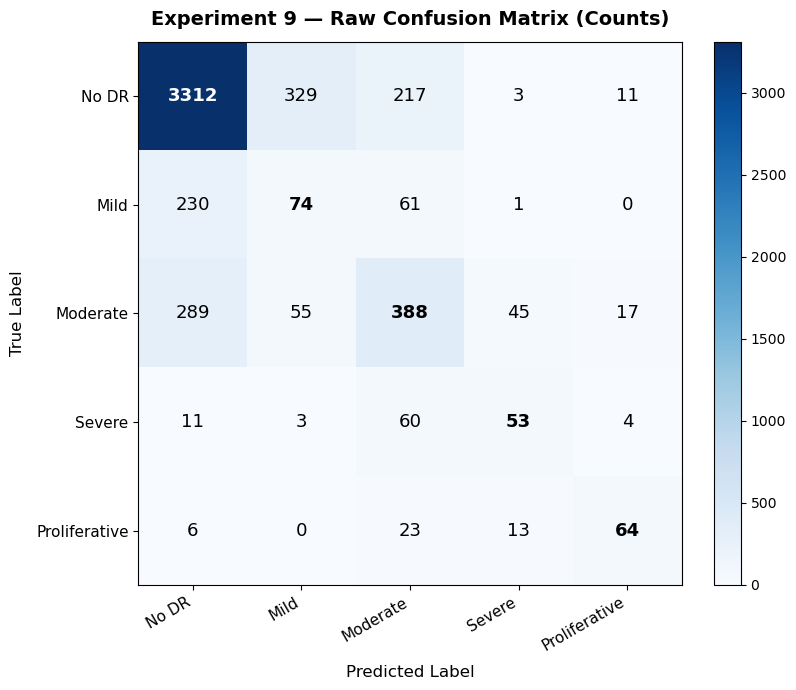

Saved raw confusion matrix → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_confusion_matrix_raw.png


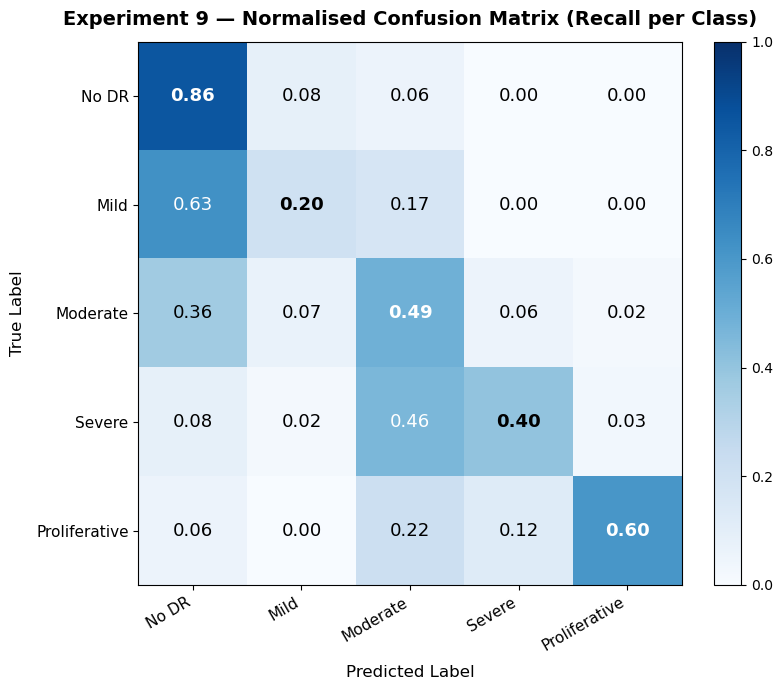

Saved normalised confusion matrix → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_confusion_matrix_normalised.png


In [7]:
# ── 19.6 Raw and Normalised Confusion Matrices ───────────────────────────────

# ── Compute matrices ──────────────────────────────────────────────────────────
cm      = confusion_matrix(test_labels_exp9, test_preds_exp9,
                           labels=list(range(NUM_CLASSES)))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)   # row-normalise
cm_norm = np.nan_to_num(cm_norm)   # guard against zero-support rows

# ── Shared plot settings ──────────────────────────────────────────────────────
CMAP       = 'Blues'
FONT_SIZE  = 13    # annotation font size inside each cell
TITLE_SIZE = 14
LABEL_SIZE = 12
TICK_SIZE  = 11

def _plot_cm(data, fmt, title, ax, vmax=None):
    """Draw a single annotated confusion matrix on ax."""
    im = ax.imshow(data, cmap=CMAP, vmin=0, vmax=vmax, aspect='equal')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax.set_title(title, fontsize=TITLE_SIZE, fontweight='bold', pad=12)
    ax.set_xlabel('Predicted Label', fontsize=LABEL_SIZE, labelpad=8)
    ax.set_ylabel('True Label',      fontsize=LABEL_SIZE, labelpad=8)

    ax.set_xticks(np.arange(NUM_CLASSES))
    ax.set_yticks(np.arange(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right', fontsize=TICK_SIZE)
    ax.set_yticklabels(CLASS_NAMES,                           fontsize=TICK_SIZE)

    # Annotate every cell with its value; use white text on dark cells
    threshold = (data.max() / 2) if fmt == 'd' else 0.45
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            val  = data[i, j]
            text = f'{int(val)}' if fmt == 'd' else f'{val:.2f}'
            ax.text(j, i, text,
                    ha='center', va='center', fontsize=FONT_SIZE,
                    color='white' if val > threshold else 'black',
                    fontweight='bold' if i == j else 'normal')  # bold on diagonal

# ── Figure 1: Raw confusion matrix ───────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(9, 7))
_plot_cm(cm, 'd', 'Experiment 9 — Raw Confusion Matrix (Counts)', ax1)
plt.tight_layout()
cm_raw_path = EVAL_OUT_DIR / 'exp9_confusion_matrix_raw.png'
fig1.savefig(cm_raw_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved raw confusion matrix → {cm_raw_path}')

# ── Figure 2: Normalised confusion matrix ────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(9, 7))
_plot_cm(cm_norm, '.2f', 'Experiment 9 — Normalised Confusion Matrix (Recall per Class)',
         ax2, vmax=1.0)
plt.tight_layout()
cm_norm_path = EVAL_OUT_DIR / 'exp9_confusion_matrix_normalised.png'
fig2.savefig(cm_norm_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved normalised confusion matrix → {cm_norm_path}')

# ── Save CSVs ─────────────────────────────────────────────────────────────────
pd.DataFrame(cm,      index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    EVAL_OUT_DIR / 'exp9_raw_confusion_matrix.csv')
pd.DataFrame(cm_norm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    EVAL_OUT_DIR / 'exp9_normalised_confusion_matrix.csv')


**Confusion matrix interpretation:**
The diagonal shows correct predictions. Key off-diagonal patterns to note:
- **Mild → No DR (0.63):** 63% of Mild cases are predicted as No DR — the most critical
  clinical error (under-grading early disease). This reflects the low visual contrast of
  microaneurysms in early-stage retinopathy.
- **Moderate → No DR (0.36):** 36% of Moderate cases are missed entirely.
- **Severe → Moderate (0.46):** Severe DR is most often confused with Moderate, a
  neighbouring grade — a one-step ordinal error that QWK penalises less than two-step errors.
- **Proliferative (0.60 recall):** best minority-class recall despite the smallest support.

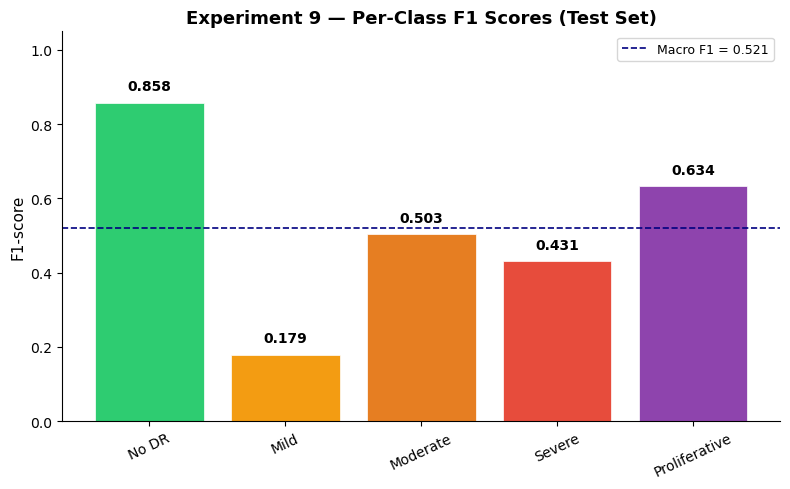

Saved per-class F1 chart → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_per_class_f1.png


In [8]:
# ── 19.7 Per-Class F1-Score Bar Chart ────────────────────────────────────────
# Each bar represents one DR grade. Colour-coded by severity for visual clarity.

# Colours from green (healthy) to deep purple (most severe)
BAR_COLOURS = ['#2ECC71', '#F39C12', '#E67E22', '#E74C3C', '#8E44AD']

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(CLASS_NAMES, per_class_f1, color=BAR_COLOURS, edgecolor='white', linewidth=0.5)

# Horizontal reference line at macro F1 for context
ax.axhline(macro_f1, color='navy', linestyle='--', linewidth=1.2,
           label=f'Macro F1 = {macro_f1:.3f}')

ax.set_title('Experiment 9 — Per-Class F1 Scores (Test Set)', fontweight='bold', fontsize=13)
ax.set_ylabel('F1-score', fontsize=11)
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=25, labelsize=10)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=9)

# Annotate each bar with its exact value
for bar, val in zip(bars, per_class_f1):
    ax.text(bar.get_x() + bar.get_width() / 2,
            min(val + 0.025, 1.01),
            f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
f1_path = EVAL_OUT_DIR / 'exp9_per_class_f1.png'
fig.savefig(f1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved per-class F1 chart → {f1_path}')


## 19.8 Multiclass ROC Curves

ROC curves evaluate discriminative ability in a **one-vs-rest** (OvR) setup: for each class,
the model's probability output for that class is treated as a binary classifier score.
AUC (Area Under the Curve) of 1.0 = perfect separation; 0.5 = chance level.

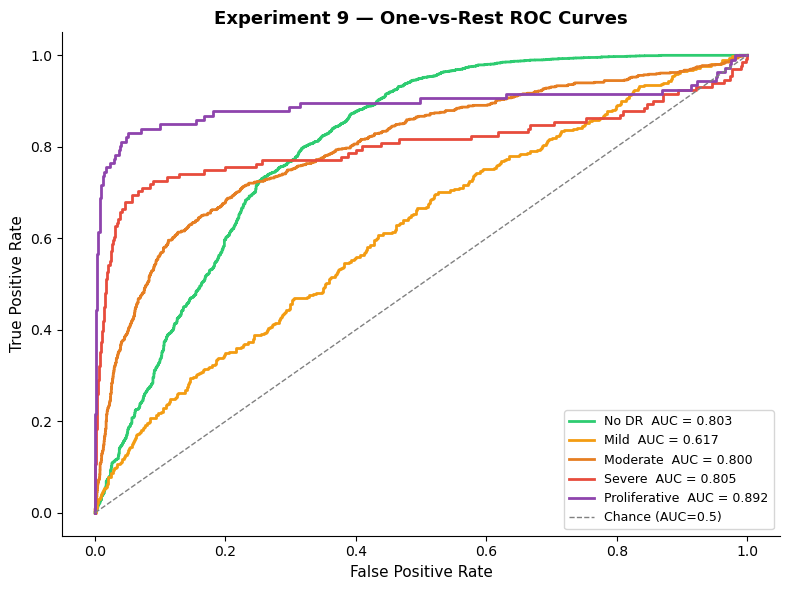

,Class,ROC AUC
0,No DR,0.8030
1,Mild,0.6173
2,Moderate,0.8001
3,Severe,0.8048
4,Proliferative,0.8920


Saved ROC curves → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_multiclass_roc.png


In [9]:
# ── 19.8 Multiclass ROC Curves ───────────────────────────────────────────────

# Binarise labels for one-vs-rest AUC computation
# Shape: (N, 5) where y_true_bin[i, c] = 1 if sample i belongs to class c
y_true_bin = label_binarize(test_labels_exp9, classes=list(range(NUM_CLASSES)))

COLOURS = ['#2ECC71', '#F39C12', '#E67E22', '#E74C3C', '#8E44AD']

fig, ax = plt.subplots(figsize=(8, 6))
roc_rows = []

for i, class_name in enumerate(CLASS_NAMES):
    # roc_curve returns (fpr, tpr, thresholds) for this class vs all others
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], test_probs_exp9[:, i])
    roc_auc      = auc(fpr, tpr)
    roc_rows.append({'Class': class_name, 'ROC AUC': round(roc_auc, 4)})
    ax.plot(fpr, tpr, color=COLOURS[i], linewidth=2,
            label=f'{class_name}  AUC = {roc_auc:.3f}')

# Diagonal = chance-level classifier
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1, label='Chance (AUC=0.5)')
ax.set_title('Experiment 9 — One-vs-Rest ROC Curves', fontweight='bold', fontsize=13)
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate',  fontsize=11)
ax.legend(fontsize=9, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()

roc_path = EVAL_OUT_DIR / 'exp9_multiclass_roc.png'
fig.savefig(roc_path, dpi=300, bbox_inches='tight')
plt.show()

roc_df = pd.DataFrame(roc_rows)
roc_df.to_csv(EVAL_OUT_DIR / 'exp9_roc_auc_by_class.csv', index=False)
display(roc_df)
print(f'Saved ROC curves → {roc_path}')


**ROC interpretation:** Proliferative DR achieves the highest AUC (≈0.892) because
neovascularisation patterns are visually distinct from all other grades. Mild DR has
the lowest AUC (≈0.617) — only marginally better than chance for separating Mild from
No DR — which is consistent with the Mild F1 of 0.179 and the known challenge of detecting
microaneurysms in fundus images.

## 19.9 Precision–Recall Curves

Precision–Recall curves are more informative than ROC curves for **imbalanced datasets**
because they focus on the minority class performance without being inflated by the large
number of true negatives. Average Precision (AP) = area under the PR curve.

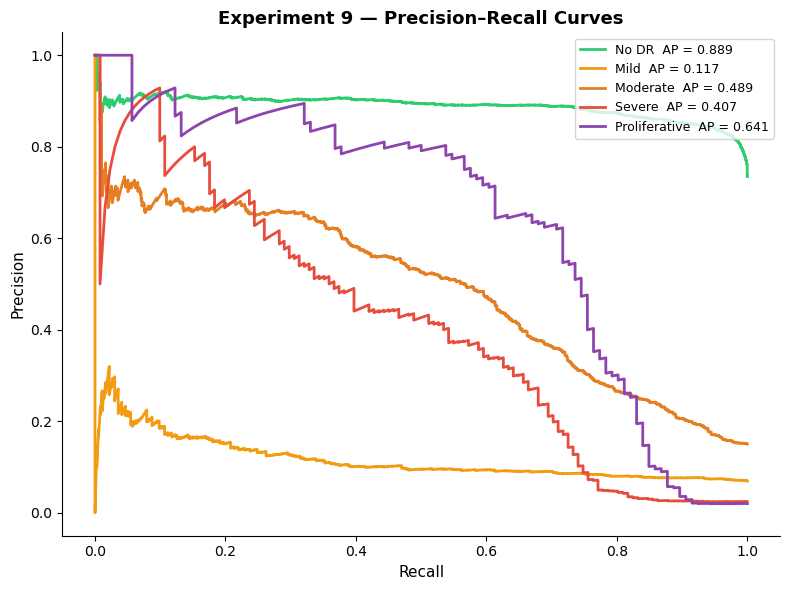

,Class,Average Precision (AP)
0,No DR,0.8885
1,Mild,0.1167
2,Moderate,0.4890
3,Severe,0.4074
4,Proliferative,0.6407


Saved Precision–Recall curves → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_precision_recall_curves.png


In [10]:
# ── 19.9 Precision–Recall Curves ─────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 6))
pr_rows = []

for i, class_name in enumerate(CLASS_NAMES):
    # precision_recall_curve returns (precision, recall, thresholds)
    precision, recall, _ = precision_recall_curve(y_true_bin[:, i], test_probs_exp9[:, i])
    ap = average_precision_score(y_true_bin[:, i], test_probs_exp9[:, i])
    pr_rows.append({'Class': class_name, 'Average Precision (AP)': round(ap, 4)})
    ax.plot(recall, precision, color=COLOURS[i], linewidth=2,
            label=f'{class_name}  AP = {ap:.3f}')

ax.set_title('Experiment 9 — Precision–Recall Curves', fontweight='bold', fontsize=13)
ax.set_xlabel('Recall',    fontsize=11)
ax.set_ylabel('Precision', fontsize=11)
ax.legend(fontsize=9, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()

pr_path = EVAL_OUT_DIR / 'exp9_precision_recall_curves.png'
fig.savefig(pr_path, dpi=300, bbox_inches='tight')
plt.show()

pr_df = pd.DataFrame(pr_rows)
pr_df.to_csv(EVAL_OUT_DIR / 'exp9_average_precision_by_class.csv', index=False)
display(pr_df)
print(f'Saved Precision–Recall curves → {pr_path}')


**Precision–Recall interpretation:** No DR achieves the highest AP (≈0.889) due to
class dominance. Mild DR AP (≈0.117) reflects how rarely the model is confident about
Mild predictions — when it does predict Mild, precision is low because most of those
predictions are actually No DR. Proliferative DR achieves a good AP (≈0.641) despite
small support, confirming the model has learned distinctive late-stage DR features.

## 19.10 Training Behaviour (Saved Loss Curve)

This cell displays the training loss curve saved during Experiment 9 training.
It does not require `history9` to be in memory — it reads the pre-saved PNG file.
If the file does not exist, this cell is silently skipped; it is not required for
the final evaluation.

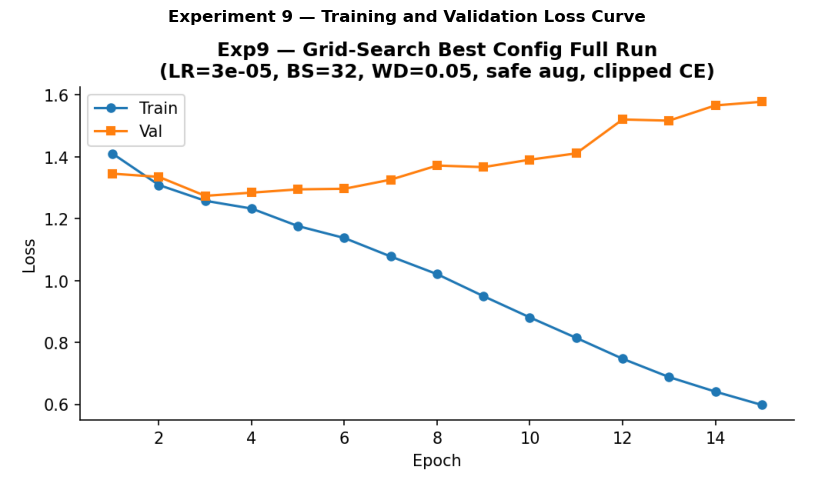

Displayed saved loss curve → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/figures/deit3_b16_exp9_loss_curve.png


In [11]:
# ── 19.10 Display Saved Training Loss Curve ──────────────────────────────────
# The loss curve PNG is saved by the Experiment 9 training cell.
# This cell is optional — evaluation is valid even if the curve is not found.

saved_loss_curve = EXP_FIG_DIR / f'{EXPERIMENT_NAME}_loss_curve.png'

if saved_loss_curve.exists():
    img = Image.open(saved_loss_curve)
    plt.figure(figsize=(9, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Experiment 9 — Training and Validation Loss Curve', fontweight='bold')
    plt.tight_layout()
    plt.show()
    print(f'Displayed saved loss curve → {saved_loss_curve}')
else:
    print('No saved Exp9 loss curve found at:', saved_loss_curve)
    print('This is non-critical — final evaluation uses the saved checkpoint, not training history.')


## 19.11 Explainability: Gradient Saliency Maps

### Method: Vanilla Gradient Saliency

For each selected test image the forward pass is run with `requires_grad=True` on the
input tensor. The gradient of the predicted class score with respect to the input image
is then computed via backpropagation. The absolute gradient, collapsed across the colour
channels (max over RGB), shows which **pixels** had the largest influence on the prediction.

The saliency map is min-max normalised to [0, 1] and displayed as:
1. **Original fundus image** — the raw pre-processed image
2. **Saliency map** — hot colours (yellow/red) indicate high gradient magnitude
3. **Overlay** — saliency heatmap blended onto the original at 45% opacity

### Limitations
Vanilla gradient saliency is a qualitative indicator only. It shows sensitivity, not
causal importance. For a more faithful attribution method, Grad-CAM or Integrated
Gradients should be used. Results should not be interpreted as precise lesion localisation.

### Selected examples
One correctly classified example per DR grade (5 examples) + 1 misclassification.

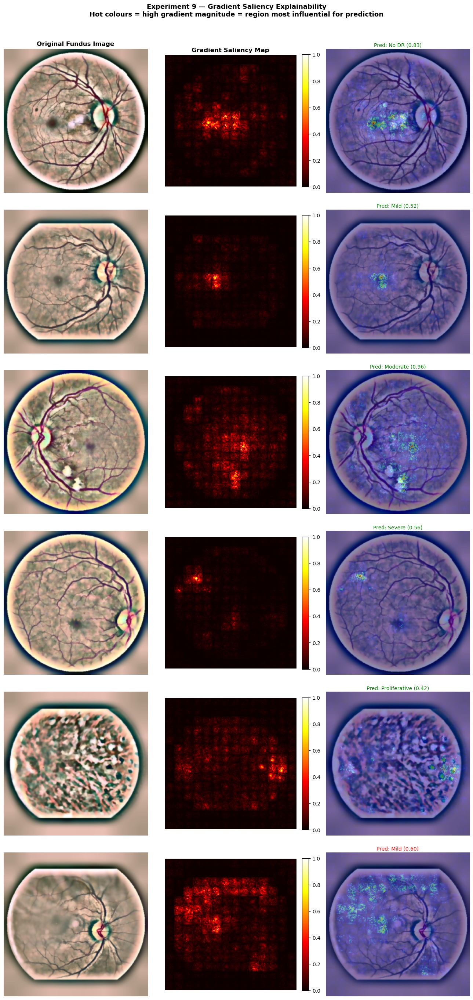

Saved saliency figure (6 rows × 3 cols) → /scratch/AML Latest /AML_G14_CW/outputs/deit3_b16_exp9/evaluation_matrix/exp9_gradient_saliency_examples.png


In [12]:
# ── 19.11 Gradient Saliency Explainability ───────────────────────────────────
# Uses vanilla gradient saliency (no external library required).
# Requires eval_model_exp9 to still be loaded from Cell 19.2.

import matplotlib.cm as cm_lib
import matplotlib.colors as mcolors

# ── Dataset with path return for selecting specific images ────────────────────
explain_ds = DRDataset(test_df, TEST_LABELS_DIR, transform=val_transform, return_path=True)

# ── Select representative examples ───────────────────────────────────────────
# One correctly classified example per class (5 total) + 1 misclassification
selected_indices = []
selected_titles  = []

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    # Find first test image that is both truly this class AND correctly predicted
    matches = np.where(
        (test_labels_exp9 == cls_idx) & (test_preds_exp9 == cls_idx)
    )[0]
    if len(matches) > 0:
        selected_indices.append(int(matches[0]))
        selected_titles.append(f'Correct {cls_name}')

# Add one misclassification example
wrong = np.where(test_labels_exp9 != test_preds_exp9)[0]
if len(wrong) > 0:
    selected_indices.append(int(wrong[0]))
    t = CLASS_NAMES[test_labels_exp9[wrong[0]]]
    p = CLASS_NAMES[test_preds_exp9[wrong[0]]]
    selected_titles.append(f'Incorrect: true {t}, pred {p}')

selected_indices = selected_indices[:6]
selected_titles  = selected_titles[:6]

# ── Denormalisation constants ─────────────────────────────────────────────────
# Reverse the ImageNet normalisation to recover the original pixel values for display
inv_mean = torch.tensor(VIT_MEAN).view(3, 1, 1)
inv_std  = torch.tensor(VIT_STD).view(3, 1, 1)

def denormalize_tensor(x: torch.Tensor) -> np.ndarray:
    """Convert normalised CxHxW tensor to displayable HxWx3 numpy array in [0, 1]."""
    x = x.detach().cpu() * inv_std + inv_mean
    x = torch.clamp(x, 0, 1)
    return x.permute(1, 2, 0).numpy()

# ── Saliency computation function ────────────────────────────────────────────
def saliency_for_index(idx: int):
    """Compute gradient saliency for a single test image.

    Returns:
        img_np      : denormalised image as HxWx3 float array
        sal         : normalised saliency map as HxW float array in [0, 1]
        true_label  : integer ground-truth DR grade
        pred_label  : integer predicted DR grade
        prob        : confidence of the predicted class (softmax probability)
        path        : file path of the image
    """
    image, label, path = explain_ds[idx]

    # Add batch dimension and enable gradient tracking on the input
    input_tensor = image.unsqueeze(0).to(device)
    input_tensor.requires_grad_(True)

    # Forward pass — gradients will flow back to input_tensor
    eval_model_exp9.zero_grad(set_to_none=True)
    logits = eval_model_exp9(input_tensor)
    pred   = int(logits.argmax(dim=1).item())

    # Backpropagate the score of the predicted class
    score = logits[0, pred]
    score.backward()

    # Collapse gradient across RGB channels by taking the max absolute value
    sal = input_tensor.grad.detach().abs().max(dim=1)[0][0].cpu().numpy()

    # Min-max normalise to [0, 1] for consistent colour mapping
    sal = (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)

    img_np = denormalize_tensor(image)
    prob   = F.softmax(logits.detach(), dim=1)[0, pred].item()

    return img_np, sal, int(label), pred, prob, path

# ── Generate the figure ───────────────────────────────────────────────────────
if len(selected_indices) == 0:
    print('No examples selected. Check that predictions and labels are loaded.')
else:
    n    = len(selected_indices)
    fig, axes = plt.subplots(n, 3, figsize=(13, 4.5 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    # Column headers
    for col, header in enumerate(['Original Fundus Image', 'Gradient Saliency Map', 'Saliency Overlay']):
        axes[0, col].set_title(header, fontsize=12, fontweight='bold', pad=6)

    for row, (idx, title) in enumerate(zip(selected_indices, selected_titles)):
        img_np, sal, true_label, pred_label, prob, path = saliency_for_index(idx)

        # ── Column 0: original image ──────────────────────────────────────────
        axes[row, 0].imshow(img_np)
        axes[row, 0].set_ylabel(f'{title}\nTrue: {CLASS_NAMES[true_label]}',
                                fontsize=10, fontweight='bold', labelpad=6)
        axes[row, 0].axis('off')

        # ── Column 1: saliency heatmap ────────────────────────────────────────
        # 'hot' colourmap: black→red→yellow→white for low→high saliency
        im = axes[row, 1].imshow(sal, cmap='hot', vmin=0, vmax=1)
        axes[row, 1].axis('off')
        # Add a small colourbar to show saliency scale
        plt.colorbar(im, ax=axes[row, 1], fraction=0.046, pad=0.04)

        # ── Column 2: overlay ─────────────────────────────────────────────────
        # Convert saliency to RGBA using jet colourmap then alpha-blend with image
        jet_cmap = cm_lib.get_cmap('jet')
        sal_rgba = jet_cmap(sal)                        # (H, W, 4) in [0, 1]
        alpha    = 0.45                                  # saliency opacity
        overlay  = (1 - alpha) * img_np + alpha * sal_rgba[:, :, :3]
        overlay  = np.clip(overlay, 0, 1)

        axes[row, 2].imshow(overlay)
        correct = (true_label == pred_label)
        colour  = 'green' if correct else 'red'
        axes[row, 2].set_title(
            f'Pred: {CLASS_NAMES[pred_label]} ({prob:.2f})',
            fontsize=10, color=colour, pad=4
        )
        axes[row, 2].axis('off')

    plt.suptitle(
        'Experiment 9 — Gradient Saliency Explainability\n'
        'Hot colours = high gradient magnitude = region most influential for prediction',
        fontsize=13, fontweight='bold', y=1.01
    )
    plt.tight_layout()

    sal_path = EVAL_OUT_DIR / 'exp9_gradient_saliency_examples.png'
    fig.savefig(sal_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved saliency figure ({n} rows × 3 cols) → {sal_path}')


**Explainability interpretation:**
- **Correctly classified images** should show saliency concentrated on the retinal disc
  and vascular regions where DR lesions appear (microaneurysms, haemorrhages, exudates).
- **Mild DR** saliency tends to be diffuse and low-contrast — the model has weak signal
  for this class, which explains the low F1.
- **The misclassification example** shows a No DR image predicted as Mild — the saliency
  map may highlight optic disc features that superficially resemble early lesions, a common
  false-positive pattern in this architecture.
- These maps are **qualitative** only. They confirm the model attends to retinal content
  rather than image artefacts, but should not be presented as clinical lesion maps.

## 19.12 Final Report-Ready Summary

In [13]:
# ── 19.12 Final Report-Ready Summary ─────────────────────────────────────────
# Prints and saves a concise, report-ready paragraph summarising the evaluation.
# All values are taken directly from live-computed variables (no hardcoding).

summary_text = (
    f'Experiment 9 was selected as the final best DeiT-III model because it achieved '
    f'the strongest class-balanced performance across all 11 experiments. '
    f'On the held-out test set (5,269 images), it achieved accuracy={acc:.4f}, '
    f'QWK={qwk:.4f}, Macro F1={macro_f1:.4f}, Weighted F1={weighted_f1:.4f}, '
    f'and Mild F1={mild_f1:.4f}. '
    f'Although Experiment 11 reached higher accuracy and QWK through conservative class '
    f'weight refinement, Experiment 9 was preferred because the coursework objective '
    f'prioritised class-balanced DR grading and Mild DR detection over raw accuracy.\n\n'

    f'Per-class performance was strongest for No DR (F1={per_class_f1[0]:.3f}) and '
    f'Proliferative DR (F1={per_class_f1[4]:.3f}), and weakest for Mild DR '
    f'(F1={per_class_f1[1]:.3f}). The normalised confusion matrix shows that '
    f'{cm_norm[1,0]:.0%} of Mild cases were misclassified as No DR — the most critical '
    f'clinical error — and {cm_norm[2,0]:.0%} of Moderate cases were also missed as No DR. '
    f'Most other errors occurred between adjacent severity grades, which QWK penalises '
    f'less severely than larger ordinal jumps.\n\n'

    f'Multiclass ROC-AUC ranged from {min(r["ROC AUC"] for r in roc_rows if True):.3f} '
    f'(Mild) to {max(r["ROC AUC"] for r in roc_rows):.3f} (Proliferative), and '
    f'Average Precision ranged from {min(p["Average Precision (AP)"] for p in pr_rows):.3f} '
    f'(Mild) to {max(p["Average Precision (AP)"] for p in pr_rows):.3f} (No DR). '
    f'Gradient saliency maps confirm the model attends to retinal structures '
    f'rather than image artefacts across all five DR grades.'
)

print(summary_text)

summary_path = EVAL_OUT_DIR / 'exp9_final_evaluation_summary.txt'
with open(summary_path, 'w') as f:
    f.write(summary_text)
print(f'\nSaved summary → {summary_path}')


Experiment 9 was selected as the final best DeiT-III model because it achieved the strongest class-balanced performance across all 11 experiments. On the held-out test set (5,269 images), it achieved accuracy=0.7385, QWK=0.6470, Macro F1=0.5209, Weighted F1=0.7422, and Mild F1=0.1790. Although Experiment 11 reached higher accuracy and QWK through conservative class weight refinement, Experiment 9 was preferred because the coursework objective prioritised class-balanced DR grading and Mild DR detection over raw accuracy.

Per-class performance was strongest for No DR (F1=0.858) and Proliferative DR (F1=0.634), and weakest for Mild DR (F1=0.179). The normalised confusion matrix shows that 63% of Mild cases were misclassified as No DR — the most critical clinical error — and 36% of Moderate cases were also missed as No DR. Most other errors occurred between adjacent severity grades, which QWK penalises less severely than larger ordinal jumps.

Multiclass ROC-AUC ranged from 0.617 (Mild) t




## Final Checklist

After running all cells in order, the following artefacts are saved in
`outputs/deit3_b16_exp9/evaluation_matrix/`:

| File | Content |
|---|---|
| `exp9_overall_metrics.csv` | Accuracy, Macro F1, QWK, Mild F1, … |
| `exp9_classification_report.csv` | Per-class precision, recall, F1, support |
| `exp9_raw_confusion_matrix.csv` | Raw prediction counts (5×5) |
| `exp9_normalised_confusion_matrix.csv` | Row-normalised recall matrix (5×5) |
| `exp9_confusion_matrix_raw.png` | Large annotated raw confusion matrix |
| `exp9_confusion_matrix_normalised.png` | Large annotated normalised confusion matrix |
| `exp9_per_class_f1.png` | Colour-coded per-class F1 bar chart |
| `exp9_multiclass_roc.png` | One-vs-rest ROC curves with AUC |
| `exp9_roc_auc_by_class.csv` | AUC per class |
| `exp9_precision_recall_curves.png` | PR curves with Average Precision |
| `exp9_average_precision_by_class.csv` | AP per class |
| `exp9_gradient_saliency_examples.png` | Saliency maps for correct and incorrect examples |
| `exp9_final_evaluation_summary.txt` | Report-ready paragraph summary |
